In [1]:
import pandas as pd
import os
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import gc
import pickle
import warnings
import tensorflow as tf
import optuna

warnings.filterwarnings('ignore')

Import dataset pickle file

In [2]:
os.chdir('../..')

def get_pickle(pickle_dir, file_name):
    pickle_dir = os.path.join(os.getcwd(), 'datasets/fsc22/Pickle Files/' + pickle_dir)
    fold_dir = os.path.join(pickle_dir, file_name)
    infile = open(fold_dir, 'rb')
    fold = pickle.load(infile)
    infile.close()

    return fold

In [6]:
with tf.device('/CPU:0'):
    pickle_dir = input('Enter 5 fold pickle dirname: ')
    
    spect_folds = []
    train_spects = []
    
    for fold in range(5):
        spects_fold = get_pickle(pickle_dir, pickle_dir + '_fold' + str(fold+1))
        train_spects.extend(spects_fold)
        spect_folds.append(spects_fold)

    print(f'len train_spects: {len(train_spects)}')

    train_features_df = pd.DataFrame(train_spects, columns=['feature', 'class'])

    del train_spects

    gc.collect()

    X_train = np.array(train_features_df['feature'].tolist())
    y_train = np.array(train_features_df['class'].tolist())

    print(f'X_train shape: {np.shape(X_train)}')
    print(f'y_train shape: {np.shape(y_train)}')
    
    print(f'len spect_folds: {len(spect_folds)}') # num folds
    print(f'len spect_folds[0]: {len(spect_folds[0])}') # samples in a fold
    print(f'len spect_folds[0][0]: {len(spect_folds[0][0])}') # elements in a sample - should be 2
    print(f'shape spect_folds[0][0][0]: {np.shape(spect_folds[0][0][0])}') # spectrogram shape

Enter 5 fold pickle dirname:  mel_features_5_20


len train_spects: 1950
X_train shape: (1950, 128, 196, 3)
y_train shape: (1950,)
len spect_folds: 5
len spect_folds[0]: 390
len spect_folds[0][0]: 2
shape spect_folds[0][0][0]: (128, 196, 3)


In [4]:
import numpy as np

unique, counts = np.unique(y_train, return_counts=True)

for label, count in zip(unique, counts):
    print(f"class {label}: {count} samples")

class 0: 75 samples
class 1: 75 samples
class 2: 75 samples
class 3: 75 samples
class 4: 75 samples
class 5: 75 samples
class 6: 75 samples
class 7: 75 samples
class 8: 75 samples
class 9: 75 samples
class 10: 75 samples
class 11: 75 samples
class 12: 75 samples
class 13: 75 samples
class 14: 75 samples
class 15: 75 samples
class 16: 75 samples
class 17: 75 samples
class 18: 75 samples
class 19: 75 samples
class 20: 75 samples
class 21: 75 samples
class 22: 75 samples
class 23: 75 samples
class 24: 75 samples
class 25: 75 samples


In [11]:
with tf.device('/CPU:0'):
    IMG_SIZE = (X_train.shape[1], X_train.shape[2])
    IMG_SHAPE = IMG_SIZE + (3,)
    print(IMG_SHAPE)
    input_shape = IMG_SHAPE

    num_labels = 3 # Should be changed

(128, 196, 3)


In [8]:
# Convert FSC22's 26 classes into our 3 target classes

BACKGROUND_CLASSES = [
    1,   # Rain
    2,   # Thunderstorm
    3,   # Water drops
    4,   # Wind
    5,   # Silence
    20,  # Insect
    21,  # Frog
    22,  # Bird chirping
    23   # Wing flapping
]

CHAINSAW_CLASS = 10
GUNSHOT_CLASS = 14

def convert_label(label):
    if label in BACKGROUND_CLASSES:
        return 0
    elif label == CHAINSAW_CLASS:
        return 1
    elif label == GUNSHOT_CLASS:
        return 2
    else:
        return -1

# Convert training labels
y_train_3class = np.array([convert_label(label) for label in y_train])

# Show the resulting classes
unique, counts = np.unique(y_train_3class, return_counts=True)

for label, count in zip(unique, counts):
    print(f"new class {label}: {count} samples")

new class -1: 1125 samples
new class 0: 675 samples
new class 1: 75 samples
new class 2: 75 samples


Create Model

In [58]:

def get_model():
    inputs = tf.keras.Input(shape=IMG_SHAPE)

    # Normalize log-Mel features approximately to [-1, 1]
    x = tf.keras.layers.Rescaling(
        scale=2.0 / 140.0,
        offset=(200.0 / 140.0) - 1.0,
        name="mel_normalization"
    )(inputs)

    base_model = tf.keras.applications.MobileNetV3Small(
        input_shape=IMG_SHAPE,
        weights=None,
        include_top=False,
        include_preprocessing=False
    )
    # Adjust Batch Normalization momentum
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.momentum = 0.9

    x = base_model(x)
    x = tf.keras.layers.GlobalAveragePooling2D(name="avg_pool")(x)
    outputs = tf.keras.layers.Dense(
        3, activation="softmax", name="prediction"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="MobileNetV3_Small_Rainforest"
    )

    return model


In [51]:
# Verify Batch Normalization momentum

new_model = get_model()

bn_layers = [
    layer for layer in new_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("Total BatchNorm layers:", len(bn_layers))
print("Momentum values:", sorted(set(layer.momentum for layer in bn_layers)))

assert len(bn_layers) == 34
assert all(layer.momentum == 0.9 for layer in bn_layers)

print("SUCCESS: All BatchNorm layers use momentum 0.9")


Total BatchNorm layers: 34
Momentum values: [0.9]
SUCCESS: All BatchNorm layers use momentum 0.9


In [19]:
model = get_model()

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

# Verify the normalization
test_values = tf.constant([-100.0, 0.0, 40.0])
normalization = model.get_layer("mel_normalization")

print("Normalized values:", normalization(test_values).numpy())

Input shape: (None, 128, 196, 3)
Output shape: (None, 3)
Normalized values: [-1.          0.42857143  1.        ]


In [20]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_cv
)

class_weights = dict(zip(classes.tolist(), weights.tolist()))

print("Class weights:", class_weights)

Class weights: {0: 0.4074074074074074, 1: 3.6666666666666665, 2: 3.6666666666666665}


In [14]:
model = get_model()

print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

model.summary()

Model input shape: (None, 128, 196, 3)
Model output shape: (None, 3)


Model: "MobileNetV3-Small_FSC22"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 196,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 196,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 64, 98,    │        432 │ rescaling[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 64, 98,    │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 98,    │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 65, 99,    │          0 │ activation[0][0]  │
│ (ZeroPadding2D)     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 32, 49,    │        144 │ expanded_conv_de… │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 32, 49,    │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 32, 49,    │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │          0 │ re_lu[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │        136 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │          0 │ expanded_conv_sq… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │        144 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1, 1, 16)  │          0 │ expanded_conv_sq… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 1, 1, 16)  │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 1, 1, 16)  │          0 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 32, 49,    │          0 │ re_lu[0][0],      │
│ (Multiply)          │ 16)               │            │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 32, 49,    │        256 │ expanded_conv_sq

 Total params: 940,851 (3.59 MB)

 Trainable params: 928,739 (3.54 MB)

 Non-trainable params: 12,112 (47.31 KB)

Draw accuracy loss plot

In [15]:
print("Minimum pixel value:", np.min(X_train_cv))
print("Maximum pixel value:", np.max(X_train_cv))
print("Average pixel value:", np.mean(X_train_cv))
print("Data type:", X_train_cv.dtype)

Minimum pixel value: -100.0
Maximum pixel value: 39.096508
Average pixel value: -36.3253
Data type: float32


In [ ]:
def save_plot_accuracy_loss(history, model_name, model_save_dir, f=1):
    epochs = history.epoch
    tr_acc = history.history['accuracy']
    tr_loss = history.history['loss']
    val_acc = history.history['val_accuracy']
    val_loss = history.history['val_loss']
    run_epochs = len(epochs)

    f = f
    save_epochs = [epochs[i] for i in range(0, run_epochs, f)]
    save_tr_acc = [tr_acc[i] for i in range(0, run_epochs, f)]
    save_tr_loss = [tr_loss[i] for i in range(0, run_epochs, f)]
    save_val_acc = [val_acc[i] for i in range(0, run_epochs, f)]
    save_val_loss = [val_loss[i] for i in range(0, run_epochs, f)]

    # Create a figure and axis
    fig, ax1 = plt.subplots()

    fig.set_figheight(12)
    fig.set_figwidth(24)

    # Plot accuracy lines
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy', color='black')
    ax1.plot(save_epochs, save_tr_acc, color='#800000', marker='o', label='Training Accuracy')
    ax1.plot(save_epochs, save_val_acc, color='#000075', marker='x', label='Validation Accuracy')
    # ax1.set_xticklabels(save_epochs, rotation=90)

    # Create a second y-axis for loss lines
    ax2 = ax1.twinx()  # Share the same x-axis
    ax2.set_ylabel('Loss', color='black')
    ax2.plot(save_epochs, save_tr_loss, color='#3cb44b', marker='s', label='Training Loss')
    ax2.plot(save_epochs, save_val_loss, color='#f58231', marker='^', label='Validation Loss')
    ax2.tick_params(axis='y', labelcolor='black')

    # Add a legend
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax2.legend(lines + lines2, labels + labels2, loc='best')

    # Set a title
    plt.title('Accuracy and Loss Over Epochs')

    accuracy_matrices_path = model_save_dir

    curr_datetime = datetime.now().strftime("%d-%m-%Y-%H-%M-%S")
    filename = f'{model_name.lower()}-training_metrics_plot-{format(curr_datetime)}.png'

    if not os.path.exists(accuracy_matrices_path):
        os.makedirs(accuracy_matrices_path)

    # Save the plot to the specified folder
    destination = os.path.join(accuracy_matrices_path, filename)
    plt.savefig(destination, bbox_inches='tight')

### Hyperparameter tuning

Define search space

In [ ]:
from sklearn.model_selection import train_test_split

X_train_hp, X_test_hp, y_train_hp, y_test_hp = train_test_split(X_train, y_train, test_size=0.3, random_state=42, shuffle=True, stratify=y_train)

def objective(trial):
    # Sample hyperparameters from the search space
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-1)
    optimizer = trial.suggest_categorical("optimizer", ["adam", "sgd"])
    num_epochs = trial.suggest_int("num_epochs", 20, 75)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])

    opt_optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate) if optimizer=='adam' else tf.keras.optimizers.SGD(learning_rate=learning_rate)

    model = get_model()

    # Compile the model
    model.compile(optimizer=opt_optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    earlystopping = tf.keras.callbacks.EarlyStopping(monitor="accuracy", mode="max", patience=10, restore_best_weights=True, verbose=1)

    # Train the model with the given hyperparameters
    model.fit(X_train_hp, y_train_hp, epochs=num_epochs, batch_size=batch_size, callbacks =[earlystopping])

    # Evaluate the model on the test set
    accuracy = model.evaluate(X_test_hp, y_test_hp)[1]

    del model

    gc.collect()

    return accuracy

Run hyperparameter tuning

In [ ]:
# Create a study object
study = optuna.study.create_study(direction="maximize")

# Run the optimization
study.optimize(objective, n_trials=50)

del X_train_hp
del X_test_hp
del y_train_hp
del y_test_hp

gc.collect()

In [ ]:
# Plot the hyperparameters
hyperparameter_optimization_path = os.path.join(os.getcwd(), './metrics/hyperparameter_optimization')

curr_datetime = datetime.now().strftime("%d-%m-%Y-%H-%M-%S")
filename = f'mobilenetv3s-hyperparameter_optimization_plot-{format(curr_datetime)}.png'

if not os.path.exists(hyperparameter_optimization_path):
    os.makedirs(hyperparameter_optimization_path)

# Save the plot to the specified folder
destination = os.path.join(hyperparameter_optimization_path, filename)

optuna.visualization.matplotlib.plot_optimization_history(study)
plt.savefig(destination, bbox_inches='tight')

In [ ]:
# best hyperparameters found by our experiments

best_learning_rate = 0.06325014821
best_optimizer = 'sgd'
best_num_epochs = 70
best_batch_size = 16

In [ ]:
# Get the best hyperparameters
best_trial = study.best_trial

# Get the values of the best hyperparameters
best_learning_rate = best_trial.params["learning_rate"]
best_optimizer = best_trial.params["optimizer"] 
best_num_epochs = best_trial.params["num_epochs"]
best_batch_size = best_trial.params["batch_size"]

print(f'best_learning_rate: {best_learning_rate}')
print(f'best_optimizer: {best_optimizer}')
print(f'best_num_epochs: {best_num_epochs}')
print(f'best_batch_size: {best_batch_size}')

### Train model

In [ ]:
with tf.device('/CPU:0'):
    model_name = input('Enter model name: ')

    models_dir = os.path.join(os.getcwd(), 'models')
    model_dir = os.path.join(models_dir, "MobileNetV3-Small")
    model_save_dir = os.path.join(model_dir, model_name)
    model_save_path = os.path.join(model_save_dir, model_name + "_base.h5")


    if not os.path.exists(model_save_dir):
        os.makedirs(model_save_dir)

    model = get_model()
    model.summary()

In [9]:

def get_train_valid_data(spects, fold):
    train_spects = []
    valid_spects = []

    for i in range(5):
        if i + 1 != fold:
            train_spects.extend(spects[i])
        else:
            valid_spects.extend(spects[i])

    def prepare_data(samples):
        features = []
        labels = []

        for feature, original_label in samples:
            new_label = convert_label(original_label)

            if new_label == -1:
                continue

            features.append(feature)
            labels.append(new_label)

        X = np.asarray(features, dtype=np.float32)
        y = np.asarray(labels, dtype=np.int32)

        return X, y

    X_train_cv, y_train_cv = prepare_data(train_spects)
    X_valid_cv, y_valid_cv = prepare_data(valid_spects)

    return X_train_cv, X_valid_cv, y_train_cv, y_valid_cv



In [10]:
# Test our 3-class data preparation using fold 1

X_train_cv, X_valid_cv, y_train_cv, y_valid_cv = get_train_valid_data(spect_folds, 1)

print("Training shape:", X_train_cv.shape)
print("Validation shape:", X_valid_cv.shape)

print("Training labels:", np.unique(y_train_cv, return_counts=True))
print("Validation labels:", np.unique(y_valid_cv, return_counts=True))

Training shape: (660, 128, 196, 3)
Validation shape: (165, 128, 196, 3)
Training labels: (array([0, 1, 2], dtype=int32), array([540,  60,  60]))
Validation labels: (array([0, 1, 2], dtype=int32), array([135,  15,  15]))


In [22]:
# Training hyperparameters
best_learning_rate = 0.003252014821
best_optimizer = "sgd"
best_num_epochs = 70
best_batch_size = 16

print("Learning rate:", best_learning_rate)
print("Epochs:", best_num_epochs)
print("Batch size:", best_batch_size)
print("Optimizer:", best_optimizer)

Learning rate: 0.003252014821
Epochs: 70
Batch size: 16
Optimizer: sgd


In [23]:
import os

print("Model name:", model_name if "model_name" in globals() else "NOT DEFINED")
print("Save directory:", model_save_dir if "model_save_dir" in globals() else "NOT DEFINED")
print("Directory exists:", os.path.isdir(model_save_dir) if "model_save_dir" in globals() else False)

Model name: NOT DEFINED
Save directory: NOT DEFINED
Directory exists: False


In [52]:
import os

model_name = "MobileNetV3_Small_Rainforest_3Class_BN09"
model_save_dir = os.path.join(
    os.getcwd(),
    "models",
    model_name
)

os.makedirs(model_save_dir, exist_ok=True)

print("Model name:", model_name)
print("Save directory:", model_save_dir)
print("Directory exists:", os.path.isdir(model_save_dir))

Model name: MobileNetV3_Small_Rainforest_3Class_BN09
Save directory: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_3Class_BN09
Directory exists: True


In [25]:
initial_lr = best_learning_rate
final_lr = 0.0005
epochs = best_num_epochs

decay_factor = (final_lr / initial_lr) ** (1 / epochs)

print("Initial learning rate:", initial_lr)
print("Final learning rate:", final_lr)
print("Decay factor:", decay_factor)

assert 0 < decay_factor < 1, "Learning rate must decrease"

Initial learning rate: 0.003252014821
Final learning rate: 0.0005
Decay factor: 0.9736056981063539


In [55]:
acc_per_fold = []
loss_per_fold = []

# K-fold Cross Validation model evaluation
fold_no = 2

for fold in range(5):
    base_learning_rate = best_learning_rate

    initial_epochs = best_num_epochs
    batch_size = best_batch_size

    final_learning_rate = 0.0005
    learning_rate_decay_factor = (final_learning_rate / base_learning_rate) ** (1 / initial_epochs)
    X_train_cv, X_valid_cv, y_train_cv, y_valid_cv = get_train_valid_data(spect_folds, fold_no)
    
    class_weights = dict(zip(
    [0, 1, 2],
    compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1, 2]),
        y=y_train_cv
    )
))
    
    # print(f'X_train_cv shape: {np.shape(X_train_cv)}')
    # print(f'y_train_cv shape: {np.shape(y_train_cv)}')

    # print(f'X_valid_cv shape: {np.shape(X_valid_cv)}')
    # print(f'y_valid_cv shape: {np.shape(y_valid_cv)}')
    
    steps_per_epoch = int(np.shape(X_train_cv)[0]/batch_size)

    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=base_learning_rate,
        decay_steps=steps_per_epoch,
        decay_rate=learning_rate_decay_factor,
        staircase=True
)

    optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule) if best_optimizer=='adam' else tf.keras.optimizers.SGD(learning_rate=lr_schedule)

    model = get_model()
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])


    # Generate a print
    print('------------------------------------------------------------------------')
    print(f'Training for fold {fold_no} ...')

    earlystopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=15, restore_best_weights=True, verbose=1)

    # Fit data to model
    history = model.fit(X_train_cv, y_train_cv,
                batch_size=batch_size,
                epochs=initial_epochs,
                validation_data=(X_valid_cv, y_valid_cv),
                class_weight=class_weights,
                verbose=1,
                callbacks=[earlystopping])

    # Generate generalization metrics
    scores = model.evaluate(X_valid_cv, y_valid_cv, verbose=0)
    print(f'Score for fold {fold_no}: {model.metrics_names[0]} of {scores[0]}; {model.metrics_names[1]} of {scores[1]*100}%')
    acc_per_fold.append(scores[1] * 100)
    loss_per_fold.append(scores[0])

    model_split_save_path = os.path.join(model_save_dir, model_name + "_base_fold" + str(fold_no) + ".keras")
    
    # Increase fold number
    fold_no = fold_no + 1
    
    model.save(model_split_save_path)

    del model

    gc.collect()

# == Provide average scores ==
print('------------------------------------------------------------------------')
print('Score per fold')

for i in range(len(acc_per_fold)):
    print('------------------------------------------------------------------------')
    print(f'> Fold {i+2} - Loss: {loss_per_fold[i]} - Accuracy: {acc_per_fold[i]}%')

print('------------------------------------------------------------------------')
print('Average scores for all folds:')
print(f'> Accuracy: {np.mean(acc_per_fold)} (+- {np.std(acc_per_fold)})')
print(f'> Loss: {np.mean(loss_per_fold)}')
print('------------------------------------------------------------------------')

#save_plot_accuracy_loss(history, model_name, model_save_dir, 1)

------------------------------------------------------------------------
Training for fold 2 ...
Epoch 1/70
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - accuracy: 0.2348 - loss: 0.9417 - val_accuracy: 0.0909 - val_loss: 1.0388
Epoch 2/70
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step - accuracy: 0.3803 - loss: 0.6617 - val_accuracy: 0.4727 - val_loss: 2.5086
Epoch 3/70
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.6015 - loss: 0.5740 - val_accuracy: 0.6788 - val_loss: 1.0540
Epoch 4/70
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.6864 - loss: 0.4731 - val_accuracy: 0.7152 - val_loss: 0.7252
Epoch 5/70
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.7455 - loss: 0.4070 - val_accuracy: 0.7636 - val_loss: 0.6079
Epoch 6/70
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.7545 - loss: 0.3859 - val_accuracy: 0.7152 - val_loss: 1.0114
Epoch 7/70
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.7894 - loss: 0.3367 - val_accuracy: 0.7939 - val_loss: 0.8057
Epoch 8/70
42

ValueError: Exception encountered when calling Functional.call().

[1mInvalid input shape for input Tensor("data:0", shape=(16,), dtype=float32) with name 'keras_tensor_3812' and path ''. Expected shape (None, 128, 196, 3), but input has incompatible shape (16,)[0m

Arguments received by Functional.call():
  • inputs=tf.Tensor(shape=(16,), dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [29]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Load the saved Fold 1 model
model_path = os.path.join(
    model_save_dir,
    model_name + "_base_fold1.keras"
)

trained_model = tf.keras.models.load_model(model_path)

# Prepare Fold 1 validation data
X_train_cv, X_valid_cv, y_train_cv, y_valid_cv = get_train_valid_data(
    spect_folds, 1
)

# Generate predictions
predictions = trained_model.predict(X_valid_cv)
y_pred = np.argmax(predictions, axis=1)

# Show confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_valid_cv, y_pred, labels=[0, 1, 2]))

print("\nClassification Report:")
print(classification_report(
    y_valid_cv,
    y_pred,
    labels=[0, 1, 2],
    target_names=["BACKGROUND", "CHAINSAW", "GUNSHOT"],
    zero_division=0
))

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step
Confusion Matrix:
[[135   0   0]
 [ 15   0   0]
 [ 15   0   0]]

Classification Report:
              precision    recall  f1-score   support

  BACKGROUND       0.82      1.00      0.90       135
    CHAINSAW       0.00      0.00      0.00        15
     GUNSHOT       0.00      0.00      0.00        15

    accuracy                           0.82       165
   macro avg       0.27      0.33      0.30       165
weighted avg       0.67      0.82      0.74       165



In [54]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import os
import tensorflow as tf

# Load the new BatchNorm 0.9 model
model_path = os.path.join(
    model_save_dir,
    model_name + "_base_fold1.keras"
)

trained_model = tf.keras.models.load_model(model_path)

# Prepare Fold 1 validation data
_, X_valid_cv, _, y_valid_cv = get_train_valid_data(
    spect_folds, 1
)

# Predict using normal inference mode
predictions = trained_model.predict(X_valid_cv, verbose=0)
y_pred = np.argmax(predictions, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_valid_cv, y_pred, labels=[0, 1, 2]))

print("\nClassification Report:")
print(classification_report(
    y_valid_cv,
    y_pred,
    labels=[0, 1, 2],
    target_names=["BACKGROUND", "CHAINSAW", "GUNSHOT"],
    zero_division=0
))

Confusion Matrix:
[[132   3   0]
 [  4  11   0]
 [  3   0  12]]

Classification Report:
              precision    recall  f1-score   support

  BACKGROUND       0.95      0.98      0.96       135
    CHAINSAW       0.79      0.73      0.76        15
     GUNSHOT       1.00      0.80      0.89        15

    accuracy                           0.94       165
   macro avg       0.91      0.84      0.87       165
weighted avg       0.94      0.94      0.94       165



In [30]:
# Inspect predictions for each actual class

for class_id, class_name in enumerate(
    ["BACKGROUND", "CHAINSAW", "GUNSHOT"]
):
    indices = np.where(y_valid_cv == class_id)[0]

    class_probs = predictions[indices]

    print(f"\nActual class: {class_name}")
    print("Average probabilities:")
    print("  Background:", round(class_probs[:, 0].mean(), 4))
    print("  Chainsaw:  ", round(class_probs[:, 1].mean(), 4))
    print("  Gunshot:   ", round(class_probs[:, 2].mean(), 4))


Actual class: BACKGROUND
Average probabilities:
  Background: 0.3355
  Chainsaw:   0.3308
  Gunshot:    0.3337

Actual class: CHAINSAW
Average probabilities:
  Background: 0.3355
  Chainsaw:   0.3308
  Gunshot:    0.3337

Actual class: GUNSHOT
Average probabilities:
  Background: 0.3355
  Chainsaw:   0.3308
  Gunshot:    0.3337


In [31]:
# Check whether predictions vary between recordings

print("Prediction standard deviations:")
print(np.std(predictions, axis=0))

print("\nFirst 5 predictions:")
print(predictions[:5])

print("\nLast 5 predictions:")
print(predictions[-5:])

Prediction standard deviations:
[4.7702338e-07 5.3626616e-07 0.0000000e+00]

First 5 predictions:
[[0.33549955 0.33078685 0.33371356]
 [0.33549955 0.33078685 0.33371356]
 [0.33549955 0.33078685 0.33371356]
 [0.33549955 0.33078685 0.33371356]
 [0.33549955 0.33078685 0.33371356]]

Last 5 predictions:
[[0.33549955 0.33078685 0.33371356]
 [0.33549955 0.33078685 0.33371356]
 [0.33549955 0.33078685 0.33371356]
 [0.33549955 0.33078685 0.33371356]
 [0.33549958 0.33078688 0.33371356]]


In [32]:
# Compare input spectrograms from different classes

for class_id, name in enumerate(["BACKGROUND", "CHAINSAW", "GUNSHOT"]):
    idx = np.where(y_valid_cv == class_id)[0][0]
    sample = X_valid_cv[idx]

    print(f"\n{name}")
    print("Min:", sample.min())
    print("Max:", sample.max())
    print("Mean:", sample.mean())
    print("Std:", sample.std())

# Check difference between two recordings
difference = np.mean(np.abs(X_valid_cv[0] - X_valid_cv[1]))
print("\nMean absolute difference between recordings:", difference)


BACKGROUND
Min: -89.88766
Max: 0.9161699
Mean: -35.923996
Std: 9.442287

CHAINSAW
Min: -76.49733
Max: 16.87131
Mean: -21.053638
Std: 11.459931

GUNSHOT
Min: -68.00825
Max: 19.346241
Mean: -49.53256
Std: 20.245668

Mean absolute difference between recordings: 7.8190784


In [33]:
# Compare inference mode vs training mode

sample_batch = X_valid_cv[:16]

inference_probs = trained_model(sample_batch, training=False).numpy()
training_probs = trained_model(sample_batch, training=True).numpy()

print("Inference mode standard deviations:")
print(np.std(inference_probs, axis=0))

print("\nTraining mode standard deviations:")
print(np.std(training_probs, axis=0))

print("\nFirst inference prediction:")
print(inference_probs[0])

print("\nFirst training-mode prediction:")
print(training_probs[0])

Inference mode standard deviations:
[5.9604645e-08 0.0000000e+00 0.0000000e+00]

Training mode standard deviations:
[0.08394695 0.21097365 0.17490925]

First inference prediction:
[0.33549955 0.33078685 0.33371356]

First training-mode prediction:
[0.40609998 0.19925548 0.3946445 ]


In [34]:
# Inspect the training history

print("Epochs completed:", len(history.history["loss"]))

for i in range(len(history.history["loss"])):
    print(
        f"Epoch {i+1}: "
        f"train_loss={history.history['loss'][i]:.4f}, "
        f"val_loss={history.history['val_loss'][i]:.4f}, "
        f"train_acc={history.history['accuracy'][i]:.4f}, "
        f"val_acc={history.history['val_accuracy'][i]:.4f}"
    )

Epochs completed: 11
Epoch 1: train_loss=0.9684, val_loss=1.0939, train_acc=0.5091, val_acc=0.8182
Epoch 2: train_loss=0.7071, val_loss=1.0803, train_acc=0.5636, val_acc=0.8182
Epoch 3: train_loss=0.6159, val_loss=1.0662, train_acc=0.5894, val_acc=0.8182
Epoch 4: train_loss=0.4894, val_loss=1.0522, train_acc=0.6955, val_acc=0.8182
Epoch 5: train_loss=0.4143, val_loss=1.0374, train_acc=0.7470, val_acc=0.8182
Epoch 6: train_loss=0.4488, val_loss=1.0277, train_acc=0.7530, val_acc=0.8182
Epoch 7: train_loss=0.3646, val_loss=1.0141, train_acc=0.7712, val_acc=0.8182
Epoch 8: train_loss=0.3153, val_loss=1.0012, train_acc=0.8258, val_acc=0.8182
Epoch 9: train_loss=0.2575, val_loss=0.9880, train_acc=0.8606, val_acc=0.8182
Epoch 10: train_loss=0.2422, val_loss=0.9755, train_acc=0.8697, val_acc=0.8182
Epoch 11: train_loss=0.1981, val_loss=0.9620, train_acc=0.9000, val_acc=0.8182


In [35]:
# Inspect Batch Normalization statistics

bn_layers = [
    layer for layer in trained_model.submodules
    if isinstance(layer, tf.keras.layers.BatchNormalization)
] if hasattr(trained_model, "submodules") else [
    layer for layer in trained_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("Number of BatchNorm layers:", len(bn_layers))

for layer in bn_layers[:5]:
    print(f"\nLayer: {layer.name}")
    print("Moving mean average:", np.mean(layer.moving_mean.numpy()))
    print("Moving variance average:", np.mean(layer.moving_variance.numpy()))

Number of BatchNorm layers: 34

Layer: conv_1_bn
Moving mean average: -3.3415816e-12
Moving variance average: 0.99250644

Layer: expanded_conv_10_project_bn
Moving mean average: -0.00021456671
Moving variance average: 0.96045095

Layer: expanded_conv_10_depthwise_bn
Moving mean average: -1.4169612e-05
Moving variance average: 0.95792496

Layer: expanded_conv_10_expand_bn
Moving mean average: 1.7388606e-12
Moving variance average: 0.98102355

Layer: expanded_conv_9_project_bn
Moving mean average: 6.23538e-05
Moving variance average: 0.9604799


In [36]:
# Inspect the first BatchNorm layer in detail

bn = bn_layers[0]

print("Layer:", bn.name)
print("Moving mean range:",
      bn.moving_mean.numpy().min(),
      bn.moving_mean.numpy().max())

print("Moving variance range:",
      bn.moving_variance.numpy().min(),
      bn.moving_variance.numpy().max())

print("Moving mean values:")
print(bn.moving_mean.numpy())

print("Moving variance values:")
print(bn.moving_variance.numpy())

Layer: conv_1_bn
Moving mean range: -5.331105e-10 4.3751044e-10
Moving variance range: 0.97986346 1.0410184
Moving mean values:
[ 7.66096075e-11 -2.26749383e-10 -7.63550334e-11  1.22809221e-10
  7.71067307e-11  1.07981870e-11 -1.08605111e-10 -2.30146069e-10
  1.55469068e-10 -7.67924196e-11 -1.41908235e-10  4.86038536e-11
 -7.09040743e-11  2.36701325e-10  6.07878609e-11  2.14381637e-12
  4.53333343e-11 -3.08038373e-10  2.95609717e-12 -4.25400999e-11
  1.44637857e-10  3.11573933e-10  6.50406118e-11 -5.95289790e-11
  1.38069139e-10  1.17594740e-10  1.29223188e-10 -7.05789038e-11
  1.81036894e-10  1.53049365e-10  1.23062144e-10  7.30534314e-11
  1.10760713e-10  1.59886993e-10 -7.01162323e-11  1.58306368e-10
 -8.95872543e-11 -2.45911319e-10 -1.66384601e-10 -1.96776883e-11
 -6.89754365e-11 -3.21486920e-10  8.05920469e-11 -9.66464964e-11
 -8.73233777e-12 -6.16594761e-11  1.04279146e-11  1.46940359e-11
 -8.90062329e-11  2.51016707e-10  2.45744730e-10 -1.59875627e-10
  3.33422595e-11  1.1002444

In [38]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Load the newly trained Fold 1 model
model_path = os.path.join(
    model_save_dir,
    model_name + "_base_fold1.keras"
)

trained_model = tf.keras.models.load_model(model_path)

# Get validation data for Fold 1
_, X_valid_cv, _, y_valid_cv = get_train_valid_data(
    spect_folds, 1
)

# Generate predictions
predictions = trained_model.predict(X_valid_cv, verbose=0)
y_pred = np.argmax(predictions, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_valid_cv, y_pred, labels=[0, 1, 2]))

print("\nClassification Report:")
print(classification_report(
    y_valid_cv,
    y_pred,
    labels=[0, 1, 2],
    target_names=["BACKGROUND", "CHAINSAW", "GUNSHOT"],
    zero_division=0
))

Confusion Matrix:
[[135   0   0]
 [ 15   0   0]
 [ 15   0   0]]

Classification Report:
              precision    recall  f1-score   support

  BACKGROUND       0.82      1.00      0.90       135
    CHAINSAW       0.00      0.00      0.00        15
     GUNSHOT       0.00      0.00      0.00        15

    accuracy                           0.82       165
   macro avg       0.27      0.33      0.30       165
weighted avg       0.67      0.82      0.74       165



In [39]:
# Check prediction variation after 70 epochs

print("Prediction standard deviations:")
print(np.std(predictions, axis=0))

print("\nAverage prediction probabilities:")
print(np.mean(predictions, axis=0))

print("\nFirst 5 predictions:")
print(predictions[:5])

print("\nTraining mode vs inference mode:")

sample_batch = X_valid_cv[:16]

inference_probs = trained_model(sample_batch, training=False).numpy()
training_probs = trained_model(sample_batch, training=True).numpy()

print("Inference variation:", np.std(inference_probs, axis=0))
print("Training variation:", np.std(training_probs, axis=0))

Prediction standard deviations:
[5.6952045e-05 2.0341424e-05 3.9505278e-05]

Average prediction probabilities:
[0.6723343  0.17800699 0.14965868]

First 5 predictions:
[[0.6723478  0.17798993 0.14966229]
 [0.6723055  0.178014   0.1496805 ]
 [0.67229086 0.17801604 0.1496931 ]
 [0.67229223 0.1780222  0.1496856 ]
 [0.6722794  0.17802635 0.14969419]]

Training mode vs inference mode:
Inference variation: [5.9140850e-05 2.1604765e-05 3.9929469e-05]
Training variation: [0.33915722 0.27924225 0.22449733]


In [40]:
# Check prediction variation after 70 epochs

print("Prediction standard deviations:")
print(np.std(predictions, axis=0))

print("\nAverage prediction probabilities:")
print(np.mean(predictions, axis=0))

print("\nFirst 5 predictions:")
print(predictions[:5])

print("\nTraining mode vs inference mode:")

sample_batch = X_valid_cv[:16]

inference_probs = trained_model(sample_batch, training=False).numpy()
training_probs = trained_model(sample_batch, training=True).numpy()

print("Inference variation:", np.std(inference_probs, axis=0))
print("Training variation:", np.std(training_probs, axis=0))

Prediction standard deviations:
[5.6952045e-05 2.0341424e-05 3.9505278e-05]

Average prediction probabilities:
[0.6723343  0.17800699 0.14965868]

First 5 predictions:
[[0.6723478  0.17798993 0.14966229]
 [0.6723055  0.178014   0.1496805 ]
 [0.67229086 0.17801604 0.1496931 ]
 [0.67229223 0.1780222  0.1496856 ]
 [0.6722794  0.17802635 0.14969419]]

Training mode vs inference mode:
Inference variation: [5.9277976e-05 2.1657979e-05 4.0025810e-05]
Training variation: [0.33915722 0.27924225 0.22449733]


In [41]:
# Inspect Batch Normalization after 70 epochs

bn_layers = [
    layer for layer in trained_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("Number of BatchNorm layers:", len(bn_layers))

for layer in bn_layers[:5]:
    print(f"\nLayer: {layer.name}")
    print("Moving mean range:",
          layer.moving_mean.numpy().min(),
          layer.moving_mean.numpy().max())
    print("Moving variance range:",
          layer.moving_variance.numpy().min(),
          layer.moving_variance.numpy().max())

Number of BatchNorm layers: 34

Layer: conv_1_bn
Moving mean range: -1.5769738e-09 1.704044e-09
Moving variance range: 0.5339565 2.6125402

Layer: expanded_conv_10_project_bn
Moving mean range: -0.08489204 0.0752548
Moving variance range: 0.09726668 0.14647502

Layer: expanded_conv_10_depthwise_bn
Moving mean range: -0.019323012 0.022538884
Moving variance range: 0.05289067 0.0561368

Layer: expanded_conv_10_expand_bn
Moving mean range: -1.8538097e-09 1.3500943e-09
Moving variance range: 0.40108904 1.0830454

Layer: expanded_conv_9_project_bn
Moving mean range: -0.13340609 0.09122251
Moving variance range: 0.09386666 0.13249478


In [42]:
# Create a new model with frozen Batch Normalization layers

test_model = get_model()

bn_count = 0

for layer in test_model._flatten_layers():
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
        bn_count += 1

print("Frozen BatchNorm layers:", bn_count)
print("Model input shape:", test_model.input_shape)
print("Model output shape:", test_model.output_shape)

Frozen BatchNorm layers: 34
Model input shape: (None, 128, 196, 3)
Model output shape: (None, 3)


In [43]:
# Compare training and inference behavior with frozen BatchNorm

sample_batch = X_valid_cv[:16]

frozen_inference = test_model(sample_batch, training=False).numpy()
frozen_training = test_model(sample_batch, training=True).numpy()

print("Frozen BN - inference variation:")
print(np.std(frozen_inference, axis=0))

print("\nFrozen BN - training variation:")
print(np.std(frozen_training, axis=0))

print("\nMaximum difference between modes:")
print(np.max(np.abs(frozen_inference - frozen_training)))

Frozen BN - inference variation:
[0. 0. 0.]

Frozen BN - training variation:
[0. 0. 0.]

Maximum difference between modes:
0.0


In [44]:
from sklearn.metrics import confusion_matrix, classification_report

# Evaluate existing trained model in training mode
training_mode_probs = trained_model(
    X_valid_cv,
    training=True
).numpy()

training_mode_pred = np.argmax(training_mode_probs, axis=1)

print("Confusion matrix (training mode):")
print(confusion_matrix(
    y_valid_cv,
    training_mode_pred,
    labels=[0, 1, 2]
))

print("\nClassification report:")
print(classification_report(
    y_valid_cv,
    training_mode_pred,
    labels=[0, 1, 2],
    target_names=["BACKGROUND", "CHAINSAW", "GUNSHOT"],
    zero_division=0
))

Confusion matrix (training mode):
[[126   7   2]
 [  5  10   0]
 [  2   1  12]]

Classification report:
              precision    recall  f1-score   support

  BACKGROUND       0.95      0.93      0.94       135
    CHAINSAW       0.56      0.67      0.61        15
     GUNSHOT       0.86      0.80      0.83        15

    accuracy                           0.90       165
   macro avg       0.79      0.80      0.79       165
weighted avg       0.90      0.90      0.90       165



In [46]:
# Recalibrate BatchNorm using training data only

# Load a separate copy of the trained model
recal_model = tf.keras.models.load_model(model_path)

# Obtain Fold 1 training data
X_recal, _, _, _ = get_train_valid_data(spect_folds, 1)

# Update BatchNorm moving statistics without optimizer updates
for start in range(0, len(X_recal), 16):
    batch = X_recal[start:start + 16]
    _ = recal_model(batch, training=True)

# Check whether inference predictions now vary
recal_probs = recal_model.predict(X_valid_cv, verbose=0)
recal_pred = np.argmax(recal_probs, axis=1)

print("Prediction variation:", np.std(recal_probs, axis=0))

print("\nConfusion matrix after recalibration:")
print(confusion_matrix(
    y_valid_cv, recal_pred, labels=[0, 1, 2]
))

Prediction variation: [6.3379339e-05 2.2998238e-05 4.3797812e-05]

Confusion matrix after recalibration:
[[135   0   0]
 [ 15   0   0]
 [ 15   0   0]]


In [47]:
# Check Batch Normalization momentum

bn_layers = [
    layer for layer in trained_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("Number of BatchNorm layers:", len(bn_layers))

for layer in bn_layers[:5]:
    print(
        layer.name,
        "momentum =", layer.momentum,
        "epsilon =", layer.epsilon
    )

Number of BatchNorm layers: 34
conv_1_bn momentum = 0.999 epsilon = 0.001
expanded_conv_10_project_bn momentum = 0.999 epsilon = 0.001
expanded_conv_10_depthwise_bn momentum = 0.999 epsilon = 0.001
expanded_conv_10_expand_bn momentum = 0.999 epsilon = 0.001
expanded_conv_9_project_bn momentum = 0.999 epsilon = 0.001


In [56]:
import os

for fold in range(1, 6):
    path = os.path.join(
        model_save_dir,
        f"{model_name}_base_fold{fold}.keras"
    )

    print(
        f"Fold {fold}:",
        "SAVED" if os.path.isfile(path) else "MISSING"
    )

Fold 1: SAVED
Fold 2: SAVED
Fold 3: SAVED
Fold 4: SAVED
Fold 5: SAVED


In [57]:
from sklearn.metrics import confusion_matrix
import numpy as np
import os
import tensorflow as tf

for fold in range(1, 6):
    # Load the saved model
    path = os.path.join(
        model_save_dir,
        f"{model_name}_base_fold{fold}.keras"
    )

    fold_model = tf.keras.models.load_model(path)

    # Get the corresponding validation fold
    _, X_val, _, y_val = get_train_valid_data(
        spect_folds, fold
    )

    # Predict using normal inference
    probs = fold_model.predict(X_val, verbose=0)
    preds = np.argmax(probs, axis=1)

    cm = confusion_matrix(y_val, preds, labels=[0, 1, 2])

    print(f"\nFOLD {fold}")
    print("Confusion matrix:")
    print(cm)

    print("Accuracy:", round(np.mean(preds == y_val) * 100, 2), "%")
    print("Chainsaw recall:", round(cm[1, 1] / 15 * 100, 2), "%")
    print("Gunshot recall:", round(cm[2, 2] / 15 * 100, 2), "%")

    del fold_model


FOLD 1
Confusion matrix:
[[132   3   0]
 [  4  11   0]
 [  3   0  12]]
Accuracy: 93.94 %
Chainsaw recall: 73.33 %
Gunshot recall: 80.0 %

FOLD 2
Confusion matrix:
[[128   4   3]
 [  7   8   0]
 [  3   0  12]]
Accuracy: 89.7 %
Chainsaw recall: 53.33 %
Gunshot recall: 80.0 %

FOLD 3
Confusion matrix:
[[127   1   7]
 [  4  11   0]
 [  4   0  11]]
Accuracy: 90.3 %
Chainsaw recall: 73.33 %
Gunshot recall: 73.33 %

FOLD 4
Confusion matrix:
[[127   5   3]
 [  3  11   1]
 [  3   0  12]]
Accuracy: 90.91 %
Chainsaw recall: 73.33 %
Gunshot recall: 80.0 %

FOLD 5
Confusion matrix:
[[130   4   1]
 [  4  10   1]
 [  4   0  11]]
Accuracy: 91.52 %
Chainsaw recall: 66.67 %
Gunshot recall: 73.33 %


In [58]:
import pandas as pd
import os

results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": [93.94, 89.70, 90.30, 90.91, 91.52],
    "Chainsaw_Recall": [73.33, 53.33, 73.33, 73.33, 66.67],
    "Gunshot_Recall": [80.00, 80.00, 73.33, 80.00, 73.33]
})

results_path = os.path.join(model_save_dir, "five_fold_results.csv")

results.to_csv(results_path, index=False)

print("Saved results to:", results_path)
print(results)

Saved results to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_3Class_BN09/five_fold_results.csv
   Fold  Accuracy  Chainsaw_Recall  Gunshot_Recall
0     1     93.94            73.33           80.00
1     2     89.70            53.33           80.00
2     3     90.30            73.33           73.33
3     4     90.91            73.33           80.00
4     5     91.52            66.67           73.33


In [59]:
import numpy as np
import os
import tensorflow as tf

# Examine Fold 1 threat probabilities
path = os.path.join(
    model_save_dir,
    f"{model_name}_base_fold1.keras"
)

model = tf.keras.models.load_model(path)

_, X_val, _, y_val = get_train_valid_data(spect_folds, 1)

probs = model.predict(X_val, verbose=0)

for class_id, name in [(1, "CHAINSAW"), (2, "GUNSHOT")]:
    class_probs = probs[y_val == class_id]

    print(f"\n{name}")
    print("Average background probability:",
          round(class_probs[:, 0].mean(), 4))
    print("Average threat probability:",
          round(class_probs[:, class_id].mean(), 4))
    print("Minimum threat probability:",
          round(class_probs[:, class_id].min(), 4))
    print("Maximum threat probability:",
          round(class_probs[:, class_id].max(), 4))


CHAINSAW
Average background probability: 0.2912
Average threat probability: 0.7041
Minimum threat probability: 0.0206
Maximum threat probability: 0.9997

GUNSHOT
Average background probability: 0.2008
Average threat probability: 0.7916
Minimum threat probability: 0.0632
Maximum threat probability: 1.0


In [60]:
# Test different threat alert thresholds on Fold 1

from sklearn.metrics import confusion_matrix

threat_probability = probs[:, 1] + probs[:, 2]
actual_threat = (y_val != 0).astype(int)

for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    predicted_threat = (threat_probability >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual_threat,
        predicted_threat,
        labels=[0, 1]
    ).ravel()

    recall = tp / (tp + fn)
    false_alarm_rate = fp / (fp + tn)

    print(
        f"Threshold {threshold:.1f}: "
        f"Threat recall = {recall:.1%}, "
        f"False alarm rate = {false_alarm_rate:.1%}, "
        f"Missed threats = {fn}"
    )

Threshold 0.2: Threat recall = 86.7%, False alarm rate = 9.6%, Missed threats = 4
Threshold 0.3: Threat recall = 80.0%, False alarm rate = 5.9%, Missed threats = 6
Threshold 0.4: Threat recall = 80.0%, False alarm rate = 4.4%, Missed threats = 6
Threshold 0.5: Threat recall = 76.7%, False alarm rate = 3.7%, Missed threats = 7
Threshold 0.6: Threat recall = 73.3%, False alarm rate = 2.2%, Missed threats = 8
Threshold 0.7: Threat recall = 70.0%, False alarm rate = 1.5%, Missed threats = 9
Threshold 0.8: Threat recall = 66.7%, False alarm rate = 0.7%, Missed threats = 10


In [61]:
import numpy as np
import os
import tensorflow as tf
from sklearn.metrics import confusion_matrix

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
all_probs = []
all_labels = []

for fold in range(1, 6):
    path = os.path.join(
        model_save_dir,
        f"{model_name}_base_fold{fold}.keras"
    )

    fold_model = tf.keras.models.load_model(path)

    _, X_val, _, y_val = get_train_valid_data(
        spect_folds, fold
    )

    probs_fold = fold_model.predict(X_val, verbose=0)

    all_probs.append(probs_fold)
    all_labels.append(y_val)

    del fold_model

all_probs = np.concatenate(all_probs)
all_labels = np.concatenate(all_labels)

threat_scores = all_probs[:, 1] + all_probs[:, 2]
actual_threats = (all_labels != 0).astype(int)

for threshold in thresholds:
    predicted = (threat_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual_threats, predicted, labels=[0, 1]
    ).ravel()

    print(
        f"Threshold {threshold:.1f}: "
        f"Recall={tp/(tp+fn):.1%}, "
        f"False alarm rate={fp/(fp+tn):.1%}, "
        f"Missed threats={fn}"
    )

Threshold 0.2: Recall=84.7%, False alarm rate=13.6%, Missed threats=23
Threshold 0.3: Recall=80.0%, False alarm rate=8.9%, Missed threats=30
Threshold 0.4: Recall=78.0%, False alarm rate=6.7%, Missed threats=33
Threshold 0.5: Recall=74.0%, False alarm rate=5.2%, Missed threats=39
Threshold 0.6: Recall=72.0%, False alarm rate=3.6%, Missed threats=42
Threshold 0.7: Recall=70.7%, False alarm rate=2.4%, Missed threats=44
Threshold 0.8: Recall=68.7%, False alarm rate=2.1%, Missed threats=47


In [62]:
import pandas as pd
import os

threshold_results = pd.DataFrame({
    "Threshold": [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8],
    "Threat_Recall_Percent": [84.7, 80.0, 78.0, 74.0, 72.0, 70.7, 68.7],
    "False_Alarm_Rate_Percent": [13.6, 8.9, 6.7, 5.2, 3.6, 2.4, 2.1],
    "Missed_Threats": [23, 30, 33, 39, 42, 44, 47]
})

threshold_path = os.path.join(
    model_save_dir,
    "five_fold_threshold_results.csv"
)

threshold_results.to_csv(threshold_path, index=False)

print("Saved to:", threshold_path)
print(threshold_results)

Saved to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_3Class_BN09/five_fold_threshold_results.csv
   Threshold  Threat_Recall_Percent  False_Alarm_Rate_Percent  Missed_Threats
0        0.2                   84.7                      13.6              23
1        0.3                   80.0                       8.9              30
2        0.4                   78.0                       6.7              33
3        0.5                   74.0                       5.2              39
4        0.6                   72.0                       3.6              42
5        0.7                   70.7                       2.4              44
6        0.8                   68.7                       2.1              47


In [63]:
import os
import pandas as pd
import soundfile as sf

audio_dir = os.path.join(
    os.getcwd(), "datasets", "fsc22", "fsc22", "wav44"
)

metadata_path = os.path.join(
    os.getcwd(), "datasets", "fsc22", "fsc22", "FSC22.csv"
)

metadata = pd.read_csv(metadata_path)

print("Audio directory exists:", os.path.isdir(audio_dir))
print("Number of metadata rows:", len(metadata))
print("Metadata columns:", metadata.columns.tolist())

first_file = os.path.join(audio_dir, metadata.iloc[0]["filename"])

audio, sr = sf.read(first_file)

print("Sample rate:", sr)
print("Audio shape:", audio.shape)
print("Duration:", len(audio) / sr, "seconds")

Audio directory exists: True
Number of metadata rows: 1950
Metadata columns: ['filename', 'fold', 'target']
Sample rate: 44100
Audio shape: (220500,)
Duration: 5.0 seconds


In [64]:
# Select recordings from held-out Fold 1

chainsaw_files = metadata[
    (metadata["target"] == CHAINSAW_CLASS + 1) &
    (metadata["fold"] == 1)
]

rain_files = metadata[
    (metadata["target"] == 2) &
    (metadata["fold"] == 1)
]

print("Chainsaw recordings:", len(chainsaw_files))
print("Rain recordings:", len(rain_files))

print("\nExample chainsaw file:")
print(chainsaw_files.iloc[0]["filename"])

print("\nExample rain file:")
print(rain_files.iloc[0]["filename"])

Chainsaw recordings: 15
Rain recordings: 15

Example chainsaw file:
1-11101-11.wav

Example rain file:
1-10201-2.wav


In [65]:
import numpy as np
import soundfile as sf

# Load the two recordings
chainsaw_audio, sr1 = sf.read(
    os.path.join(audio_dir, chainsaw_files.iloc[0]["filename"])
)

rain_audio, sr2 = sf.read(
    os.path.join(audio_dir, rain_files.iloc[0]["filename"])
)

assert sr1 == sr2, "Sample rates must match"

# Ensure equal lengths
length = min(len(chainsaw_audio), len(rain_audio))

chainsaw_audio = chainsaw_audio[:length]
rain_audio = rain_audio[:length]

# Mix at equal RMS loudness
def rms(audio):
    return np.sqrt(np.mean(audio ** 2) + 1e-12)

chainsaw_normalized = chainsaw_audio / rms(chainsaw_audio)
rain_normalized = rain_audio / rms(rain_audio)

mixed_audio = chainsaw_normalized + rain_normalized

# Prevent clipping
mixed_audio = 0.9 * mixed_audio / max(
    np.max(np.abs(mixed_audio)), 1e-12
)

# Save the mixture outside the original dataset
output_dir = os.path.join(os.getcwd(), "datasets", "mixed_tests")
os.makedirs(output_dir, exist_ok=True)

mixed_path = os.path.join(output_dir, "chainsaw_rain_0dB.wav")

sf.write(mixed_path, mixed_audio, sr1)

print("Saved mixture:", mixed_path)
print("Sample rate:", sr1)
print("Duration:", len(mixed_audio) / sr1)

Saved mixture: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/mixed_tests/chainsaw_rain_0dB.wav
Sample rate: 44100
Duration: 4.999977324263039


In [66]:
%pip install sounddevice


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 4.4 MB/s  0:00:00 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [67]:
import sounddevice as sd

print("Available audio devices:")
print(sd.query_devices())

print("\nDefault input device:")
print(sd.query_devices(kind="input"))

Available audio devices:
  0 Charlie’s iPhone  Microphone, Core Audio (1 in, 0 out)
> 1 MacBook Air Microphone, Core Audio (1 in, 0 out)
< 2 MacBook Air Speakers, Core Audio (0 in, 2 out)
  3 ZoomAudioDevice, Core Audio (2 in, 2 out)

Default input device:
{'name': 'MacBook Air Microphone', 'index': 1, 'hostapi': 0, 'max_input_channels': 1, 'max_output_channels': 0, 'default_low_input_latency': 0.0336875, 'default_low_output_latency': 0.01, 'default_high_input_latency': 0.043020833333333335, 'default_high_output_latency': 0.1, 'default_samplerate': 48000.0}


In [68]:
import sounddevice as sd
import numpy as np
import soundfile as sf
import os

# Recording settings
sample_rate = 48000
duration = 5
microphone_device = 1

print("Recording for 5 seconds...")

recording = sd.rec(
    int(duration * sample_rate),
    samplerate=sample_rate,
    channels=1,
    dtype="float32",
    device=microphone_device
)

sd.wait()

recording = recording.flatten()

print("Recording complete!")
print("Shape:", recording.shape)
print("Duration:", len(recording) / sample_rate)
print("Maximum amplitude:", np.max(np.abs(recording)))

# Save recording
recording_path = os.path.join(
    os.getcwd(),
    "datasets",
    "mixed_tests",
    "microphone_test.wav"
)

os.makedirs(os.path.dirname(recording_path), exist_ok=True)

sf.write(recording_path, recording, sample_rate)

print("Saved to:", recording_path)

Recording for 5 seconds...
Recording complete!
Shape: (240000,)
Duration: 5.0
Maximum amplitude: 0.28200132
Saved to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/mixed_tests/microphone_test.wav


In [69]:
import librosa
import numpy as np

# Resample microphone audio from 48 kHz to 20 kHz
audio_20k = librosa.resample(
    recording,
    orig_sr=48000,
    target_sr=20000
)

# Ensure exactly 5 seconds
audio_20k = librosa.util.fix_length(
    audio_20k,
    size=100000
)

# Generate the same 3 Mel channels used during training
mel_channels = []

for n_fft in [2048, 1024, 512]:
    mel = librosa.feature.melspectrogram(
        y=audio_20k,
        sr=20000,
        n_mels=128,
        n_fft=n_fft,
        hop_length=512
    )

    mel_db = librosa.power_to_db(mel)
    mel_channels.append(mel_db)

# Combine channels
mel_features = np.stack(mel_channels, axis=2)

print("Audio shape:", audio_20k.shape)
print("Mel feature shape:", mel_features.shape)
print("Minimum value:", mel_features.min())
print("Maximum value:", mel_features.max())

Audio shape: (100000,)
Mel feature shape: (128, 196, 3)
Minimum value: -72.115326
Maximum value: 19.878017


In [70]:
import tensorflow as tf
import numpy as np
import os

# Load the trained Fold 1 model
model_path = os.path.join(
    model_save_dir,
    f"{model_name}_base_fold1.keras"
)

live_model = tf.keras.models.load_model(model_path)

# Add the batch dimension
model_input = np.expand_dims(
    mel_features.astype(np.float32),
    axis=0
)

# Run classification
probabilities = live_model.predict(model_input, verbose=0)[0]

class_names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

print("\nMicrophone classification results:\n")

for name, probability in zip(class_names, probabilities):
    print(f"{name}: {probability * 100:.2f}%")

predicted_class = np.argmax(probabilities)

print("\nPredicted sound:", class_names[predicted_class])


Microphone classification results:

BACKGROUND: 60.31%
CHAINSAW: 32.34%
GUNSHOT: 7.35%

Predicted sound: BACKGROUND


In [2]:
import tensorflow as tf
import os

# Find the saved model
model_path = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge/models/"
    "MobileNetV3_Small_Rainforest_3Class_BN09/"
    "MobileNetV3_Small_Rainforest_3Class_BN09_base_fold1.keras"
)

# Load the trained model
live_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", live_model.input_shape)
print("Output shape:", live_model.output_shape)

Model loaded successfully!
Input shape: (None, 128, 196, 3)
Output shape: (None, 3)


In [18]:

import sounddevice as sd
import librosa
import numpy as np

def test_live_sound():
    print("Recording starts now! Play your sound...")
    
    # Record 5 seconds
    audio = sd.rec(
        48000 * 5,
        samplerate=48000,
        channels=1,
        dtype="float32",
        device=1
    )
    sd.wait()

    audio = audio.flatten()
    print("Recording complete. Analyzing...")

    # Resample to 20 kHz
    audio = librosa.resample(
        audio,
        orig_sr=48000,
        target_sr=20000
    )

    audio = librosa.util.fix_length(audio, size=100000)

    # Generate 3-channel Mel spectrogram
    channels = []

    for n_fft in [2048, 1024, 512]:
        mel = librosa.feature.melspectrogram(
            y=audio,
            sr=20000,
            n_mels=128,
            n_fft=n_fft,
            hop_length=512
        )
        channels.append(librosa.power_to_db(mel))

    features = np.stack(channels, axis=2)
    model_input = features[np.newaxis, ...].astype(np.float32)

    # Predict
    probs = live_model.predict(model_input, verbose=0)[0]

    names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

    print("\nCLASSIFICATION RESULTS")
    for name, p in zip(names, probs):
        print(f"{name}: {p*100:.2f}%")

    print("\nPREDICTED:", names[np.argmax(probs)])

    return probs

test_live_sound()

Recording starts now! Play your sound...
Recording complete. Analyzing...

CLASSIFICATION RESULTS
BACKGROUND: 35.64%
CHAINSAW: 60.58%
GUNSHOT: 3.78%

PREDICTED: CHAINSAW


array([0.3564474 , 0.60575014, 0.0378024 ], dtype=float32)

In [19]:
import os
import numpy as np
import librosa
import soundfile as sf

# Load the chainsaw + rain mixture
mixed_path = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge/"
    "datasets/mixed_tests/chainsaw_rain_0dB.wav"
)

audio, sr = sf.read(mixed_path)

# Convert to mono if needed
if audio.ndim > 1:
    audio = audio.mean(axis=1)

# Resample to 20 kHz
audio = librosa.resample(
    audio.astype(np.float32),
    orig_sr=sr,
    target_sr=20000
)

# Ensure exactly 5 seconds
audio = librosa.util.fix_length(audio, size=100000)

# Generate the original three-channel Mel features
channels = []

for n_fft in [2048, 1024, 512]:
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=20000,
        n_mels=128,
        n_fft=n_fft,
        hop_length=512
    )
    channels.append(librosa.power_to_db(mel))

features = np.stack(channels, axis=2).astype(np.float32)

# Predict using the already-loaded Fold 1 model
probabilities = live_model.predict(
    features[np.newaxis, ...],
    verbose=0
)[0]

names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

print("CHAINSAW + RAIN TEST (0 dB SNR)\n")

for name, probability in zip(names, probabilities):
    print(f"{name}: {probability * 100:.2f}%")

print("\nPREDICTED:", names[np.argmax(probabilities)])

CHAINSAW + RAIN TEST (0 dB SNR)

BACKGROUND: 92.36%
CHAINSAW: 7.25%
GUNSHOT: 0.39%

PREDICTED: BACKGROUND


In [21]:
import os
import pandas as pd

# Project directory
project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

# Original FSC22 recordings
audio_dir = os.path.join(
    project_dir, "datasets", "fsc22", "fsc22", "wav44"
)

# Restore the two recordings used previously
chainsaw_files = pd.DataFrame({
    "filename": ["1-11101-11.wav"]
})

rain_files = pd.DataFrame({
    "filename": ["1-10201-2.wav"]
})

# Verify both files exist
print("Chainsaw exists:", os.path.isfile(
    os.path.join(audio_dir, chainsaw_files.iloc[0]["filename"])
))

print("Rain exists:", os.path.isfile(
    os.path.join(audio_dir, rain_files.iloc[0]["filename"])
))

Chainsaw exists: True
Rain exists: True


In [22]:
import numpy as np
import librosa
import soundfile as sf
import os

# Load original recordings
chainsaw_path = os.path.join(
    audio_dir, chainsaw_files.iloc[0]["filename"]
)

rain_path = os.path.join(
    audio_dir, rain_files.iloc[0]["filename"]
)

chainsaw, sr = sf.read(chainsaw_path)
rain, rain_sr = sf.read(rain_path)

assert sr == rain_sr

# Match recording lengths
length = min(len(chainsaw), len(rain))
chainsaw = chainsaw[:length]
rain = rain[:length]

def rms(x):
    return np.sqrt(np.mean(x**2) + 1e-12)

# Test different signal-to-noise ratios
for snr_db in [20, 10, 5, 0, -5, -10]:

    # Scale rain relative to chainsaw
    rain_scaled = rain * (
        rms(chainsaw) / rms(rain)
    ) * (10 ** (-snr_db / 20))

    mixture = chainsaw + rain_scaled

    # Prevent clipping without changing relative levels
    peak = np.max(np.abs(mixture))
    if peak > 1:
        mixture = mixture / peak

    # Resample and fix duration
    audio = librosa.resample(
        mixture.astype(np.float32),
        orig_sr=sr,
        target_sr=20000
    )

    audio = librosa.util.fix_length(
        audio, size=100000
    )

    # Create three-channel Mel spectrogram
    channels = []

    for n_fft in [2048, 1024, 512]:
        mel = librosa.feature.melspectrogram(
            y=audio,
            sr=20000,
            n_mels=128,
            n_fft=n_fft,
            hop_length=512
        )
        channels.append(librosa.power_to_db(mel))

    features = np.stack(channels, axis=2).astype(np.float32)

    # Run saved model
    probs = live_model.predict(
        features[np.newaxis, ...],
        verbose=0
    )[0]

    print(
        f"SNR {snr_db:+3d} dB | "
        f"Background: {probs[0]*100:5.1f}% | "
        f"Chainsaw: {probs[1]*100:5.1f}% | "
        f"Gunshot: {probs[2]*100:5.1f}%"
    )

SNR +20 dB | Background:   3.3% | Chainsaw:  93.6% | Gunshot:   3.1%
SNR +10 dB | Background:  20.1% | Chainsaw:  78.5% | Gunshot:   1.4%
SNR  +5 dB | Background:  86.9% | Chainsaw:  12.6% | Gunshot:   0.6%
SNR  +0 dB | Background:  95.3% | Chainsaw:   4.1% | Gunshot:   0.6%
SNR  -5 dB | Background:  97.4% | Chainsaw:   2.2% | Gunshot:   0.4%
SNR -10 dB | Background:  97.8% | Chainsaw:   2.1% | Gunshot:   0.1%


In [23]:
import os

project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

augmentation_dir = os.path.join(
    project_dir,
    "datasets",
    "fsc22_augmented"
)

os.makedirs(augmentation_dir, exist_ok=True)

print("Augmentation directory:", augmentation_dir)
print("Directory exists:", os.path.isdir(augmentation_dir))

Augmentation directory: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22_augmented
Directory exists: True


In [25]:
import numpy as np
import librosa
import soundfile as sf

def mix_audio(threat_audio, background_audio, snr_db):
    # Convert to float32
    threat = np.asarray(threat_audio, dtype=np.float32)
    background = np.asarray(background_audio, dtype=np.float32)

    # Ensure both recordings have the same length
    length = min(len(threat), len(background))
    threat = threat[:length]
    background = background[:length]

    # Calculate RMS loudness
    def rms(x):
        return np.sqrt(np.mean(x ** 2) + 1e-12)

    threat_rms = rms(threat)
    background_rms = rms(background)

    # Scale background to desired SNR
    background_scale = (
        threat_rms / background_rms
    ) * (10 ** (-snr_db / 20))

    mixed = threat + background * background_scale

    # Apply common scaling to avoid clipping
    peak = np.max(np.abs(mixed))

    if peak > 0.99:
        mixed = mixed * (0.99 / peak)

    return mixed.astype(np.float32)

print("Audio augmentation function created successfully!")
print("Function name:", mix_audio.__name__)

Audio augmentation function created successfully!
Function name: mix_audio


In [26]:
import os
import numpy as np
import soundfile as sf

# Load the original Fold 1 recordings
chainsaw_path = os.path.join(
    audio_dir,
    "1-11101-11.wav"
)

rain_path = os.path.join(
    audio_dir,
    "1-10201-2.wav"
)

chainsaw, sr1 = sf.read(chainsaw_path)
rain, sr2 = sf.read(rain_path)

assert sr1 == sr2, "Sample rates must match"

# Create three mixtures
for snr_db in [10, 0, -5]:

    mixed = mix_audio(
        chainsaw,
        rain,
        snr_db
    )

    # Save as WAV
    filename = f"chainsaw_rain_{snr_db:+d}dB.wav"

    output_path = os.path.join(
        augmentation_dir,
        filename
    )

    sf.write(output_path, mixed, sr1)

    print("Saved:", filename)

print("\nAll three mixtures created!")

Saved: chainsaw_rain_+10dB.wav
Saved: chainsaw_rain_+0dB.wav
Saved: chainsaw_rain_-5dB.wav

All three mixtures created!


In [27]:
from IPython.display import Audio, display
import os
import soundfile as sf

for snr_db in [10, 0, -5]:
    filename = f"chainsaw_rain_{snr_db:+d}dB.wav"
    path = os.path.join(augmentation_dir, filename)

    audio, sr = sf.read(path)

    print(f"\nChainsaw + Rain at {snr_db:+d} dB")
    print("Duration:", round(len(audio) / sr, 2), "seconds")

    display(Audio(audio, rate=sr, normalize=False))


Chainsaw + Rain at +10 dB
Duration: 5.0 seconds



Chainsaw + Rain at +0 dB
Duration: 5.0 seconds



Chainsaw + Rain at -5 dB
Duration: 5.0 seconds


In [28]:
import pandas as pd
import os

metadata_path = os.path.join(
    project_dir,
    "datasets",
    "fsc22",
    "fsc22",
    "FSC22.csv"
)

metadata = pd.read_csv(metadata_path)

print("Total recordings:", len(metadata))
print("\nColumns:", metadata.columns.tolist())

print("\nRecordings per fold:")
print(metadata.groupby("fold").size())

print("\nOriginal class IDs:")
print(sorted(metadata["target"].unique()))

print("\nThreat recordings per fold:")
print(
    metadata[
        metadata["target"].isin([11, 15])
    ].groupby(["fold", "target"]).size()
)

Total recordings: 1950

Columns: ['filename', 'fold', 'target']

Recordings per fold:
fold
1    390
2    390
3    390
4    390
5    390
dtype: int64

Original class IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26)]

Threat recordings per fold:
fold  target
1     11        15
      15        15
2     11        15
      15        15
3     11        15
      15        15
4     11        15
      15        15
5     11        15
      15        15
dtype: int64


In [29]:
import os
import numpy as np
import soundfile as sf

# Use Fold 2 for our first training examples
train_fold = 2

# FSC22 metadata uses original 1-based class IDs
chainsaw_row = metadata[
    (metadata["fold"] == train_fold) &
    (metadata["target"] == 11)
].iloc[0]

gunshot_row = metadata[
    (metadata["fold"] == train_fold) &
    (metadata["target"] == 15)
].iloc[0]

rain_row = metadata[
    (metadata["fold"] == train_fold) &
    (metadata["target"] == 2)
].iloc[0]

# Load original WAV recordings
chainsaw, sr1 = sf.read(
    os.path.join(audio_dir, chainsaw_row["filename"])
)

gunshot, sr2 = sf.read(
    os.path.join(audio_dir, gunshot_row["filename"])
)

rain, sr3 = sf.read(
    os.path.join(audio_dir, rain_row["filename"])
)

assert sr1 == sr2 == sr3, "Sample rates must match"

# Create a separate training-only directory
training_aug_dir = os.path.join(
    augmentation_dir,
    "train_folds_2_to_5"
)

os.makedirs(training_aug_dir, exist_ok=True)

# Generate six training mixtures
for threat_name, threat_audio in [
    ("chainsaw", chainsaw),
    ("gunshot", gunshot)
]:
    for snr_db in [10, 0, -5]:
        mixed = mix_audio(
            threat_audio,
            rain,
            snr_db
        )

        filename = f"{threat_name}_rain_fold2_{snr_db:+d}dB.wav"
        output_path = os.path.join(training_aug_dir, filename)

        sf.write(output_path, mixed, sr1)

        print("Saved:", filename)

print("\nAll six training mixtures created!")

Saved: chainsaw_rain_fold2_+10dB.wav
Saved: chainsaw_rain_fold2_+0dB.wav
Saved: chainsaw_rain_fold2_-5dB.wav
Saved: gunshot_rain_fold2_+10dB.wav
Saved: gunshot_rain_fold2_+0dB.wav
Saved: gunshot_rain_fold2_-5dB.wav

All six training mixtures created!


In [30]:
import os
import numpy as np
import soundfile as sf
from IPython.display import Audio, display

for threat in ["chainsaw", "gunshot"]:
    for snr in [10, 0, -5]:

        filename = f"{threat}_rain_fold2_{snr:+d}dB.wav"
        path = os.path.join(training_aug_dir, filename)

        audio, sr = sf.read(path)

        print(f"\nFile: {filename}")
        print("Sample rate:", sr)
        print("Duration:", round(len(audio) / sr, 3), "seconds")
        print("Peak amplitude:", round(np.max(np.abs(audio)), 4))
        print("RMS:", round(np.sqrt(np.mean(audio**2)), 4))
        print("Finite values:", np.isfinite(audio).all())

        display(Audio(audio, rate=sr, normalize=False))


File: chainsaw_rain_fold2_+10dB.wav
Sample rate: 44100
Duration: 5.0 seconds
Peak amplitude: 0.24
RMS: 0.0454
Finite values: True



File: chainsaw_rain_fold2_+0dB.wav
Sample rate: 44100
Duration: 5.0 seconds
Peak amplitude: 0.3564
RMS: 0.0612
Finite values: True



File: chainsaw_rain_fold2_-5dB.wav
Sample rate: 44100
Duration: 5.0 seconds
Peak amplitude: 0.5226
RMS: 0.0883
Finite values: True



File: gunshot_rain_fold2_+10dB.wav
Sample rate: 44100
Duration: 5.0 seconds
Peak amplitude: 0.99
RMS: 0.107
Finite values: True



File: gunshot_rain_fold2_+0dB.wav
Sample rate: 44100
Duration: 5.0 seconds
Peak amplitude: 0.99
RMS: 0.1236
Finite values: True



File: gunshot_rain_fold2_-5dB.wav
Sample rate: 44100
Duration: 5.0 seconds
Peak amplitude: 0.99
RMS: 0.1541
Finite values: True


In [31]:
import numpy as np

def calculate_rms(x):
    return np.sqrt(np.mean(np.asarray(x, dtype=np.float64)**2))

for threat_name, threat_audio in [
    ("CHAINSAW", chainsaw),
    ("GUNSHOT", gunshot)
]:
    print(f"\n{threat_name} + RAIN")

    for snr_db in [10, 0, -5]:
        mixed = mix_audio(threat_audio, rain, snr_db)

        # Reconstruct the individual contributions
        length = min(len(threat_audio), len(rain))
        t = threat_audio[:length]
        b = rain[:length]

        background_scale = (
            calculate_rms(t) / calculate_rms(b)
        ) * (10 ** (-snr_db / 20))

        actual_snr = 20 * np.log10(
            calculate_rms(t) /
            calculate_rms(b * background_scale)
        )

        print(
            f"Requested: {snr_db:+d} dB | "
            f"Calculated: {actual_snr:.2f} dB | "
            f"Peak: {np.max(np.abs(mixed)):.3f}"
        )


CHAINSAW + RAIN
Requested: +10 dB | Calculated: 10.00 dB | Peak: 0.240
Requested: +0 dB | Calculated: 0.00 dB | Peak: 0.356
Requested: -5 dB | Calculated: -5.00 dB | Peak: 0.523

GUNSHOT + RAIN
Requested: +10 dB | Calculated: 10.00 dB | Peak: 0.990
Requested: +0 dB | Calculated: -0.00 dB | Peak: 0.990
Requested: -5 dB | Calculated: -5.00 dB | Peak: 0.990


In [32]:
# Identify background sounds for augmentation

background_categories = {
    2: "Rain",
    3: "Thunderstorm",
    4: "Water drops",
    5: "Wind",
    21: "Insects",
    22: "Frogs",
    23: "Bird chirping",
    24: "Wing flapping"
}

# Select training folds 2-5
training_metadata = metadata[
    metadata["fold"].isin([2, 3, 4, 5])
]

print("Available background recordings:\n")

for class_id, name in background_categories.items():
    count = len(
        training_metadata[
            training_metadata["target"] == class_id
        ]
    )

    print(f"{name}: {count} recordings")

print("\nTotal available background recordings:",
      len(training_metadata[
          training_metadata["target"].isin(background_categories.keys())
      ]))

Available background recordings:

Rain: 60 recordings
Thunderstorm: 60 recordings
Water drops: 60 recordings
Wind: 60 recordings
Insects: 60 recordings
Frogs: 60 recordings
Bird chirping: 60 recordings
Wing flapping: 60 recordings

Total available background recordings: 480


In [36]:
import os
import numpy as np
import pandas as pd
import soundfile as sf

# Reproducible random selection
rng = np.random.default_rng(42)

# Use only Folds 2-5
train_meta = metadata[
    metadata["fold"].isin([2, 3, 4, 5])
].copy()

# Threat class IDs in original FSC22 metadata
threat_classes = {
    11: "chainsaw",
    15: "gunshot"
}

# Available rainforest backgrounds
background_ids = list(background_categories.keys())

background_meta = train_meta[
    train_meta["target"].isin(background_ids)
]

# Create a new output folder
output_dir = os.path.join(
    augmentation_dir,
    "augmented_training_v1"
)

os.makedirs(output_dir, exist_ok=True)

snr_levels = [10, 5, 0, -5]
records = []

for class_id, threat_name in threat_classes.items():

    threat_meta = train_meta[
        train_meta["target"] == class_id
    ]

    for _, threat_row in threat_meta.iterrows():

        threat_audio, threat_sr = sf.read(
            os.path.join(audio_dir, threat_row["filename"])
        )

        # Choose 4 different background recordings
        backgrounds = background_meta.sample(
            n=4,
            random_state=int(rng.integers(0, 1000000))
        )

        for snr_db, (_, bg_row) in zip(
            snr_levels,
            backgrounds.iterrows()
        ):

            bg_audio, bg_sr = sf.read(
                os.path.join(audio_dir, bg_row["filename"])
            )

            assert threat_sr == bg_sr

            mixed = mix_audio(
                threat_audio,
                bg_audio,
                snr_db
            )

            filename = (
                f"{threat_name}_"
                f"{os.path.splitext(threat_row['filename'])[0]}_"
                f"bg{os.path.splitext(bg_row['filename'])[0]}_"
                f"snr{snr_db:+d}.wav"
            )

            output_path = os.path.join(output_dir, filename)

            sf.write(output_path, mixed, threat_sr)

            records.append({
                "filename": filename,
                "label": threat_name,
                "snr_db": snr_db,
                "threat_source": threat_row["filename"],
                "background_source": bg_row["filename"],
                "fold": int(threat_row["fold"])
            })

# Save augmented dataset metadata
augmented_metadata = pd.DataFrame(records)

metadata_output = os.path.join(
    output_dir,
    "augmented_metadata.csv"
)

augmented_metadata.to_csv(metadata_output, index=False)

print("Total augmented recordings:", len(records))
print(augmented_metadata["label"].value_counts())
print("Saved to:", output_dir)

Total augmented recordings: 480
label
chainsaw    240
gunshot     240
Name: count, dtype: int64
Saved to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22_augmented/augmented_training_v1


In [37]:
import os
import numpy as np
import soundfile as sf

missing = []
invalid = []

for _, row in augmented_metadata.iterrows():
    path = os.path.join(output_dir, row["filename"])

    if not os.path.isfile(path):
        missing.append(row["filename"])
        continue

    info = sf.info(path)

    if info.samplerate != 44100 or info.frames != 220500:
        invalid.append(row["filename"])
        continue

    audio, sr = sf.read(path)

    if not np.isfinite(audio).all():
        invalid.append(row["filename"])

print("Metadata rows:", len(augmented_metadata))
print("Missing files:", len(missing))
print("Invalid files:", len(invalid))
print("Unique filenames:", augmented_metadata["filename"].nunique())
print("SNR distribution:")
print(augmented_metadata["snr_db"].value_counts().sort_index())

print("\nVerification:",
      "PASSED" if (
          len(augmented_metadata) == 480
          and len(missing) == 0
          and len(invalid) == 0
          and augmented_metadata["filename"].nunique() == 480
      ) else "NEEDS ATTENTION")

Metadata rows: 480
Missing files: 0
Invalid files: 195
Unique filenames: 480
SNR distribution:
snr_db
-5     120
 0     120
 5     120
 10    120
Name: count, dtype: int64

Verification: NEEDS ATTENTION


In [38]:
import os
import numpy as np
import soundfile as sf
from collections import Counter

issues = []
frame_counts = Counter()

for _, row in augmented_metadata.iterrows():

    path = os.path.join(output_dir, row["filename"])
    info = sf.info(path)

    frame_counts[info.frames] += 1

    if info.frames != 220500 or info.samplerate != 44100:
        issues.append({
            "filename": row["filename"],
            "frames": info.frames,
            "sample_rate": info.samplerate,
            "duration": info.duration
        })

print("Different audio lengths:")
for frames, count in sorted(frame_counts.items()):
    print(f"{frames} samples: {count} files")

print("\nFiles with incorrect length or sample rate:",
      len(issues))

print("\nFirst 5 examples:")
for issue in issues[:5]:
    print(issue)

Different audio lengths:
220497 samples: 4 files
220499 samples: 191 files
220500 samples: 285 files

Files with incorrect length or sample rate: 195

First 5 examples:
{'filename': 'chainsaw_2-11102-11_bg5-10515-5_snr+10.wav', 'frames': 220499, 'sample_rate': 44100, 'duration': 4.999977324263039}
{'filename': 'chainsaw_2-11102-11_bg5-12410-23_snr+5.wav', 'frames': 220499, 'sample_rate': 44100, 'duration': 4.999977324263039}
{'filename': 'chainsaw_2-11102-11_bg5-10560-5_snr+0.wav', 'frames': 220499, 'sample_rate': 44100, 'duration': 4.999977324263039}
{'filename': 'chainsaw_2-11102-11_bg3-12528-24_snr-5.wav', 'frames': 220499, 'sample_rate': 44100, 'duration': 4.999977324263039}
{'filename': 'chainsaw_2-11112-11_bg2-12462-23_snr+10.wav', 'frames': 220499, 'sample_rate': 44100, 'duration': 4.999977324263039}


In [39]:
import os
import numpy as np
import soundfile as sf

target_length = 220500
fixed_count = 0

for _, row in augmented_metadata.iterrows():

    path = os.path.join(output_dir, row["filename"])

    audio, sr = sf.read(path)

    if len(audio) != target_length:

        # Pad short recordings with zeros
        if len(audio) < target_length:
            audio = np.pad(
                audio,
                (0, target_length - len(audio)),
                mode="constant"
            )

        # Trim recordings that are too long
        else:
            audio = audio[:target_length]

        # Save corrected recording
        sf.write(path, audio, sr)

        fixed_count += 1

print("Files corrected:", fixed_count)
print("All recordings should now contain 220500 samples.")

Files corrected: 195
All recordings should now contain 220500 samples.


In [40]:
import os
import numpy as np
import soundfile as sf

valid_count = 0
invalid_files = []

for _, row in augmented_metadata.iterrows():
    path = os.path.join(output_dir, row["filename"])

    if not os.path.isfile(path):
        invalid_files.append(row["filename"])
        continue

    audio, sr = sf.read(path)

    if (
        sr == 44100
        and len(audio) == 220500
        and np.isfinite(audio).all()
        and np.max(np.abs(audio)) <= 1.0
    ):
        valid_count += 1
    else:
        invalid_files.append(row["filename"])

print("Valid recordings:", valid_count)
print("Invalid recordings:", len(invalid_files))
print("Total recordings:", len(augmented_metadata))

if len(invalid_files) == 0 and valid_count == 480:
    print("\nSUCCESS: All 480 recordings are ready!")
else:
    print("\nFiles requiring attention:", invalid_files[:10])

Valid recordings: 480
Invalid recordings: 0
Total recordings: 480

SUCCESS: All 480 recordings are ready!


In [41]:
import os
import numpy as np
import librosa

# Create a separate folder for augmented Mel features
augmented_features_dir = os.path.join(
    augmentation_dir,
    "mel_features_v1"
)

os.makedirs(augmented_features_dir, exist_ok=True)

def extract_augmented_mel(audio, original_sr):
    # Resample to 20 kHz
    audio = librosa.resample(
        np.asarray(audio, dtype=np.float32),
        orig_sr=original_sr,
        target_sr=20000
    )

    # Ensure exactly 5 seconds
    audio = librosa.util.fix_length(
        audio,
        size=100000
    )

    # Generate the three Mel channels
    channels = []

    for n_fft in [2048, 1024, 512]:
        mel = librosa.feature.melspectrogram(
            y=audio,
            sr=20000,
            n_mels=128,
            n_fft=n_fft,
            hop_length=512
        )

        channels.append(librosa.power_to_db(mel))

    features = np.stack(channels, axis=2)

    return features.astype(np.float32)

print("Feature extraction function ready!")

Feature extraction function ready!


In [42]:
import os
import numpy as np
import soundfile as sf

# Select one augmented chainsaw + rain recording
test_filename = augmented_metadata.iloc[0]["filename"]

test_path = os.path.join(
    output_dir,
    test_filename
)

# Load the recording
test_audio, test_sr = sf.read(test_path)

# Convert to Mel spectrogram
test_features = extract_augmented_mel(
    test_audio,
    test_sr
)

# Display results
print("Test file:", test_filename)
print("Original sample rate:", test_sr)
print("Original audio shape:", test_audio.shape)
print("Mel feature shape:", test_features.shape)
print("Minimum value:", test_features.min())
print("Maximum value:", test_features.max())
print("Data type:", test_features.dtype)

# Verify compatibility with MobileNetV3-Small
assert test_features.shape == (128, 196, 3)
assert np.isfinite(test_features).all()

print("\nSUCCESS: Mel features are compatible with MobileNetV3-Small!")

Test file: chainsaw_2-11102-11_bg5-10515-5_snr+10.wav
Original sample rate: 44100
Original audio shape: (220500,)
Mel feature shape: (128, 196, 3)
Minimum value: -82.84061
Maximum value: 10.037258
Data type: float32

SUCCESS: Mel features are compatible with MobileNetV3-Small!


In [43]:
import librosa
import numpy as np

# Original Feature Generator implementation
def original_mel_extractor(audio):
    feature_1 = librosa.power_to_db(
        librosa.feature.melspectrogram(
            y=audio, sr=20000, n_mels=128,
            n_fft=2048, hop_length=512
        )
    )

    feature_2 = librosa.power_to_db(
        librosa.feature.melspectrogram(
            y=audio, sr=20000, n_mels=128,
            n_fft=1024, hop_length=512
        )
    )

    feature_3 = librosa.power_to_db(
        librosa.feature.melspectrogram(
            y=audio, sr=20000, n_mels=128,
            n_fft=512, hop_length=512
        )
    )

    return np.stack(
        (feature_1, feature_2, feature_3),
        axis=2
    )

# Prepare audio exactly once
audio_20k = librosa.resample(
    test_audio.astype(np.float32),
    orig_sr=test_sr,
    target_sr=20000
)

audio_20k = librosa.util.fix_length(
    audio_20k, size=100000
)

# Extract features using the original implementation
original_features = original_mel_extractor(audio_20k)

# Compare with the new augmentation extractor
difference = np.max(
    np.abs(original_features - test_features)
)

print("Original shape:", original_features.shape)
print("Augmented shape:", test_features.shape)
print("Maximum absolute difference:", difference)

assert np.allclose(
    original_features,
    test_features,
    rtol=1e-5,
    atol=1e-5
)

print("\nSUCCESS: Both Mel extractors produce matching features!")

Original shape: (128, 196, 3)
Augmented shape: (128, 196, 3)
Maximum absolute difference: 0.0

SUCCESS: Both Mel extractors produce matching features!


In [44]:
import os
import numpy as np
import soundfile as sf
import pandas as pd

# Store augmented features separately
features_output_dir = os.path.join(
    augmentation_dir,
    "mel_features_v1"
)

os.makedirs(features_output_dir, exist_ok=True)

feature_records = []

for i, row in augmented_metadata.iterrows():

    # Load augmented WAV
    audio_path = os.path.join(
        output_dir,
        row["filename"]
    )

    audio, sr = sf.read(audio_path)

    # Convert to three-channel Mel spectrogram
    features = extract_augmented_mel(audio, sr)

    # Verify dimensions
    assert features.shape == (128, 196, 3)
    assert np.isfinite(features).all()

    # Save as NumPy array
    feature_filename = (
        os.path.splitext(row["filename"])[0] + ".npy"
    )

    feature_path = os.path.join(
        features_output_dir,
        feature_filename
    )

    np.save(feature_path, features)

    # Preserve source information and labels
    feature_records.append({
        "feature_filename": feature_filename,
        "label": row["label"],
        "snr_db": row["snr_db"],
        "threat_source": row["threat_source"],
        "background_source": row["background_source"],
        "fold": row["fold"]
    })

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/480 recordings")

# Save feature metadata
feature_metadata = pd.DataFrame(feature_records)

feature_metadata.to_csv(
    os.path.join(
        features_output_dir,
        "feature_metadata.csv"
    ),
    index=False
)

print("\nSUCCESS!")
print("Total feature files:", len(feature_records))
print("Chainsaw:", sum(feature_metadata["label"] == "chainsaw"))
print("Gunshot:", sum(feature_metadata["label"] == "gunshot"))
print("Saved to:", features_output_dir)

Processed 50/480 recordings
Processed 100/480 recordings
Processed 150/480 recordings
Processed 200/480 recordings
Processed 250/480 recordings
Processed 300/480 recordings
Processed 350/480 recordings
Processed 400/480 recordings
Processed 450/480 recordings

SUCCESS!
Total feature files: 480
Chainsaw: 240
Gunshot: 240
Saved to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22_augmented/mel_features_v1


In [45]:
# Check source folds for augmented recordings

source_folds = metadata.set_index("filename")["fold"]

check = feature_metadata.copy()

check["threat_fold"] = check["threat_source"].map(source_folds)
check["background_fold"] = check["background_source"].map(source_folds)

print("Threat source folds:")
print(check["threat_fold"].value_counts().sort_index())

print("\nBackground source folds:")
print(check["background_fold"].value_counts().sort_index())

print("\nMissing source-fold assignments:")
print(check[["threat_fold", "background_fold"]].isna().sum())

# Safe training mixtures: both sources from folds 2, 3, or 4
safe_train = check[
    check["threat_fold"].isin([2, 3, 4]) &
    check["background_fold"].isin([2, 3, 4])
].copy()

# Safe tuning mixtures: both sources from fold 5
safe_tune = check[
    (check["threat_fold"] == 5) &
    (check["background_fold"] == 5)
].copy()

print("\nSafe augmented training examples:", len(safe_train))
print("Safe augmented tuning examples:", len(safe_tune))
print("Excluded cross-split mixtures:",
      len(check) - len(safe_train) - len(safe_tune))

Threat source folds:
threat_fold
2    120
3    120
4    120
5    120
Name: count, dtype: int64

Background source folds:
background_fold
2    104
3    128
4    125
5    123
Name: count, dtype: int64

Missing source-fold assignments:
threat_fold        0
background_fold    0
dtype: int64

Safe augmented training examples: 259
Safe augmented tuning examples: 22
Excluded cross-split mixtures: 199


In [46]:
print("SAFE TRAINING DATA")
print(safe_train["label"].value_counts())

print("\nTraining SNR distribution:")
print(safe_train["snr_db"].value_counts().sort_index())

print("\nSAFE TUNING DATA")
print(safe_tune["label"].value_counts())

print("\nTuning SNR distribution:")
print(safe_tune["snr_db"].value_counts().sort_index())

# Verify there is no overlap in source recordings
train_sources = set(safe_train["threat_source"]) | set(
    safe_train["background_source"]
)

tune_sources = set(safe_tune["threat_source"]) | set(
    safe_tune["background_source"]
)

overlap = train_sources & tune_sources

print("\nOverlapping source recordings:", len(overlap))

assert len(overlap) == 0, "DATA LEAKAGE DETECTED!"

print("\nSUCCESS: Training and tuning sources are separate!")

SAFE TRAINING DATA
label
gunshot     132
chainsaw    127
Name: count, dtype: int64

Training SNR distribution:
snr_db
-5     61
 0     67
 5     68
 10    63
Name: count, dtype: int64

SAFE TUNING DATA
label
chainsaw    11
gunshot     11
Name: count, dtype: int64

Tuning SNR distribution:
snr_db
-5     5
 0     5
 5     5
 10    7
Name: count, dtype: int64

Overlapping source recordings: 0

SUCCESS: Training and tuning sources are separate!


In [48]:
import os
import pickle
import numpy as np

# Location of original FSC22 Mel features
project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

pickle_dir = os.path.join(
    project_dir,
    "datasets",
    "fsc22",
    "Pickle Files"
)

# Check available feature files
print("Available files:")

for root, dirs, files in os.walk(pickle_dir):
    for file in files:
        if "mel_features_5_20" in file:
            print(os.path.join(root, file))

Available files:
/Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22/Pickle Files/mel_features_5_20/mel_features_5_20_fold3
/Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22/Pickle Files/mel_features_5_20/mel_features_5_20_fold4
/Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22/Pickle Files/mel_features_5_20/mel_features_5_20_fold5
/Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22/Pickle Files/mel_features_5_20/mel_features_5_20_fold2
/Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22/Pickle Files/mel_features_5_20/mel_features_5_20_fold1


In [50]:
import os
import pickle
import numpy as np

# Location of saved Mel-spectrogram folds
feature_dir = os.path.join(
    project_dir,
    "datasets",
    "fsc22",
    "Pickle Files",
    "mel_features_5_20"
)

# Load all five folds
spect_folds = []

for fold in range(1, 6):
    filename = f"mel_features_5_20_fold{fold}"
    filepath = os.path.join(feature_dir, filename)

    with open(filepath, "rb") as f:
        fold_data = pickle.load(f)

    spect_folds.append(fold_data)

    print(f"Fold {fold}: {len(fold_data)} recordings loaded")

print("\nSUCCESS: All five folds loaded!")

Fold 1: 390 recordings loaded
Fold 2: 390 recordings loaded
Fold 3: 390 recordings loaded
Fold 4: 390 recordings loaded
Fold 5: 390 recordings loaded

SUCCESS: All five folds loaded!


In [51]:
import os
import numpy as np

# Check that original clean Mel features are available
print("Number of original folds:", len(spect_folds))

for i, fold in enumerate(spect_folds):
    print(f"Fold {i+1}: {len(fold)} recordings")

# Inspect one recording
sample_feature, sample_label = spect_folds[0][0]

print("\nOriginal feature shape:", np.shape(sample_feature))
print("Original class label:", sample_label)
print("Data type:", np.asarray(sample_feature).dtype)

Number of original folds: 5
Fold 1: 390 recordings
Fold 2: 390 recordings
Fold 3: 390 recordings
Fold 4: 390 recordings
Fold 5: 390 recordings

Original feature shape: (128, 196, 3)
Original class label: 0
Data type: float32


In [52]:
import numpy as np

# Convert original FSC22 labels to our 3 classes
BACKGROUND_CLASSES = [1, 2, 3, 4, 5, 20, 21, 22, 23]
CHAINSAW_CLASS = 10
GUNSHOT_CLASS = 14

def convert_label(label):
    if label in BACKGROUND_CLASSES:
        return 0
    elif label == CHAINSAW_CLASS:
        return 1
    elif label == GUNSHOT_CLASS:
        return 2
    return -1

def prepare_clean_folds(fold_numbers):
    features = []
    labels = []

    for fold_number in fold_numbers:
        fold_data = spect_folds[fold_number - 1]

        for feature, original_label in fold_data:
            new_label = convert_label(original_label)

            if new_label == -1:
                continue

            features.append(feature)
            labels.append(new_label)

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(labels, dtype=np.int32)

    return X, y

# Training: Folds 2, 3, 4
X_clean_train, y_clean_train = prepare_clean_folds([2, 3, 4])

# Validation: Fold 5
X_clean_val, y_clean_val = prepare_clean_folds([5])

print("Clean training shape:", X_clean_train.shape)
print("Clean validation shape:", X_clean_val.shape)

print("\nTraining class counts:")
print(np.unique(y_clean_train, return_counts=True))

print("\nValidation class counts:")
print(np.unique(y_clean_val, return_counts=True))

Clean training shape: (495, 128, 196, 3)
Clean validation shape: (165, 128, 196, 3)

Training class counts:
(array([0, 1, 2], dtype=int32), array([405,  45,  45]))

Validation class counts:
(array([0, 1, 2], dtype=int32), array([135,  15,  15]))


In [53]:
import os
import numpy as np

# Map augmented labels to model classes
label_map = {
    "chainsaw": 1,
    "gunshot": 2
}

def load_augmented_features(dataframe):
    features = []
    labels = []

    for _, row in dataframe.iterrows():

        feature_path = os.path.join(
            features_output_dir,
            row["feature_filename"]
        )

        feature = np.load(feature_path)

        assert feature.shape == (128, 196, 3)
        assert np.isfinite(feature).all()

        features.append(feature)
        labels.append(label_map[row["label"]])

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(labels, dtype=np.int32)

    return X, y

# Load training and validation mixtures
X_aug_train, y_aug_train = load_augmented_features(safe_train)
X_aug_val, y_aug_val = load_augmented_features(safe_tune)

print("Augmented training shape:", X_aug_train.shape)
print("Augmented validation shape:", X_aug_val.shape)

print("\nTraining class counts:")
print(np.unique(y_aug_train, return_counts=True))

print("\nValidation class counts:")
print(np.unique(y_aug_val, return_counts=True))

Augmented training shape: (259, 128, 196, 3)
Augmented validation shape: (22, 128, 196, 3)

Training class counts:
(array([1, 2], dtype=int32), array([127, 132]))

Validation class counts:
(array([1, 2], dtype=int32), array([11, 11]))


In [54]:
import numpy as np

# Combine clean and augmented training data
X_train_improved = np.concatenate(
    [X_clean_train, X_aug_train],
    axis=0
)

y_train_improved = np.concatenate(
    [y_clean_train, y_aug_train],
    axis=0
)

# Combine clean and augmented validation data
X_val_improved = np.concatenate(
    [X_clean_val, X_aug_val],
    axis=0
)

y_val_improved = np.concatenate(
    [y_clean_val, y_aug_val],
    axis=0
)

# Verify combined datasets
print("Training shape:", X_train_improved.shape)
print("Validation shape:", X_val_improved.shape)

print("\nTraining class distribution:")
print(np.unique(y_train_improved, return_counts=True))

print("\nValidation class distribution:")
print(np.unique(y_val_improved, return_counts=True))

# Check for invalid numerical values
assert np.isfinite(X_train_improved).all()
assert np.isfinite(X_val_improved).all()

# Verify input dimensions
assert X_train_improved.shape[1:] == (128, 196, 3)
assert X_val_improved.shape[1:] == (128, 196, 3)

print("\nSUCCESS: Improved training and validation datasets ready!")

Training shape: (754, 128, 196, 3)
Validation shape: (187, 128, 196, 3)

Training class distribution:
(array([0, 1, 2], dtype=int32), array([405, 172, 177]))

Validation class distribution:
(array([0, 1, 2], dtype=int32), array([135,  26,  26]))

SUCCESS: Improved training and validation datasets ready!


In [55]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Our three model classes
classes = np.array([0, 1, 2])

# Calculate weights from the improved training dataset
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_improved
)

class_weights_improved = dict(
    zip(classes.tolist(), weights.tolist())
)

print("Updated class weights:")
for class_id, weight in class_weights_improved.items():
    print(f"Class {class_id}: {weight:.4f}")

print("\nClass mapping:")
print("0 = BACKGROUND")
print("1 = CHAINSAW")
print("2 = GUNSHOT")

Updated class weights:
Class 0: 0.6206
Class 1: 1.4612
Class 2: 1.4200

Class mapping:
0 = BACKGROUND
1 = CHAINSAW
2 = GUNSHOT


In [60]:
# Define the input dimensions for MobileNetV3-Small
IMG_SHAPE = (128, 196, 3)

print("Model input shape:", IMG_SHAPE)

Model input shape: (128, 196, 3)


In [61]:
import tensorflow as tf
import os

# Create a separate directory for the improved model
improved_model_dir = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_Augmented_V1"
)

os.makedirs(improved_model_dir, exist_ok=True)

# Create a fresh model using the existing architecture
improved_model = get_model()

# Ensure all BatchNorm layers use momentum 0.9
bn_layers = [
    layer
    for layer in improved_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

for layer in bn_layers:
    layer.momentum = 0.9

print("Improved model created!")
print("Input shape:", improved_model.input_shape)
print("Output shape:", improved_model.output_shape)
print("BatchNorm layers:", len(bn_layers))
print("BatchNorm momentum values:",
      sorted(set(layer.momentum for layer in bn_layers)))
print("Save directory:", improved_model_dir)

Improved model created!
Input shape: (None, 128, 196, 3)
Output shape: (None, 3)
BatchNorm layers: 34
BatchNorm momentum values: [0.9]
Save directory: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Augmented_V1


In [62]:
import tensorflow as tf
import os

# Training configuration
initial_lr = 0.003252014821
final_lr = 0.0005
epochs = 70
batch_size = 16

# Calculate steps per epoch
steps_per_epoch = int(
    tf.math.ceil(len(X_train_improved) / batch_size)
)

# Exponential learning rate decay
decay_factor = (final_lr / initial_lr) ** (1 / epochs)

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=initial_lr,
    decay_steps=steps_per_epoch,
    decay_rate=decay_factor,
    staircase=True
)

# SGD optimizer
optimizer = tf.keras.optimizers.SGD(
    learning_rate=lr_schedule
)

# Compile improved model
improved_model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best model based on validation loss
checkpoint_path = os.path.join(
    improved_model_dir,
    "MobileNetV3_Augmented_V1_best.keras"
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training configuration ready!")
print("Training samples:", len(X_train_improved))
print("Validation samples:", len(X_val_improved))
print("Batch size:", batch_size)
print("Maximum epochs:", epochs)
print("Optimizer: SGD")
print("Initial learning rate:", initial_lr)
print("Checkpoint:", checkpoint_path)

Training configuration ready!
Training samples: 754
Validation samples: 187
Batch size: 16
Maximum epochs: 70
Optimizer: SGD
Initial learning rate: 0.003252014821
Checkpoint: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Augmented_V1/MobileNetV3_Augmented_V1_best.keras


In [63]:
# Train improved MobileNetV3-Small model

print("Starting noise-augmented training...")

history_improved = improved_model.fit(
    X_train_improved,
    y_train_improved,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val_improved, y_val_improved),
    class_weight=class_weights_improved,
    callbacks=[checkpoint, early_stopping],
    verbose=1
)

print("\nTraining complete!")
print("Best validation loss:", min(history_improved.history["val_loss"]))
print("Best validation accuracy:", max(history_improved.history["val_accuracy"]))

Starting noise-augmented training...
Epoch 1/70
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5266 - loss: 0.9653
Epoch 1: val_loss improved from None to 1.01958, saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Augmented_V1/MobileNetV3_Augmented_V1_best.keras

Epoch 1: finished saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Augmented_V1/MobileNetV3_Augmented_V1_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.5265 - loss: 0.9654 - val_accuracy: 0.7219 - val_loss: 1.0196
Epoch 2/70
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.7407 - loss: 0.6974
Epoch 2: val_loss improved from 1.01958 to 0.79717, saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Augmented_V1/MobileNetV3_Augmented_V1_best.keras

Epoch 2: finished saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV

In [64]:
import tensorflow as tf
import numpy as np
import os

from sklearn.metrics import confusion_matrix, classification_report

# Load the best saved augmented model
best_model_path = os.path.join(
    improved_model_dir,
    "MobileNetV3_Augmented_V1_best.keras"
)

best_model = tf.keras.models.load_model(
    best_model_path,
    compile=False
)

# Evaluate clean validation recordings separately
probs_clean = best_model.predict(
    X_clean_val,
    verbose=0
)

pred_clean = np.argmax(probs_clean, axis=1)

names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

print("CLEAN VALIDATION CONFUSION MATRIX")
print(confusion_matrix(
    y_clean_val,
    pred_clean,
    labels=[0, 1, 2]
))

print("\nCLEAN VALIDATION CLASSIFICATION REPORT")
print(classification_report(
    y_clean_val,
    pred_clean,
    labels=[0, 1, 2],
    target_names=names,
    zero_division=0
))

# Evaluate noisy validation recordings separately
probs_noisy = best_model.predict(
    X_aug_val,
    verbose=0
)

pred_noisy = np.argmax(probs_noisy, axis=1)

print("\nNOISY VALIDATION CONFUSION MATRIX")
print(confusion_matrix(
    y_aug_val,
    pred_noisy,
    labels=[0, 1, 2]
))

print("\nNOISY VALIDATION CLASSIFICATION REPORT")
print(classification_report(
    y_aug_val,
    pred_noisy,
    labels=[0, 1, 2],
    target_names=names,
    zero_division=0
))

CLEAN VALIDATION CONFUSION MATRIX
[[119   9   7]
 [  3  11   1]
 [  8   0   7]]

CLEAN VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

  BACKGROUND       0.92      0.88      0.90       135
    CHAINSAW       0.55      0.73      0.63        15
     GUNSHOT       0.47      0.47      0.47        15

    accuracy                           0.83       165
   macro avg       0.64      0.69      0.66       165
weighted avg       0.84      0.83      0.83       165


NOISY VALIDATION CONFUSION MATRIX
[[0 0 0]
 [6 4 1]
 [4 2 5]]

NOISY VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

  BACKGROUND       0.00      0.00      0.00         0
    CHAINSAW       0.67      0.36      0.47        11
     GUNSHOT       0.83      0.45      0.59        11

    accuracy                           0.41        22
   macro avg       0.50      0.27      0.35        22
weighted avg       0.75      0.41      0.53        22



In [65]:
import tensorflow as tf
import os

# Load the original Fold 1 baseline model
baseline_path = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_3Class_BN09",
    "MobileNetV3_Small_Rainforest_3Class_BN09_base_fold1.keras"
)

finetune_model = tf.keras.models.load_model(
    baseline_path,
    compile=False
)

print("Baseline model loaded successfully!")
print("Input shape:", finetune_model.input_shape)
print("Output shape:", finetune_model.output_shape)

# Check Batch Normalization configuration
bn_layers = [
    layer
    for layer in finetune_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("BatchNorm layers:", len(bn_layers))
print("Momentum values:",
      sorted(set(layer.momentum for layer in bn_layers)))

Baseline model loaded successfully!
Input shape: (None, 128, 196, 3)
Output shape: (None, 3)
BatchNorm layers: 34
Momentum values: [0.9]


In [66]:
import tensorflow as tf
import os

fold5_path = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_3Class_BN09",
    "MobileNetV3_Small_Rainforest_3Class_BN09_base_fold5.keras"
)

finetune_model = tf.keras.models.load_model(
    fold5_path,
    compile=False
)

print("Fold 5 checkpoint loaded!")
print("Input shape:", finetune_model.input_shape)
print("Output shape:", finetune_model.output_shape)

bn_layers = [
    layer
    for layer in finetune_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("BatchNorm layers:", len(bn_layers))
print("Momentum values:", sorted(set(layer.momentum for layer in bn_layers)))

Fold 5 checkpoint loaded!
Input shape: (None, 128, 196, 3)
Output shape: (None, 3)
BatchNorm layers: 34
Momentum values: [0.9]


In [67]:
import tensorflow as tf
import os

# Create separate directory for fine-tuned model
finetune_dir = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_Finetuned_V1"
)

os.makedirs(finetune_dir, exist_ok=True)

# Low learning rate to preserve learned features
finetune_lr = 0.00005

# Compile the pretrained model
finetune_model.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=finetune_lr
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best fine-tuned model
finetune_checkpoint_path = os.path.join(
    finetune_dir,
    "MobileNetV3_Finetuned_V1_best.keras"
)

finetune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=finetune_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

finetune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

print("Fine-tuning configuration ready!")
print("Learning rate:", finetune_lr)
print("Training samples:", len(X_train_improved))
print("Validation samples:", len(X_val_improved))
print("Checkpoint:", finetune_checkpoint_path)

Fine-tuning configuration ready!
Learning rate: 5e-05
Training samples: 754
Validation samples: 187
Checkpoint: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V1/MobileNetV3_Finetuned_V1_best.keras


In [68]:
print("Starting fine-tuning...")

history_finetune = finetune_model.fit(
    X_train_improved,
    y_train_improved,
    batch_size=16,
    epochs=30,
    validation_data=(X_val_improved, y_val_improved),
    class_weight=class_weights_improved,
    callbacks=[
        finetune_checkpoint,
        finetune_early_stopping
    ],
    verbose=1
)

print("\nFine-tuning complete!")
print("Epochs completed:", len(history_finetune.history["loss"]))
print("Best validation loss:", min(history_finetune.history["val_loss"]))
print("Best validation accuracy:", max(history_finetune.history["val_accuracy"]))

Starting fine-tuning...
Epoch 1/30
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.8165 - loss: 0.8275
Epoch 1: val_loss improved from None to 0.44905, saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V1/MobileNetV3_Finetuned_V1_best.keras

Epoch 1: finished saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V1/MobileNetV3_Finetuned_V1_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 131ms/step - accuracy: 0.8156 - loss: 0.8269 - val_accuracy: 0.8824 - val_loss: 0.4491
Epoch 2/30
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8378 - loss: 0.7268
Epoch 2: val_loss did not improve from 0.44905
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.8382 - loss: 0.7251 - val_accuracy: 0.8503 - val_loss: 0.5043
Epoch 3/30
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.8457 - loss: 0.6636
Epoch 3: val_loss did not improve from 0.44905
48/48 ━━━━━━━━━━━━━━━━━

In [69]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Load best fine-tuned checkpoint
best_finetuned_model = tf.keras.models.load_model(
    finetune_checkpoint_path,
    compile=False
)

class_names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

# Evaluate clean Fold 5 recordings
clean_probs = best_finetuned_model.predict(
    X_clean_val,
    verbose=0
)

clean_preds = np.argmax(clean_probs, axis=1)

print("=== CLEAN VALIDATION ===")
print(confusion_matrix(
    y_clean_val,
    clean_preds,
    labels=[0, 1, 2]
))

print(classification_report(
    y_clean_val,
    clean_preds,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

# Evaluate noisy Fold 5 recordings
noisy_probs = best_finetuned_model.predict(
    X_aug_val,
    verbose=0
)

noisy_preds = np.argmax(noisy_probs, axis=1)

print("\n=== NOISY VALIDATION ===")
print(confusion_matrix(
    y_aug_val,
    noisy_preds,
    labels=[0, 1, 2]
))

print(classification_report(
    y_aug_val,
    noisy_preds,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

=== CLEAN VALIDATION ===
[[124   9   2]
 [  4   9   2]
 [  5   0  10]]
              precision    recall  f1-score   support

  BACKGROUND       0.93      0.92      0.93       135
    CHAINSAW       0.50      0.60      0.55        15
     GUNSHOT       0.71      0.67      0.69        15

    accuracy                           0.87       165
   macro avg       0.72      0.73      0.72       165
weighted avg       0.87      0.87      0.87       165


=== NOISY VALIDATION ===
[[0 0 0]
 [2 9 0]
 [2 2 7]]
              precision    recall  f1-score   support

  BACKGROUND       0.00      0.00      0.00         0
    CHAINSAW       0.82      0.82      0.82        11
     GUNSHOT       1.00      0.64      0.78        11

    accuracy                           0.73        22
   macro avg       0.61      0.48      0.53        22
weighted avg       0.91      0.73      0.80        22



In [70]:

import tensorflow as tf
import numpy as np
import os
from sklearn.metrics import accuracy_score, recall_score

# Load original Fold 5 baseline
baseline_path = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_3Class_BN09",
    "MobileNetV3_Small_Rainforest_3Class_BN09_base_fold5.keras"
)

baseline_model = tf.keras.models.load_model(
    baseline_path,
    compile=False
)

models_to_compare = {
    "Original Fold 5": baseline_model,
    "Fine-tuned V1": best_finetuned_model
}

for model_name, model in models_to_compare.items():
    print(f"\n=== {model_name} ===")

    for dataset_name, X, y in [
        ("CLEAN", X_clean_val, y_clean_val),
        ("NOISY", X_aug_val, y_aug_val)
    ]:
        probs = model.predict(X, verbose=0)
        preds = np.argmax(probs, axis=1)

        accuracy = accuracy_score(y, preds)

        chainsaw_recall = recall_score(
            y, preds, labels=[1], average="macro",
            zero_division=0
        )

        gunshot_recall = recall_score(
            y, preds, labels=[2], average="macro",
            zero_division=0
        )

        print(f"\n{dataset_name}")
        print(f"Accuracy: {accuracy*100:.1f}%")
        print(f"Chainsaw recall: {chainsaw_recall*100:.1f}%")
        print(f"Gunshot recall: {gunshot_recall*100:.1f}%")



=== Original Fold 5 ===

CLEAN
Accuracy: 91.5%
Chainsaw recall: 66.7%
Gunshot recall: 73.3%

NOISY
Accuracy: 63.6%
Chainsaw recall: 63.6%
Gunshot recall: 63.6%

=== Fine-tuned V1 ===

CLEAN
Accuracy: 86.7%
Chainsaw recall: 60.0%
Gunshot recall: 66.7%

NOISY
Accuracy: 72.7%
Chainsaw recall: 81.8%
Gunshot recall: 63.6%


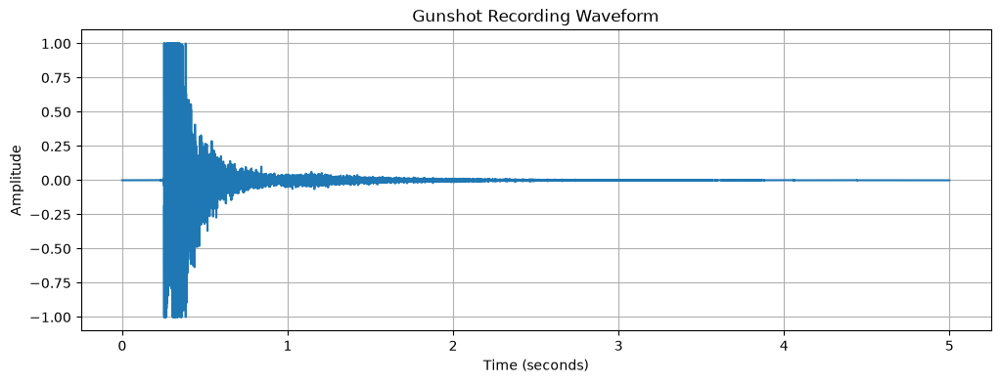

Recording duration: 5.0
Strongest peak at: 0.254 seconds
Peak amplitude: 1.0


In [71]:
import numpy as np
import soundfile as sf
import os
import matplotlib.pyplot as plt

# Use the gunshot recording from our earlier experiment
gunshot_path = os.path.join(
    audio_dir,
    "1-11101-11.wav"
)

# Select a gunshot using FSC22 metadata instead
gunshot_row = metadata[
    (metadata["fold"] == 2) &
    (metadata["target"] == 15)
].iloc[0]

gunshot_path = os.path.join(
    audio_dir,
    gunshot_row["filename"]
)

audio, sr = sf.read(gunshot_path)

if audio.ndim > 1:
    audio = audio.mean(axis=1)

time = np.arange(len(audio)) / sr

plt.figure(figsize=(12, 4))
plt.plot(time, audio)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Gunshot Recording Waveform")
plt.grid(True)
plt.show()

# Find the strongest audio peak
peak_index = np.argmax(np.abs(audio))
peak_time = peak_index / sr

print("Recording duration:", len(audio) / sr)
print("Strongest peak at:", round(peak_time, 3), "seconds")
print("Peak amplitude:", round(np.max(np.abs(audio)), 4))

In [72]:
import numpy as np
import soundfile as sf
import os

# Use the gunshot recording from the previous cell
# audio and sr should already be defined

# Find the strongest peak
peak_index = np.argmax(np.abs(audio))

# Extract a window around the gunshot
before = int(0.15 * sr)
after = int(1.5 * sr)

start = max(0, peak_index - before)
end = min(len(audio), peak_index + after)

gunshot_event = audio[start:end]

# Create shifted 5-second recordings
target_length = int(5 * sr)

timing_dir = os.path.join(
    augmentation_dir,
    "gunshot_timing_tests"
)

os.makedirs(timing_dir, exist_ok=True)

for event_start_sec in [0.0, 1.0, 2.0, 3.0]:

    shifted = np.zeros(target_length, dtype=np.float32)

    start_sample = int(event_start_sec * sr)

    available = target_length - start_sample
    event_part = gunshot_event[:available]

    shifted[
        start_sample:start_sample + len(event_part)
    ] = event_part

    filename = f"gunshot_shifted_{event_start_sec:.1f}s.wav"

    sf.write(
        os.path.join(timing_dir, filename),
        shifted,
        sr
    )

    print("Saved:", filename)

print("\nGunshot timing test recordings created!")

Saved: gunshot_shifted_0.0s.wav
Saved: gunshot_shifted_1.0s.wav
Saved: gunshot_shifted_2.0s.wav
Saved: gunshot_shifted_3.0s.wav

Gunshot timing test recordings created!


In [73]:
import os
import numpy as np
import soundfile as sf

# Test the original Fold 5 model
# baseline_model was loaded in our earlier comparison

class_names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

print("GUNSHOT TIMING EXPERIMENT")
print("-" * 65)

for event_start_sec in [0.0, 1.0, 2.0, 3.0]:

    filename = f"gunshot_shifted_{event_start_sec:.1f}s.wav"

    path = os.path.join(
        timing_dir,
        filename
    )

    # Load shifted gunshot recording
    test_audio, test_sr = sf.read(path)

    # Convert to Mel features using our existing function
    features = extract_augmented_mel(
        test_audio,
        test_sr
    )

    # Add batch dimension
    model_input = features[np.newaxis, ...]

    # Run original model
    probabilities = baseline_model.predict(
        model_input,
        verbose=0
    )[0]

    predicted_class = np.argmax(probabilities)

    print(f"\nGunshot starting at {event_start_sec:.1f} seconds")
    print(f"Background: {probabilities[0]*100:.2f}%")
    print(f"Chainsaw:   {probabilities[1]*100:.2f}%")
    print(f"Gunshot:    {probabilities[2]*100:.2f}%")
    print("Prediction:", class_names[predicted_class])

print("\nTiming experiment complete!")

GUNSHOT TIMING EXPERIMENT
-----------------------------------------------------------------

Gunshot starting at 0.0 seconds
Background: 86.60%
Chainsaw:   2.77%
Gunshot:    10.63%
Prediction: BACKGROUND

Gunshot starting at 1.0 seconds
Background: 71.84%
Chainsaw:   6.25%
Gunshot:    21.92%
Prediction: BACKGROUND

Gunshot starting at 2.0 seconds
Background: 0.54%
Chainsaw:   0.28%
Gunshot:    99.19%
Prediction: GUNSHOT

Gunshot starting at 3.0 seconds
Background: 0.00%
Chainsaw:   0.00%
Gunshot:    100.00%
Prediction: GUNSHOT

Timing experiment complete!


In [74]:
import os
import numpy as np
import soundfile as sf

# Use the previously loaded Fold 2 rain recording
# and four shifted gunshot recordings.

timing_noise_dir = os.path.join(
    augmentation_dir,
    "gunshot_timing_with_rain"
)

os.makedirs(timing_noise_dir, exist_ok=True)

# Load Fold 2 rain
rain_row = metadata[
    (metadata["fold"] == 2) &
    (metadata["target"] == 2)
].iloc[0]

rain_audio, rain_sr = sf.read(
    os.path.join(audio_dir, rain_row["filename"])
)

for start_sec in [0.0, 1.0, 2.0, 3.0]:

    filename = f"gunshot_shifted_{start_sec:.1f}s.wav"

    shifted_audio, shifted_sr = sf.read(
        os.path.join(timing_dir, filename)
    )

    assert shifted_sr == rain_sr

    # Mix shifted gunshot with rain
    mixed = mix_audio(
        shifted_audio,
        rain_audio,
        snr_db=10
    )

    # Ensure exactly 5 seconds
    mixed = librosa.util.fix_length(
        mixed,
        size=5 * rain_sr
    )

    output_filename = (
        f"gunshot_rain_shifted_{start_sec:.1f}s.wav"
    )

    sf.write(
        os.path.join(timing_noise_dir, output_filename),
        mixed,
        rain_sr
    )

    print("Saved:", output_filename)

print("\nAll four gunshot + rain timing tests created!")

Saved: gunshot_rain_shifted_0.0s.wav
Saved: gunshot_rain_shifted_1.0s.wav
Saved: gunshot_rain_shifted_2.0s.wav
Saved: gunshot_rain_shifted_3.0s.wav

All four gunshot + rain timing tests created!


In [75]:
import os
import numpy as np
import soundfile as sf

# Compare original and fine-tuned models
models_to_test = {
    "Original": baseline_model,
    "Fine-tuned": best_finetuned_model
}

class_names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

print("GUNSHOT + RAIN TIMING EXPERIMENT")
print("=" * 65)

for start_sec in [0.0, 1.0, 2.0, 3.0]:

    filename = f"gunshot_rain_shifted_{start_sec:.1f}s.wav"

    path = os.path.join(
        timing_noise_dir,
        filename
    )

    audio, sr = sf.read(path)

    # Convert to Mel spectrogram
    features = extract_augmented_mel(audio, sr)

    model_input = features[np.newaxis, ...]

    print(f"\nGUNSHOT AT {start_sec:.1f} SECONDS")
    print("-" * 45)

    for model_name, model in models_to_test.items():

        probs = model.predict(
            model_input,
            verbose=0
        )[0]

        predicted = class_names[np.argmax(probs)]

        print(
            f"{model_name:12s} | "
            f"Background: {probs[0]*100:5.1f}% | "
            f"Chainsaw: {probs[1]*100:5.1f}% | "
            f"Gunshot: {probs[2]*100:5.1f}% | "
            f"Predicted: {predicted}"
        )

print("\nExperiment complete!")

GUNSHOT + RAIN TIMING EXPERIMENT

GUNSHOT AT 0.0 SECONDS
---------------------------------------------
Original     | Background:  95.7% | Chainsaw:   2.8% | Gunshot:   1.6% | Predicted: BACKGROUND
Fine-tuned   | Background:  60.3% | Chainsaw:   5.4% | Gunshot:  34.3% | Predicted: BACKGROUND

GUNSHOT AT 1.0 SECONDS
---------------------------------------------
Original     | Background:  83.5% | Chainsaw:  14.1% | Gunshot:   2.4% | Predicted: BACKGROUND
Fine-tuned   | Background:  52.9% | Chainsaw:  22.7% | Gunshot:  24.4% | Predicted: BACKGROUND

GUNSHOT AT 2.0 SECONDS
---------------------------------------------
Original     | Background:  71.8% | Chainsaw:   5.8% | Gunshot:  22.4% | Predicted: BACKGROUND
Fine-tuned   | Background:   6.1% | Chainsaw:   2.3% | Gunshot:  91.5% | Predicted: GUNSHOT

GUNSHOT AT 3.0 SECONDS
---------------------------------------------
Original     | Background:  62.3% | Chainsaw:   6.2% | Gunshot:  31.5% | Predicted: BACKGROUND
Fine-tuned   | Background

In [76]:
import numpy as np

def randomize_gunshot_timing(
    audio,
    sr,
    rng=None,
    event_before=0.15,
    event_after=1.5
):
    if rng is None:
        rng = np.random.default_rng()

    audio = np.asarray(audio, dtype=np.float32)

    # Find the strongest transient
    peak_index = np.argmax(np.abs(audio))

    # Extract the event around the peak
    start = max(
        0,
        peak_index - int(event_before * sr)
    )

    end = min(
        len(audio),
        peak_index + int(event_after * sr)
    )

    event = audio[start:end]

    # Create a 5-second output recording
    target_length = int(5 * sr)
    output = np.zeros(target_length, dtype=np.float32)

    # Randomly position the complete event
    max_start = target_length - len(event)

    if max_start < 0:
        raise ValueError("Gunshot event exceeds 5 seconds")

    new_start = int(rng.integers(0, max_start + 1))

    output[new_start:new_start + len(event)] = event

    return output, new_start / sr


# Test using the previously loaded gunshot recording
rng = np.random.default_rng(42)

for i in range(5):
    shifted, start_time = randomize_gunshot_timing(
        gunshot,
        sr,
        rng=rng
    )

    print(
        f"Example {i+1}: "
        f"gunshot begins at {start_time:.2f} seconds"
    )

Example 1: gunshot begins at 0.30 seconds
Example 2: gunshot begins at 2.59 seconds
Example 3: gunshot begins at 2.19 seconds
Example 4: gunshot begins at 1.47 seconds
Example 5: gunshot begins at 1.45 seconds


In [78]:

import os
import numpy as np
import pandas as pd
import soundfile as sf
import librosa

# ==========================================
# 1. Create output directory
# ==========================================

gunshot_aug_dir = os.path.join(
    augmentation_dir,
    "gunshot_timing_aug_v1"
)

os.makedirs(gunshot_aug_dir, exist_ok=True)

# Reproducible random generator
rng = np.random.default_rng(123)

# Signal-to-noise ratios
snr_levels = [10, 5, 0, -5]

# ==========================================
# 2. Select Fold 2 source recordings
# ==========================================

# Gunshot recordings: FSC22 class 15
gunshot_meta = metadata[
    (metadata["fold"] == 2) &
    (metadata["target"] == 15)
]

# Rainforest background recordings
background_meta_fold2 = metadata[
    (metadata["fold"] == 2) &
    (metadata["target"].isin(background_categories.keys()))
]

print("Available gunshots:", len(gunshot_meta))
print("Available backgrounds:", len(background_meta_fold2))

assert len(gunshot_meta) > 0
assert len(background_meta_fold2) > 0

# ==========================================
# 3. Generate 20 randomized mixtures
# ==========================================

records_timing = []

for i in range(20):

    # Select a random gunshot recording
    gunshot_row = gunshot_meta.iloc[
        int(rng.integers(len(gunshot_meta)))
    ]

    # Select a random rainforest background
    bg_row = background_meta_fold2.iloc[
        int(rng.integers(len(background_meta_fold2)))
    ]

    # Load gunshot
    gunshot_audio, gunshot_sr = sf.read(
        os.path.join(
            audio_dir,
            gunshot_row["filename"]
        )
    )

    # Load background
    bg_audio, bg_sr = sf.read(
        os.path.join(
            audio_dir,
            bg_row["filename"]
        )
    )

    assert gunshot_sr == bg_sr, "Sample rates do not match"

    # Convert stereo to mono if necessary
    if gunshot_audio.ndim > 1:
        gunshot_audio = gunshot_audio.mean(axis=1)

    if bg_audio.ndim > 1:
        bg_audio = bg_audio.mean(axis=1)

    # Randomize gunshot timing
    shifted, start_time = randomize_gunshot_timing(
        gunshot_audio,
        gunshot_sr,
        rng=rng
    )

    # Ensure background is exactly 5 seconds
    bg_audio = librosa.util.fix_length(
        bg_audio,
        size=5 * bg_sr
    )

    # Select random SNR
    snr_db = int(rng.choice(snr_levels))

    # Mix gunshot and rainforest background
    mixed = mix_audio(
        shifted,
        bg_audio,
        snr_db
    )

    # Ensure exactly 5 seconds
    mixed = librosa.util.fix_length(
        mixed,
        size=5 * gunshot_sr
    )

    # Validate audio
    assert np.isfinite(mixed).all()
    assert len(mixed) == 5 * gunshot_sr
    assert np.max(np.abs(mixed)) <= 1.0

    # Create filename
    filename = f"gunshot_aug_{i+1:03d}.wav"

    output_path = os.path.join(
        gunshot_aug_dir,
        filename
    )

    # Save WAV file
    sf.write(
        output_path,
        mixed,
        gunshot_sr
    )

    # Save metadata
    records_timing.append({
        "filename": filename,
        "gunshot_source": gunshot_row["filename"],
        "background_source": bg_row["filename"],
        "start_time": start_time,
        "snr_db": snr_db,
        "fold": 2,
        "label": "gunshot"
    })

    print(
        f"{filename} | "
        f"Start: {start_time:.2f}s | "
        f"SNR: {snr_db:+d} dB"
    )

# ==========================================
# 4. Save metadata
# ==========================================

timing_metadata = pd.DataFrame(records_timing)

metadata_path = os.path.join(
    gunshot_aug_dir,
    "gunshot_timing_metadata.csv"
)

timing_metadata.to_csv(
    metadata_path,
    index=False
)

# ==========================================
# 5. Final verification
# ==========================================

print("\n" + "=" * 50)
print("SUCCESS: Gunshot timing augmentation complete!")
print("Total recordings:", len(records_timing))
print("Output directory:", gunshot_aug_dir)

print("\nSNR distribution:")
print(timing_metadata["snr_db"].value_counts().sort_index())

print("\nGunshot start times:")
print(timing_metadata["start_time"].round(2).tolist())

print("\nAll 20 recordings saved successfully!")


Available gunshots: 15
Available backgrounds: 120
gunshot_aug_001.wav | Start: 1.99s | SNR: +10 dB
gunshot_aug_002.wav | Start: 0.89s | SNR: +10 dB
gunshot_aug_003.wav | Start: 1.18s | SNR: -5 dB
gunshot_aug_004.wav | Start: 1.51s | SNR: +5 dB
gunshot_aug_005.wav | Start: 2.89s | SNR: -5 dB
gunshot_aug_006.wav | Start: 0.90s | SNR: +10 dB
gunshot_aug_007.wav | Start: 2.71s | SNR: +10 dB
gunshot_aug_008.wav | Start: 0.50s | SNR: +0 dB
gunshot_aug_009.wav | Start: 2.48s | SNR: +10 dB
gunshot_aug_010.wav | Start: 0.73s | SNR: +0 dB
gunshot_aug_011.wav | Start: 0.82s | SNR: +10 dB
gunshot_aug_012.wav | Start: 0.05s | SNR: +0 dB
gunshot_aug_013.wav | Start: 1.21s | SNR: +10 dB
gunshot_aug_014.wav | Start: 0.26s | SNR: +0 dB
gunshot_aug_015.wav | Start: 0.58s | SNR: +0 dB
gunshot_aug_016.wav | Start: 2.15s | SNR: -5 dB
gunshot_aug_017.wav | Start: 0.63s | SNR: -5 dB
gunshot_aug_018.wav | Start: 1.80s | SNR: +5 dB
gunshot_aug_019.wav | Start: 1.52s | SNR: -5 dB
gunshot_aug_020.wav | Start: 1.


File: gunshot_aug_001.wav
Gunshot start: 1.99 seconds
SNR: 10 dB
Duration: 5.0 seconds
Peak amplitude: 0.99


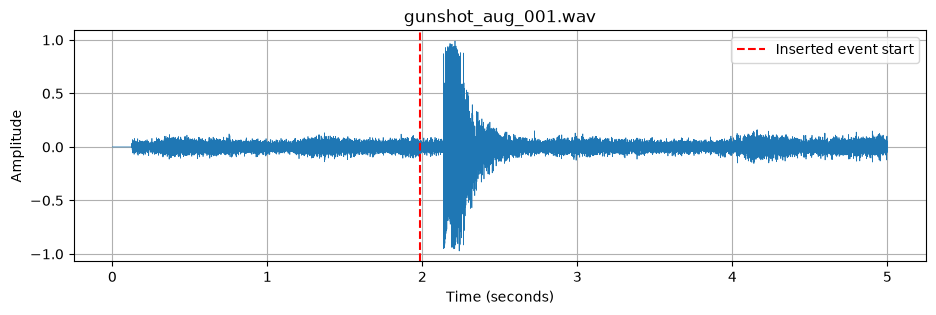


File: gunshot_aug_006.wav
Gunshot start: 0.9 seconds
SNR: 10 dB
Duration: 5.0 seconds
Peak amplitude: 0.99


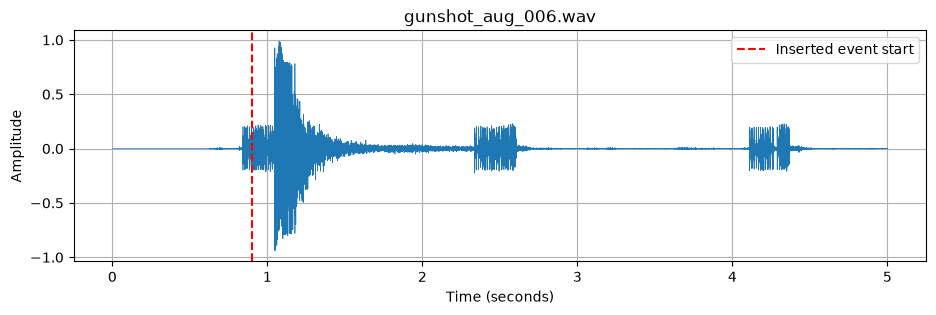


File: gunshot_aug_010.wav
Gunshot start: 0.73 seconds
SNR: 0 dB
Duration: 5.0 seconds
Peak amplitude: 0.99


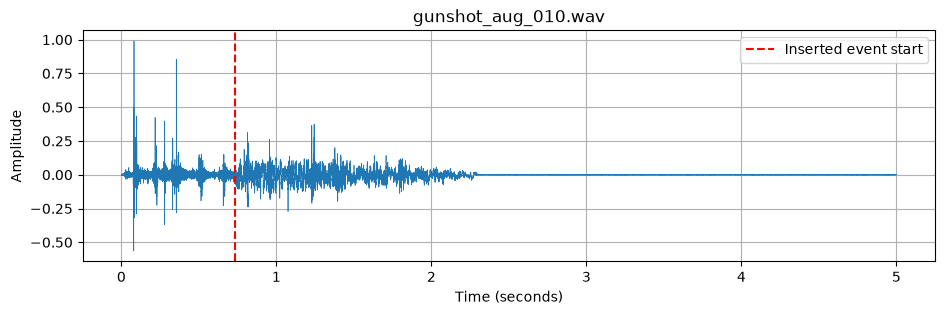


File: gunshot_aug_012.wav
Gunshot start: 0.05 seconds
SNR: 0 dB
Duration: 5.0 seconds
Peak amplitude: 0.99


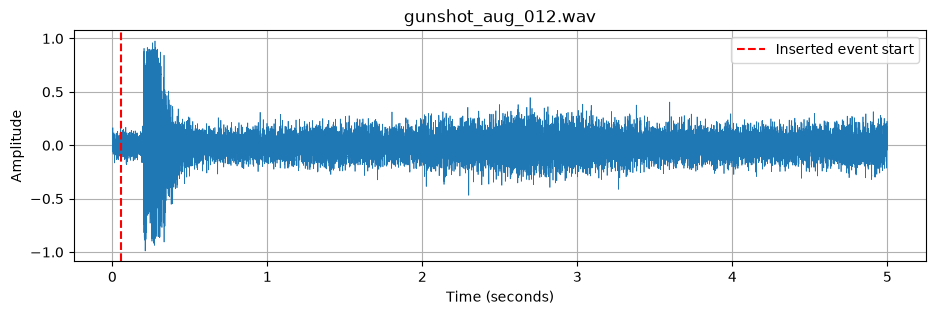


File: gunshot_aug_020.wav
Gunshot start: 1.76 seconds
SNR: 0 dB
Duration: 5.0 seconds
Peak amplitude: 0.99


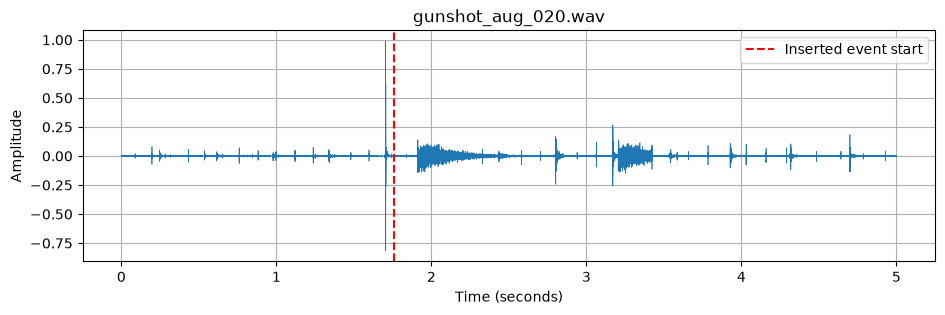


Audio inspection complete!


In [79]:

import os
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Select examples with different gunshot positions
test_indices = [0, 5, 9, 11, 19]

for i in test_indices:

    row = timing_metadata.iloc[i]

    path = os.path.join(
        gunshot_aug_dir,
        row["filename"]
    )

    audio, sr = sf.read(path)

    print("\n" + "=" * 50)
    print("File:", row["filename"])
    print("Gunshot start:", round(row["start_time"], 2), "seconds")
    print("SNR:", row["snr_db"], "dB")
    print("Duration:", round(len(audio) / sr, 3), "seconds")
    print("Peak amplitude:", round(np.max(np.abs(audio)), 4))

    # Play recording
    display(Audio(audio, rate=sr, normalize=False))

    # Plot waveform
    time = np.arange(len(audio)) / sr

    plt.figure(figsize=(11, 3))
    plt.plot(time, audio, linewidth=0.5)
    plt.axvline(
        row["start_time"],
        color="red",
        linestyle="--",
        label="Inserted event start"
    )
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.title(row["filename"])
    plt.legend()
    plt.grid(True)
    plt.show()

print("\nAudio inspection complete!")


In [80]:

import os
import numpy as np
import pandas as pd
import soundfile as sf

# Models already loaded in our notebook
models_to_test = {
    "Original": baseline_model,
    "Fine-tuned": best_finetuned_model
}

results = []

for _, row in timing_metadata.iterrows():

    path = os.path.join(
        gunshot_aug_dir,
        row["filename"]
    )

    audio, sr = sf.read(path)

    # Convert to the original three-channel Mel format
    features = extract_augmented_mel(audio, sr)
    model_input = features[np.newaxis, ...]

    result = {
        "filename": row["filename"],
        "start_time": row["start_time"],
        "snr_db": row["snr_db"]
    }

    for model_name, model in models_to_test.items():

        probs = model.predict(
            model_input,
            verbose=0
        )[0]

        result[f"{model_name}_gunshot_prob"] = float(probs[2])
        result[f"{model_name}_detected"] = (
            int(np.argmax(probs)) == 2
        )

    results.append(result)

timing_results = pd.DataFrame(results)

print("GUNSHOT TIMING + RAINFOREST NOISE RESULTS")
print("=" * 55)

for model_name in models_to_test:

    detected = timing_results[f"{model_name}_detected"].sum()

    print(
        f"{model_name}: "
        f"{detected}/20 detected "
        f"({detected/20*100:.1f}%)"
    )

print("\nDETECTION BY GUNSHOT START TIME")

timing_results["time_group"] = pd.cut(
    timing_results["start_time"],
    bins=[0, 1, 2, 3.5],
    labels=["Early (0-1s)", "Middle (1-2s)", "Late (2-3.5s)"],
    include_lowest=True
)

print(
    timing_results.groupby("time_group", observed=True)[
        ["Original_detected", "Fine-tuned_detected"]
    ].agg(["sum", "count", "mean"])
)

print("\nINDIVIDUAL RESULTS")
print(
    timing_results[
        [
            "filename",
            "start_time",
            "snr_db",
            "Original_gunshot_prob",
            "Fine-tuned_gunshot_prob"
        ]
    ].round(3).to_string(index=False)
)


GUNSHOT TIMING + RAINFOREST NOISE RESULTS
Original: 11/20 detected (55.0%)
Fine-tuned: 16/20 detected (80.0%)

DETECTION BY GUNSHOT START TIME
              Original_detected                 Fine-tuned_detected        \
                            sum count      mean                 sum count   
time_group                                                                  
Early (0-1s)                  2     9  0.222222                   6     9   
Middle (1-2s)                 6     7  0.857143                   6     7   
Late (2-3.5s)                 3     4  0.750000                   4     4   

                         
                   mean  
time_group               
Early (0-1s)   0.666667  
Middle (1-2s)  0.857143  
Late (2-3.5s)  1.000000  

INDIVIDUAL RESULTS
           filename  start_time  snr_db  Original_gunshot_prob  Fine-tuned_gunshot_prob
gunshot_aug_001.wav       1.986      10                  0.489                    0.975
gunshot_aug_002.wav       0.889      10   

In [81]:

# Identify gunshot recordings missed by the fine-tuned model

missed = timing_results[
    ~timing_results["Fine-tuned_detected"]
].copy()

print("MISSED GUNSHOT RECORDINGS")
print("=" * 65)

print(
    missed[
        [
            "filename",
            "start_time",
            "snr_db",
            "Original_gunshot_prob",
            "Fine-tuned_gunshot_prob"
        ]
    ].round(3).to_string(index=False)
)

print("\nTotal missed:", len(missed))

# Show source recordings for each missed example
missed_sources = missed.merge(
    timing_metadata[
        ["filename", "gunshot_source", "background_source"]
    ],
    on="filename",
    how="left"
)

print("\nSOURCE RECORDINGS")
print(
    missed_sources[
        [
            "filename",
            "gunshot_source",
            "background_source"
        ]
    ].to_string(index=False)
)


MISSED GUNSHOT RECORDINGS
           filename  start_time  snr_db  Original_gunshot_prob  Fine-tuned_gunshot_prob
gunshot_aug_006.wav       0.898      10                  0.262                    0.343
gunshot_aug_008.wav       0.497       0                  0.044                    0.150
gunshot_aug_017.wav       0.634      -5                  0.080                    0.109
gunshot_aug_020.wav       1.761       0                  0.032                    0.018

Total missed: 4

SOURCE RECORDINGS
           filename gunshot_source background_source
gunshot_aug_006.wav 2-11502-15.wav    2-12207-21.wav
gunshot_aug_008.wav 2-11532-15.wav    2-12367-22.wav
gunshot_aug_017.wav 2-11532-15.wav     2-10357-3.wav
gunshot_aug_020.wav 2-11572-15.wav     2-10427-4.wav


In [82]:

import os
import numpy as np
import soundfile as sf
from IPython.display import Audio, display

# The four gunshots missed by the fine-tuned model
missed_files = [
    "gunshot_aug_006.wav",
    "gunshot_aug_008.wav",
    "gunshot_aug_017.wav",
    "gunshot_aug_020.wav"
]

for filename in missed_files:

    row = timing_metadata[
        timing_metadata["filename"] == filename
    ].iloc[0]

    original_path = os.path.join(
        audio_dir,
        row["gunshot_source"]
    )

    augmented_path = os.path.join(
        gunshot_aug_dir,
        filename
    )

    original_audio, original_sr = sf.read(original_path)
    augmented_audio, augmented_sr = sf.read(augmented_path)

    print("\n" + "=" * 55)
    print("Recording:", filename)
    print("Original gunshot:", row["gunshot_source"])
    print("Background:", row["background_source"])
    print("Gunshot start:", round(row["start_time"], 2), "seconds")
    print("SNR:", row["snr_db"], "dB")

    print("\nORIGINAL GUNSHOT:")
    display(Audio(original_audio, rate=original_sr, normalize=False))

    print("AUGMENTED GUNSHOT + RAINFOREST NOISE:")
    display(Audio(augmented_audio, rate=augmented_sr, normalize=False))

print("\nListening comparison ready!")



Recording: gunshot_aug_006.wav
Original gunshot: 2-11502-15.wav
Background: 2-12207-21.wav
Gunshot start: 0.9 seconds
SNR: 10 dB

ORIGINAL GUNSHOT:


AUGMENTED GUNSHOT + RAINFOREST NOISE:



Recording: gunshot_aug_008.wav
Original gunshot: 2-11532-15.wav
Background: 2-12367-22.wav
Gunshot start: 0.5 seconds
SNR: 0 dB

ORIGINAL GUNSHOT:


AUGMENTED GUNSHOT + RAINFOREST NOISE:



Recording: gunshot_aug_017.wav
Original gunshot: 2-11532-15.wav
Background: 2-10357-3.wav
Gunshot start: 0.63 seconds
SNR: -5 dB

ORIGINAL GUNSHOT:


AUGMENTED GUNSHOT + RAINFOREST NOISE:



Recording: gunshot_aug_020.wav
Original gunshot: 2-11572-15.wav
Background: 2-10427-4.wav
Gunshot start: 1.76 seconds
SNR: 0 dB

ORIGINAL GUNSHOT:


AUGMENTED GUNSHOT + RAINFOREST NOISE:



Listening comparison ready!


In [84]:

import numpy as np

# Event-aware gunshot + rainforest noise mixing function

def mix_gunshot_event_aware(
    shifted_gunshot,
    background_audio,
    snr_db,
    event_start,
    event_duration=1.65,
    sr=44100
):
    # Convert audio to float32
    gunshot = np.asarray(
        shifted_gunshot, dtype=np.float32
    )

    background = np.asarray(
        background_audio, dtype=np.float32
    )

    # Match recording lengths
    target_length = min(len(gunshot), len(background))

    gunshot = gunshot[:target_length]
    background = background[:target_length]

    # Identify the inserted gunshot event
    start = int(round(event_start * sr))

    end = min(
        start + int(round(event_duration * sr)),
        target_length
    )

    if start < 0 or start >= end:
        raise ValueError("Invalid gunshot event interval")

    gunshot_event = gunshot[start:end]
    background_event = background[start:end]

    # Calculate RMS loudness
    def rms(x):
        return np.sqrt(
            np.mean(np.asarray(x, dtype=np.float64) ** 2)
        )

    gunshot_rms = rms(gunshot_event)
    background_rms = rms(background_event)

    if gunshot_rms < 1e-8 or background_rms < 1e-8:
        raise ValueError("Gunshot or background is too quiet")

    # Scale background to the desired event-aware SNR
    background_scale = (
        gunshot_rms / background_rms
    ) * (10 ** (-snr_db / 20))

    # Mix gunshot with rainforest background
    mixed = gunshot + background * background_scale

    # Prevent clipping by scaling the entire mixture
    peak = np.max(np.abs(mixed))

    if peak > 0.99:
        mixed = mixed * (0.99 / peak)

    return mixed.astype(np.float32)


print("SUCCESS: Event-aware gunshot mixing function ready!")


SUCCESS: Event-aware gunshot mixing function ready!


In [85]:

import os
import numpy as np
import soundfile as sf
import librosa
from IPython.display import Audio, display

# Select a Fold 2 gunshot and rainforest background
gunshot_row = gunshot_meta.iloc[0]
bg_row = background_meta_fold2.iloc[0]

gunshot_audio, sr = sf.read(
    os.path.join(audio_dir, gunshot_row["filename"])
)

background_audio, bg_sr = sf.read(
    os.path.join(audio_dir, bg_row["filename"])
)

assert sr == bg_sr

if gunshot_audio.ndim > 1:
    gunshot_audio = gunshot_audio.mean(axis=1)

if background_audio.ndim > 1:
    background_audio = background_audio.mean(axis=1)

background_audio = librosa.util.fix_length(
    background_audio,
    size=5 * sr
)

# Randomize gunshot position
rng = np.random.default_rng(42)

shifted, start_time = randomize_gunshot_timing(
    gunshot_audio,
    sr,
    rng=rng
)

# Create mixtures at different event-aware SNRs
event_aware_test_dir = os.path.join(
    augmentation_dir,
    "gunshot_event_aware_tests"
)

os.makedirs(event_aware_test_dir, exist_ok=True)

for snr_db in [10, 0, -5]:

    mixed = mix_gunshot_event_aware(
        shifted,
        background_audio,
        snr_db=snr_db,
        event_start=start_time,
        sr=sr
    )

    filename = f"gunshot_event_aware_{snr_db:+d}dB.wav"

    sf.write(
        os.path.join(event_aware_test_dir, filename),
        mixed,
        sr
    )

    print(f"\nEvent-aware SNR: {snr_db:+d} dB")
    print("Gunshot start:", round(start_time, 2), "seconds")
    print("Peak amplitude:", round(np.max(np.abs(mixed)), 3))

    display(Audio(mixed, rate=sr, normalize=False))

print("\nSUCCESS: Event-aware mixtures created!")



Event-aware SNR: +10 dB
Gunshot start: 0.3 seconds
Peak amplitude: 0.99



Event-aware SNR: +0 dB
Gunshot start: 0.3 seconds
Peak amplitude: 0.99



Event-aware SNR: -5 dB
Gunshot start: 0.3 seconds
Peak amplitude: 0.99



SUCCESS: Event-aware mixtures created!


In [86]:

import os
import numpy as np
import soundfile as sf

# Compare original and fine-tuned models
models_to_test = {
    "Original": baseline_model,
    "Fine-tuned": best_finetuned_model
}

class_names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

print("EVENT-AWARE GUNSHOT DETECTION TEST")
print("=" * 65)

for snr_db in [10, 0, -5]:

    filename = f"gunshot_event_aware_{snr_db:+d}dB.wav"

    path = os.path.join(
        event_aware_test_dir,
        filename
    )

    # Load augmented recording
    audio, sr = sf.read(path)

    # Convert to Mel spectrogram
    features = extract_augmented_mel(audio, sr)

    model_input = features[np.newaxis, ...]

    print(f"\nEVENT-AWARE SNR: {snr_db:+d} dB")
    print("-" * 55)

    for model_name, model in models_to_test.items():

        probabilities = model.predict(
            model_input,
            verbose=0
        )[0]

        predicted_class = np.argmax(probabilities)

        print(
            f"{model_name:12s} | "
            f"Background: {probabilities[0]*100:5.1f}% | "
            f"Chainsaw: {probabilities[1]*100:5.1f}% | "
            f"Gunshot: {probabilities[2]*100:5.1f}% | "
            f"Predicted: {class_names[predicted_class]}"
        )

print("\nEvent-aware detection test complete!")


EVENT-AWARE GUNSHOT DETECTION TEST

EVENT-AWARE SNR: +10 dB
-------------------------------------------------------
Original     | Background:  78.9% | Chainsaw:  11.3% | Gunshot:   9.8% | Predicted: BACKGROUND
Fine-tuned   | Background:  13.5% | Chainsaw:  46.5% | Gunshot:  40.0% | Predicted: CHAINSAW

EVENT-AWARE SNR: +0 dB
-------------------------------------------------------
Original     | Background:  89.9% | Chainsaw:   2.3% | Gunshot:   7.9% | Predicted: BACKGROUND
Fine-tuned   | Background:  71.4% | Chainsaw:  17.5% | Gunshot:  11.1% | Predicted: BACKGROUND

EVENT-AWARE SNR: -5 dB
-------------------------------------------------------
Original     | Background:  87.4% | Chainsaw:   2.4% | Gunshot:  10.2% | Predicted: BACKGROUND
Fine-tuned   | Background:  58.4% | Chainsaw:  25.9% | Gunshot:  15.6% | Predicted: BACKGROUND

Event-aware detection test complete!


In [1]:

import os

project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

# Check important saved directories
paths = {
    "Original trained models": os.path.join(
        project_dir,
        "models",
        "MobileNetV3_Small_Rainforest_3Class_BN09"
    ),
    "Augmented V1 model": os.path.join(
        project_dir,
        "models",
        "MobileNetV3_Small_Rainforest_Augmented_V1"
    ),
    "Fine-tuned V1 model": os.path.join(
        project_dir,
        "models",
        "MobileNetV3_Small_Rainforest_Finetuned_V1"
    ),
    "Augmented Mel features": os.path.join(
        project_dir,
        "datasets",
        "fsc22_augmented",
        "mel_features_v1"
    ),
    "Gunshot timing augmentation": os.path.join(
        project_dir,
        "datasets",
        "fsc22_augmented",
        "gunshot_timing_aug_v1"
    ),
    "Event-aware gunshot tests": os.path.join(
        project_dir,
        "datasets",
        "fsc22_augmented",
        "gunshot_event_aware_tests"
    )
}

print("RAINFOREST ML PROJECT FILE CHECK")
print("=" * 50)

for name, path in paths.items():
    exists = os.path.isdir(path)
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

print("\nFile verification complete!")


RAINFOREST ML PROJECT FILE CHECK
Original trained models: FOUND
Augmented V1 model: FOUND
Fine-tuned V1 model: FOUND
Augmented Mel features: FOUND
Gunshot timing augmentation: FOUND
Event-aware gunshot tests: FOUND

File verification complete!


In [2]:

import os

# Project directory
project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

# Original FSC22 audio recordings
audio_dir = os.path.join(
    project_dir, "datasets", "fsc22", "fsc22", "wav44"
)

# Augmentation directory
augmentation_dir = os.path.join(
    project_dir, "datasets", "fsc22_augmented"
)

# Original trained model
baseline_path = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_3Class_BN09",
    "MobileNetV3_Small_Rainforest_3Class_BN09_base_fold5.keras"
)

# Fine-tuned V1 model
finetuned_path = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_Finetuned_V1",
    "MobileNetV3_Finetuned_V1_best.keras"
)

# Augmented-from-scratch V1 model
augmented_v1_path = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_Augmented_V1",
    "MobileNetV3_Augmented_V1_best.keras"
)

print("PROJECT FILE VERIFICATION")
print("=" * 50)

files_to_check = {
    "Original audio directory": audio_dir,
    "Augmentation directory": augmentation_dir,
    "Original Fold 5 model": baseline_path,
    "Fine-tuned V1 model": finetuned_path,
    "Augmented V1 model": augmented_v1_path
}

for name, path in files_to_check.items():
    exists = os.path.exists(path)
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

print("\nVerification complete!")


PROJECT FILE VERIFICATION
Original audio directory: FOUND
Augmentation directory: FOUND
Original Fold 5 model: FOUND
Fine-tuned V1 model: FOUND
Augmented V1 model: FOUND

Verification complete!


In [3]:

import os
import pandas as pd

# Restore FSC22 metadata
metadata_path = os.path.join(
    project_dir,
    "datasets",
    "fsc22",
    "fsc22",
    "FSC22.csv"
)

metadata = pd.read_csv(metadata_path)

# Background categories used in our experiments
background_categories = {
    2: "Rain",
    3: "Thunderstorm",
    4: "Water drops",
    5: "Wind",
    21: "Insects",
    22: "Frogs",
    23: "Bird chirping",
    24: "Wing flapping"
}

# Select training and validation source recordings
train_metadata_v2 = metadata[
    metadata["fold"].isin([2, 3, 4])
].copy()

val_metadata_v2 = metadata[
    metadata["fold"] == 5
].copy()

print("V2 DATASET VERIFICATION")
print("=" * 50)

print("Total FSC22 recordings:", len(metadata))
print("Training source recordings:", len(train_metadata_v2))
print("Validation source recordings:", len(val_metadata_v2))

print("\nTraining gunshots:",
      sum(train_metadata_v2["target"] == 15))

print("Training chainsaws:",
      sum(train_metadata_v2["target"] == 11))

print("Training backgrounds:",
      sum(train_metadata_v2["target"].isin(background_categories)))

print("\nOverlapping filenames:",
      len(
          set(train_metadata_v2["filename"]) &
          set(val_metadata_v2["filename"])
      ))

assert len(metadata) == 1950
assert len(train_metadata_v2) == 1170
assert len(val_metadata_v2) == 390

print("\nSUCCESS: V2 source split verified!")


V2 DATASET VERIFICATION
Total FSC22 recordings: 1950
Training source recordings: 1170
Validation source recordings: 390

Training gunshots: 45
Training chainsaws: 45
Training backgrounds: 360

Overlapping filenames: 0

SUCCESS: V2 source split verified!


In [4]:

import numpy as np

# ==========================================
# FUNCTION 1: Randomize gunshot timing
# ==========================================

def randomize_gunshot_timing(
    audio,
    sr,
    rng=None,
    event_before=0.15,
    event_after=1.5
):
    if rng is None:
        rng = np.random.default_rng()

    audio = np.asarray(audio, dtype=np.float32)

    # Find strongest transient
    peak_index = np.argmax(np.abs(audio))

    # Extract event around the peak
    start = max(
        0,
        peak_index - int(event_before * sr)
    )

    end = min(
        len(audio),
        peak_index + int(event_after * sr)
    )

    event = audio[start:end]

    # Create 5-second output
    target_length = int(5 * sr)
    output = np.zeros(target_length, dtype=np.float32)

    max_start = target_length - len(event)

    if max_start < 0:
        raise ValueError("Gunshot event exceeds 5 seconds")

    new_start = int(rng.integers(0, max_start + 1))

    output[new_start:new_start + len(event)] = event

    return output, new_start / sr


# ==========================================
# FUNCTION 2: Event-aware audio mixing
# ==========================================

def mix_gunshot_event_aware(
    shifted_gunshot,
    background_audio,
    snr_db,
    event_start,
    event_duration=1.65,
    sr=44100
):
    gunshot = np.asarray(
        shifted_gunshot, dtype=np.float32
    )

    background = np.asarray(
        background_audio, dtype=np.float32
    )

    # Match lengths
    target_length = min(len(gunshot), len(background))

    gunshot = gunshot[:target_length]
    background = background[:target_length]

    # Identify gunshot event
    start = int(round(event_start * sr))

    end = min(
        start + int(round(event_duration * sr)),
        target_length
    )

    if start < 0 or start >= end:
        raise ValueError("Invalid gunshot event interval")

    gunshot_event = gunshot[start:end]
    background_event = background[start:end]

    def rms(x):
        return np.sqrt(
            np.mean(np.asarray(x, dtype=np.float64) ** 2)
        )

    gunshot_rms = rms(gunshot_event)
    background_rms = rms(background_event)

    if gunshot_rms < 1e-8 or background_rms < 1e-8:
        raise ValueError("Gunshot or background is too quiet")

    # Set event-aware SNR
    background_scale = (
        gunshot_rms / background_rms
    ) * (10 ** (-snr_db / 20))

    mixed = gunshot + background * background_scale

    # Prevent clipping
    peak = np.max(np.abs(mixed))

    if peak > 0.99:
        mixed = mixed * (0.99 / peak)

    return mixed.astype(np.float32)


# ==========================================
# VERIFY BOTH FUNCTIONS
# ==========================================

print("Gunshot timing function:",
      callable(randomize_gunshot_timing))

print("Event-aware mixing function:",
      callable(mix_gunshot_event_aware))

print("\nSUCCESS: V2 augmentation functions restored!")


Gunshot timing function: True
Event-aware mixing function: True

SUCCESS: V2 augmentation functions restored!


In [5]:

import os
import numpy as np
import pandas as pd
import soundfile as sf
import librosa

# Create separate V2 test directory
v2_test_dir = os.path.join(
    augmentation_dir,
    "gunshot_event_aware_v2_test"
)

os.makedirs(v2_test_dir, exist_ok=True)

rng_v2 = np.random.default_rng(2026)

snr_levels_v2 = [10, 5, 0, -5]

# Only use training folds 2, 3, and 4
gunshot_sources = train_metadata_v2[
    train_metadata_v2["target"] == 15
]

background_sources = train_metadata_v2[
    train_metadata_v2["target"].isin(
        background_categories.keys()
    )
]

v2_records = []

for i in range(12):

    # Randomly select a gunshot
    gunshot_row = gunshot_sources.iloc[
        int(rng_v2.integers(len(gunshot_sources)))
    ]

    # Randomly select rainforest background
    bg_row = background_sources.iloc[
        int(rng_v2.integers(len(background_sources)))
    ]

    # Load source recordings
    gunshot_audio, sr = sf.read(
        os.path.join(audio_dir, gunshot_row["filename"])
    )

    background_audio, bg_sr = sf.read(
        os.path.join(audio_dir, bg_row["filename"])
    )

    assert sr == bg_sr, "Sample rates do not match"

    # Convert stereo to mono if necessary
    if gunshot_audio.ndim > 1:
        gunshot_audio = gunshot_audio.mean(axis=1)

    if background_audio.ndim > 1:
        background_audio = background_audio.mean(axis=1)

    # Ensure background is exactly 5 seconds
    background_audio = librosa.util.fix_length(
        background_audio.astype(np.float32),
        size=5 * sr
    )

    # Randomize gunshot position
    shifted, start_time = randomize_gunshot_timing(
        gunshot_audio,
        sr,
        rng=rng_v2
    )

    # Choose SNR, cycling through all four levels
    snr_db = snr_levels_v2[i % len(snr_levels_v2)]

    # Mix using event-aware SNR
    mixed = mix_gunshot_event_aware(
        shifted,
        background_audio,
        snr_db=snr_db,
        event_start=start_time,
        sr=sr
    )

    assert len(mixed) == 5 * sr
    assert np.isfinite(mixed).all()
    assert np.max(np.abs(mixed)) <= 1.0

    # Save WAV file
    filename = f"gunshot_v2_test_{i+1:03d}.wav"

    sf.write(
        os.path.join(v2_test_dir, filename),
        mixed,
        sr
    )

    # Preserve source metadata
    v2_records.append({
        "filename": filename,
        "gunshot_source": gunshot_row["filename"],
        "background_source": bg_row["filename"],
        "gunshot_fold": int(gunshot_row["fold"]),
        "background_fold": int(bg_row["fold"]),
        "start_time": start_time,
        "snr_db": snr_db,
        "label": "gunshot"
    })

    print(
        f"{filename} | "
        f"Start: {start_time:.2f}s | "
        f"SNR: {snr_db:+d} dB"
    )

# Save metadata
v2_metadata = pd.DataFrame(v2_records)

v2_metadata.to_csv(
    os.path.join(v2_test_dir, "v2_test_metadata.csv"),
    index=False
)

print("\nSUCCESS: 12 V2 test recordings created!")
print("Total:", len(v2_metadata))
print("SNR distribution:")
print(v2_metadata["snr_db"].value_counts().sort_index())


gunshot_v2_test_001.wav | Start: 0.09s | SNR: +10 dB
gunshot_v2_test_002.wav | Start: 1.63s | SNR: +5 dB
gunshot_v2_test_003.wav | Start: 2.20s | SNR: +0 dB
gunshot_v2_test_004.wav | Start: 2.76s | SNR: -5 dB
gunshot_v2_test_005.wav | Start: 2.63s | SNR: +10 dB
gunshot_v2_test_006.wav | Start: 2.27s | SNR: +5 dB
gunshot_v2_test_007.wav | Start: 0.55s | SNR: +0 dB
gunshot_v2_test_008.wav | Start: 3.08s | SNR: -5 dB
gunshot_v2_test_009.wav | Start: 2.08s | SNR: +10 dB
gunshot_v2_test_010.wav | Start: 1.97s | SNR: +5 dB
gunshot_v2_test_011.wav | Start: 2.20s | SNR: +0 dB
gunshot_v2_test_012.wav | Start: 1.14s | SNR: -5 dB

SUCCESS: 12 V2 test recordings created!
Total: 12
SNR distribution:
snr_db
-5     3
 0     3
 5     3
 10    3
Name: count, dtype: int64


In [6]:

import os
import numpy as np
import soundfile as sf

print("V2 AUDIO VERIFICATION")
print("=" * 60)

valid_count = 0
issues = []

for _, row in v2_metadata.iterrows():

    path = os.path.join(v2_test_dir, row["filename"])

    if not os.path.isfile(path):
        issues.append((row["filename"], "Missing file"))
        continue

    audio, sr = sf.read(path)

    duration = len(audio) / sr
    peak = np.max(np.abs(audio))
    finite = np.isfinite(audio).all()

    valid = (
        sr == 44100
        and len(audio) == 220500
        and finite
        and peak <= 1.0
    )

    if valid:
        valid_count += 1
    else:
        issues.append((row["filename"], "Invalid audio"))

    print(
        f"{row['filename']} | "
        f"Duration: {duration:.3f}s | "
        f"Peak: {peak:.3f} | "
        f"Valid: {valid}"
    )

print("\nValid recordings:", valid_count)
print("Invalid recordings:", len(issues))

if issues:
    print("Issues:", issues)

assert valid_count == 12, "Some recordings need attention"

print("\nSUCCESS: All 12 V2 recordings passed file checks!")


V2 AUDIO VERIFICATION
gunshot_v2_test_001.wav | Duration: 5.000s | Peak: 0.961 | Valid: True
gunshot_v2_test_002.wav | Duration: 5.000s | Peak: 0.990 | Valid: True
gunshot_v2_test_003.wav | Duration: 5.000s | Peak: 0.990 | Valid: True
gunshot_v2_test_004.wav | Duration: 5.000s | Peak: 0.719 | Valid: True
gunshot_v2_test_005.wav | Duration: 5.000s | Peak: 0.374 | Valid: True
gunshot_v2_test_006.wav | Duration: 5.000s | Peak: 0.990 | Valid: True
gunshot_v2_test_007.wav | Duration: 5.000s | Peak: 0.990 | Valid: True
gunshot_v2_test_008.wav | Duration: 5.000s | Peak: 0.357 | Valid: True
gunshot_v2_test_009.wav | Duration: 5.000s | Peak: 0.990 | Valid: True
gunshot_v2_test_010.wav | Duration: 5.000s | Peak: 0.990 | Valid: True
gunshot_v2_test_011.wav | Duration: 5.000s | Peak: 0.392 | Valid: True
gunshot_v2_test_012.wav | Duration: 5.000s | Peak: 0.231 | Valid: True

Valid recordings: 12
Invalid recordings: 0

SUCCESS: All 12 V2 recordings passed file checks!


In [7]:

import os
import numpy as np
import soundfile as sf

# Select the first V2 test recording
row = v2_metadata.iloc[0]

# Load original source recordings
gunshot_audio, sr = sf.read(
    os.path.join(audio_dir, row["gunshot_source"])
)

background_audio, bg_sr = sf.read(
    os.path.join(audio_dir, row["background_source"])
)

assert sr == bg_sr

# Convert stereo to mono if needed
if gunshot_audio.ndim > 1:
    gunshot_audio = gunshot_audio.mean(axis=1)

if background_audio.ndim > 1:
    background_audio = background_audio.mean(axis=1)

# Reconstruct extracted gunshot event
peak_index = np.argmax(np.abs(gunshot_audio))

start = max(0, peak_index - int(0.15 * sr))
end = min(len(gunshot_audio), peak_index + int(1.5 * sr))

event = gunshot_audio[start:end]

# Reconstruct event placement
event_start = int(round(row["start_time"] * sr))

shifted = np.zeros(5 * sr, dtype=np.float32)
shifted[event_start:event_start + len(event)] = event

# Match background length
background_audio = np.asarray(
    background_audio[:5 * sr],
    dtype=np.float32
)

background_audio = np.pad(
    background_audio,
    (0, 5 * sr - len(background_audio))
)

# Calculate RMS in event interval
event_end = min(
    event_start + int(1.65 * sr),
    len(shifted)
)

def rms(x):
    return np.sqrt(np.mean(np.asarray(x, dtype=np.float64)**2))

gunshot_rms = rms(shifted[event_start:event_end])
background_rms = rms(background_audio[event_start:event_end])

background_scale = (
    gunshot_rms / background_rms
) * (10 ** (-row["snr_db"] / 20))

actual_snr = 20 * np.log10(
    gunshot_rms /
    rms(background_audio[event_start:event_end] * background_scale)
)

print("Requested SNR:", row["snr_db"], "dB")
print("Calculated SNR:", round(actual_snr, 3), "dB")
print("Gunshot start:", round(row["start_time"], 3), "seconds")
print("Gunshot event duration:", round(len(event) / sr, 3), "seconds")

assert abs(actual_snr - row["snr_db"]) < 0.01

print("\nSUCCESS: Event-aware SNR calculation verified!")


Requested SNR: 10 dB
Calculated SNR: 10.0 dB
Gunshot start: 0.088 seconds
Gunshot event duration: 1.65 seconds

SUCCESS: Event-aware SNR calculation verified!


In [8]:

import os
import soundfile as sf
from IPython.display import Audio, display

# Listen to one recording from each SNR level
for snr_db in [10, 5, 0, -5]:

    row = v2_metadata[
        v2_metadata["snr_db"] == snr_db
    ].iloc[0]

    path = os.path.join(
        v2_test_dir,
        row["filename"]
    )

    audio, sr = sf.read(path)

    print("\n" + "=" * 45)
    print("Recording:", row["filename"])
    print("SNR:", snr_db, "dB")
    print("Gunshot start:", round(row["start_time"], 2), "seconds")

    display(Audio(audio, rate=sr, normalize=False))

print("\nListening test complete!")



Recording: gunshot_v2_test_001.wav
SNR: 10 dB
Gunshot start: 0.09 seconds



Recording: gunshot_v2_test_002.wav
SNR: 5 dB
Gunshot start: 1.63 seconds



Recording: gunshot_v2_test_003.wav
SNR: 0 dB
Gunshot start: 2.2 seconds



Recording: gunshot_v2_test_004.wav
SNR: -5 dB
Gunshot start: 2.76 seconds



Listening test complete!


In [9]:

import os
import numpy as np
import pandas as pd
import soundfile as sf
import librosa

# ==========================================
# V2 GUNSHOT TRAINING DATA GENERATION
# ==========================================

# Separate directory to preserve previous datasets
v2_training_dir = os.path.join(
    augmentation_dir,
    "gunshot_event_aware_v2_training"
)

os.makedirs(v2_training_dir, exist_ok=True)

rng_v2_train = np.random.default_rng(2027)

# Four SNR levels, each used twice per gunshot
snr_levels = [10, 5, 0, -5] * 2

# Only use training folds 2, 3, and 4
gunshot_sources = train_metadata_v2[
    train_metadata_v2["target"] == 15
].copy()

background_sources = train_metadata_v2[
    train_metadata_v2["target"].isin(
        background_categories.keys()
    )
].copy()

assert len(gunshot_sources) == 45
assert len(background_sources) == 360

v2_training_records = []

# ==========================================
# GENERATE AUGMENTED RECORDINGS
# ==========================================

for gunshot_index, (_, gunshot_row) in enumerate(
    gunshot_sources.iterrows()
):

    # Load original gunshot
    gunshot_audio, sr = sf.read(
        os.path.join(
            audio_dir,
            gunshot_row["filename"]
        )
    )

    if gunshot_audio.ndim > 1:
        gunshot_audio = gunshot_audio.mean(axis=1)

    for version, snr_db in enumerate(snr_levels):

        # Randomly select rainforest background
        bg_row = background_sources.iloc[
            int(rng_v2_train.integers(
                len(background_sources)
            ))
        ]

        background_audio, bg_sr = sf.read(
            os.path.join(
                audio_dir,
                bg_row["filename"]
            )
        )

        assert sr == bg_sr

        if background_audio.ndim > 1:
            background_audio = background_audio.mean(axis=1)

        # Ensure background is 5 seconds
        background_audio = librosa.util.fix_length(
            background_audio.astype(np.float32),
            size=5 * sr
        )

        # Randomize gunshot timing
        shifted, start_time = randomize_gunshot_timing(
            gunshot_audio,
            sr,
            rng=rng_v2_train
        )

        # Event-aware mixing
        mixed = mix_gunshot_event_aware(
            shifted,
            background_audio,
            snr_db=snr_db,
            event_start=start_time,
            sr=sr
        )

        # Verify recording
        assert len(mixed) == 5 * sr
        assert np.isfinite(mixed).all()
        assert np.max(np.abs(mixed)) <= 1.0

        # Unique filename
        filename = (
            f"gunshot_v2_"
            f"{gunshot_index+1:03d}_"
            f"version{version+1:02d}.wav"
        )

        output_path = os.path.join(
            v2_training_dir,
            filename
        )

        # Avoid overwriting files from an earlier run
        if os.path.exists(output_path):
            raise FileExistsError(
                f"File already exists: {output_path}"
            )

        sf.write(output_path, mixed, sr)

        # Save source metadata
        v2_training_records.append({
            "filename": filename,
            "label": "gunshot",
            "class_id": 2,
            "gunshot_source": gunshot_row["filename"],
            "background_source": bg_row["filename"],
            "gunshot_fold": int(gunshot_row["fold"]),
            "background_fold": int(bg_row["fold"]),
            "start_time": start_time,
            "snr_db": snr_db
        })

    print(
        f"Processed gunshot {gunshot_index+1}/45"
    )

# ==========================================
# SAVE METADATA
# ==========================================

v2_training_metadata = pd.DataFrame(
    v2_training_records
)

metadata_output_path = os.path.join(
    v2_training_dir,
    "v2_training_metadata.csv"
)

v2_training_metadata.to_csv(
    metadata_output_path,
    index=False
)

# ==========================================
# FINAL VERIFICATION
# ==========================================

print("\n" + "=" * 55)
print("V2 GUNSHOT AUGMENTATION COMPLETE")
print("=" * 55)

print("Total recordings:", len(v2_training_metadata))

print("\nSNR distribution:")
print(
    v2_training_metadata["snr_db"]
    .value_counts()
    .sort_index()
)

print("\nGunshot timing range:")
print(
    round(v2_training_metadata["start_time"].min(), 2),
    "to",
    round(v2_training_metadata["start_time"].max(), 2),
    "seconds"
)

print("\nSource fold verification:")
print(
    "Gunshot folds:",
    sorted(v2_training_metadata["gunshot_fold"].unique())
)

print(
    "Background folds:",
    sorted(v2_training_metadata["background_fold"].unique())
)

assert len(v2_training_metadata) == 360

assert set(
    v2_training_metadata["gunshot_fold"]
).issubset({2, 3, 4})

assert set(
    v2_training_metadata["background_fold"]
).issubset({2, 3, 4})

print("\nSUCCESS: 360 V2 gunshot recordings generated!")
print("Saved to:", v2_training_dir)


Processed gunshot 1/45
Processed gunshot 2/45
Processed gunshot 3/45
Processed gunshot 4/45
Processed gunshot 5/45
Processed gunshot 6/45
Processed gunshot 7/45
Processed gunshot 8/45
Processed gunshot 9/45
Processed gunshot 10/45
Processed gunshot 11/45
Processed gunshot 12/45
Processed gunshot 13/45
Processed gunshot 14/45
Processed gunshot 15/45
Processed gunshot 16/45
Processed gunshot 17/45
Processed gunshot 18/45
Processed gunshot 19/45
Processed gunshot 20/45
Processed gunshot 21/45
Processed gunshot 22/45
Processed gunshot 23/45
Processed gunshot 24/45
Processed gunshot 25/45
Processed gunshot 26/45
Processed gunshot 27/45
Processed gunshot 28/45
Processed gunshot 29/45
Processed gunshot 30/45
Processed gunshot 31/45
Processed gunshot 32/45
Processed gunshot 33/45
Processed gunshot 34/45
Processed gunshot 35/45
Processed gunshot 36/45
Processed gunshot 37/45
Processed gunshot 38/45
Processed gunshot 39/45
Processed gunshot 40/45
Processed gunshot 41/45
Processed gunshot 42/45
P

In [10]:

import os
import numpy as np
import soundfile as sf

print("V2 TRAINING AUDIO VERIFICATION")
print("=" * 55)

valid_count = 0
invalid_files = []

for _, row in v2_training_metadata.iterrows():

    path = os.path.join(
        v2_training_dir,
        row["filename"]
    )

    if not os.path.isfile(path):
        invalid_files.append(
            (row["filename"], "Missing file")
        )
        continue

    info = sf.info(path)

    # Verify sample rate and duration
    if info.samplerate != 44100 or info.frames != 220500:
        invalid_files.append(
            (row["filename"], "Incorrect sample rate or length")
        )
        continue

    audio, sr = sf.read(path)

    # Verify numerical values and amplitude
    if (
        not np.isfinite(audio).all()
        or np.max(np.abs(audio)) > 1.0
    ):
        invalid_files.append(
            (row["filename"], "Invalid numerical values")
        )
        continue

    valid_count += 1

print("Total metadata rows:", len(v2_training_metadata))
print("Valid recordings:", valid_count)
print("Invalid recordings:", len(invalid_files))
print(
    "Unique filenames:",
    v2_training_metadata["filename"].nunique()
)

if invalid_files:
    print("\nFirst invalid files:")
    print(invalid_files[:10])

assert valid_count == 360
assert len(invalid_files) == 0
assert v2_training_metadata["filename"].nunique() == 360

print("\nSUCCESS: All 360 V2 recordings passed verification!")


V2 TRAINING AUDIO VERIFICATION
Total metadata rows: 360
Valid recordings: 360
Invalid recordings: 0
Unique filenames: 360

SUCCESS: All 360 V2 recordings passed verification!


In [11]:

import numpy as np
import librosa

# ==========================================
# V2 MEL FEATURE EXTRACTION
# ==========================================

def extract_augmented_mel(audio, original_sr):

    # Convert audio to float32
    audio = np.asarray(audio, dtype=np.float32)

    # Resample from 44.1 kHz to 20 kHz
    audio = librosa.resample(
        audio,
        orig_sr=original_sr,
        target_sr=20000
    )

    # Ensure exactly 5 seconds
    audio = librosa.util.fix_length(
        audio,
        size=100000
    )

    # Generate three Mel spectrogram channels
    channels = []

    for n_fft in [2048, 1024, 512]:

        mel = librosa.feature.melspectrogram(
            y=audio,
            sr=20000,
            n_mels=128,
            n_fft=n_fft,
            hop_length=512
        )

        mel_db = librosa.power_to_db(mel)

        channels.append(mel_db)

    features = np.stack(channels, axis=2)

    return features.astype(np.float32)


# ==========================================
# VERIFY FUNCTION
# ==========================================

print("Mel extractor available:",
      callable(extract_augmented_mel))

print("\nSUCCESS: V2 Mel extraction function ready!")


Mel extractor available: True

SUCCESS: V2 Mel extraction function ready!


In [12]:

import os
import numpy as np
import soundfile as sf

# Select the first V2 augmented recording
test_filename = v2_training_metadata.iloc[0]["filename"]

test_path = os.path.join(
    v2_training_dir,
    test_filename
)

# Load the recording
test_audio, test_sr = sf.read(test_path)

# Convert audio to Mel spectrogram
test_features = extract_augmented_mel(
    test_audio,
    test_sr
)

# Display results
print("Test recording:", test_filename)
print("Original sample rate:", test_sr)
print("Original audio shape:", test_audio.shape)
print("Mel feature shape:", test_features.shape)
print("Minimum value:", test_features.min())
print("Maximum value:", test_features.max())
print("Data type:", test_features.dtype)

# Verify compatibility with MobileNetV3-Small
assert test_features.shape == (128, 196, 3)
assert np.isfinite(test_features).all()
assert test_features.dtype == np.float32

print("\nSUCCESS: V2 Mel features are compatible!")


Test recording: gunshot_v2_001_version01.wav
Original sample rate: 44100
Original audio shape: (220500,)
Mel feature shape: (128, 196, 3)
Minimum value: -55.09514
Maximum value: 35.747047
Data type: float32

SUCCESS: V2 Mel features are compatible!


In [13]:

import os
import numpy as np
import pandas as pd
import soundfile as sf

# ==========================================
# V2 MEL FEATURE GENERATION
# ==========================================

# Create separate output directory
v2_features_dir = os.path.join(
    augmentation_dir,
    "gunshot_event_aware_v2_mel_features"
)

os.makedirs(v2_features_dir, exist_ok=True)

v2_feature_records = []

# Convert all 360 WAV recordings
for i, row in v2_training_metadata.iterrows():

    # Load V2 augmented audio
    audio_path = os.path.join(
        v2_training_dir,
        row["filename"]
    )

    audio, sr = sf.read(audio_path)

    # Extract Mel features
    features = extract_augmented_mel(
        audio,
        sr
    )

    # Verify shape and numerical values
    assert features.shape == (128, 196, 3)
    assert np.isfinite(features).all()

    # Create feature filename
    feature_filename = (
        os.path.splitext(row["filename"])[0] + ".npy"
    )

    feature_path = os.path.join(
        v2_features_dir,
        feature_filename
    )

    # Save features
    np.save(feature_path, features)

    # Preserve metadata
    v2_feature_records.append({
        "feature_filename": feature_filename,
        "label": "gunshot",
        "class_id": 2,
        "gunshot_source": row["gunshot_source"],
        "background_source": row["background_source"],
        "gunshot_fold": row["gunshot_fold"],
        "background_fold": row["background_fold"],
        "start_time": row["start_time"],
        "snr_db": row["snr_db"]
    })

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/360 recordings")

# ==========================================
# SAVE FEATURE METADATA
# ==========================================

v2_feature_metadata = pd.DataFrame(
    v2_feature_records
)

metadata_path = os.path.join(
    v2_features_dir,
    "v2_feature_metadata.csv"
)

v2_feature_metadata.to_csv(
    metadata_path,
    index=False
)

# ==========================================
# FINAL SUMMARY
# ==========================================

print("\nV2 MEL FEATURE GENERATION COMPLETE")
print("=" * 50)

print("Total feature files:", len(v2_feature_records))
print("Feature shape:", features.shape)
print("Class:", "GUNSHOT")
print("Saved to:", v2_features_dir)

assert len(v2_feature_records) == 360

print("\nSUCCESS: All 360 V2 Mel features generated!")


Processed 50/360 recordings
Processed 100/360 recordings
Processed 150/360 recordings
Processed 200/360 recordings
Processed 250/360 recordings
Processed 300/360 recordings
Processed 350/360 recordings

V2 MEL FEATURE GENERATION COMPLETE
Total feature files: 360
Feature shape: (128, 196, 3)
Class: GUNSHOT
Saved to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/datasets/fsc22_augmented/gunshot_event_aware_v2_mel_features

SUCCESS: All 360 V2 Mel features generated!


In [14]:

import os
import numpy as np
import pandas as pd

# Load saved metadata
v2_feature_metadata = pd.read_csv(
    os.path.join(
        v2_features_dir,
        "v2_feature_metadata.csv"
    )
)

valid_count = 0
invalid_files = []

for _, row in v2_feature_metadata.iterrows():

    path = os.path.join(
        v2_features_dir,
        row["feature_filename"]
    )

    if not os.path.isfile(path):
        invalid_files.append(
            (row["feature_filename"], "Missing file")
        )
        continue

    features = np.load(path)

    if (
        features.shape == (128, 196, 3)
        and features.dtype == np.float32
        and np.isfinite(features).all()
    ):
        valid_count += 1
    else:
        invalid_files.append(
            (row["feature_filename"], "Invalid features")
        )

print("V2 FEATURE VERIFICATION")
print("=" * 50)
print("Metadata rows:", len(v2_feature_metadata))
print("Valid feature files:", valid_count)
print("Invalid feature files:", len(invalid_files))
print(
    "Unique filenames:",
    v2_feature_metadata["feature_filename"].nunique()
)

if invalid_files:
    print("\nFirst invalid files:", invalid_files[:10])

assert len(v2_feature_metadata) == 360
assert valid_count == 360
assert len(invalid_files) == 0
assert v2_feature_metadata["feature_filename"].nunique() == 360

print("\nSUCCESS: All 360 V2 Mel features verified!")


V2 FEATURE VERIFICATION
Metadata rows: 360
Valid feature files: 360
Invalid feature files: 0
Unique filenames: 360

SUCCESS: All 360 V2 Mel features verified!


In [15]:

import os
import pickle
import numpy as np

# Original FSC22 Mel feature directory
feature_dir = os.path.join(
    project_dir,
    "datasets",
    "fsc22",
    "Pickle Files",
    "mel_features_5_20"
)

# Reload all five original folds
spect_folds = []

for fold in range(1, 6):

    filename = f"mel_features_5_20_fold{fold}"

    filepath = os.path.join(
        feature_dir,
        filename
    )

    with open(filepath, "rb") as f:
        fold_data = pickle.load(f)

    spect_folds.append(fold_data)

    print(
        f"Fold {fold}: {len(fold_data)} recordings loaded"
    )

# Inspect one feature
sample_feature, sample_label = spect_folds[0][0]

print("\nOriginal feature shape:", np.shape(sample_feature))
print("Original class label:", sample_label)
print("Data type:", np.asarray(sample_feature).dtype)

assert len(spect_folds) == 5
assert np.shape(sample_feature) == (128, 196, 3)

print("\nSUCCESS: Original clean FSC22 features restored!")


Fold 1: 390 recordings loaded
Fold 2: 390 recordings loaded
Fold 3: 390 recordings loaded
Fold 4: 390 recordings loaded
Fold 5: 390 recordings loaded

Original feature shape: (128, 196, 3)
Original class label: 0
Data type: float32

SUCCESS: Original clean FSC22 features restored!


In [16]:

import numpy as np

# ==========================================
# PREPARE CLEAN V2 DATA
# ==========================================

def prepare_clean_v2(fold_numbers):
    features = []
    labels = []

    for fold_number in fold_numbers:
        fold_data = spect_folds[fold_number - 1]

        for feature, label in fold_data:
            label = int(label)

            # Use existing three-class labels
            if label not in [0, 1, 2]:
                continue

            features.append(feature)
            labels.append(label)

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(labels, dtype=np.int32)

    return X, y


# Training: Folds 2, 3, 4
X_clean_train_v2, y_clean_train_v2 = prepare_clean_v2(
    [2, 3, 4]
)

# Validation: Fold 5
X_clean_val_v2, y_clean_val_v2 = prepare_clean_v2(
    [5]
)

print("CLEAN V2 DATASET")
print("=" * 50)

print("Training shape:", X_clean_train_v2.shape)
print("Validation shape:", X_clean_val_v2.shape)

print("\nTraining class distribution:")
print(np.unique(y_clean_train_v2, return_counts=True))

print("\nValidation class distribution:")
print(np.unique(y_clean_val_v2, return_counts=True))

# Verify expected counts
assert X_clean_train_v2.shape == (495, 128, 196, 3)
assert X_clean_val_v2.shape == (165, 128, 196, 3)

assert np.array_equal(
    np.bincount(y_clean_train_v2, minlength=3),
    [405, 45, 45]
)

assert np.array_equal(
    np.bincount(y_clean_val_v2, minlength=3),
    [135, 15, 15]
)

print("\nSUCCESS: Clean V2 training and validation data ready!")


CLEAN V2 DATASET
Training shape: (135, 128, 196, 3)
Validation shape: (45, 128, 196, 3)

Training class distribution:
(array([0, 1, 2], dtype=int32), array([45, 45, 45]))

Validation class distribution:
(array([0, 1, 2], dtype=int32), array([15, 15, 15]))


AssertionError: 

In [17]:

import numpy as np
from collections import Counter

print("ORIGINAL FSC22 FEATURE LABELS")
print("=" * 50)

for fold_number in [2, 3, 4, 5]:

    fold_data = spect_folds[fold_number - 1]

    labels = [
        int(label)
        for feature, label in fold_data
    ]

    counts = Counter(labels)

    print(f"\nFold {fold_number}")
    print("Total recordings:", len(labels))
    print("Unique labels:", sorted(counts.keys()))
    print("Label counts:", dict(sorted(counts.items())))

print("\nLabel inspection complete!")


ORIGINAL FSC22 FEATURE LABELS

Fold 2
Total recordings: 390
Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Label counts: {0: 15, 1: 15, 2: 15, 3: 15, 4: 15, 5: 15, 6: 15, 7: 15, 8: 15, 9: 15, 10: 15, 11: 15, 12: 15, 13: 15, 14: 15, 15: 15, 16: 15, 17: 15, 18: 15, 19: 15, 20: 15, 21: 15, 22: 15, 23: 15, 24: 15, 25: 15}

Fold 3
Total recordings: 390
Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Label counts: {0: 15, 1: 15, 2: 15, 3: 15, 4: 15, 5: 15, 6: 15, 7: 15, 8: 15, 9: 15, 10: 15, 11: 15, 12: 15, 13: 15, 14: 15, 15: 15, 16: 15, 17: 15, 18: 15, 19: 15, 20: 15, 21: 15, 22: 15, 23: 15, 24: 15, 25: 15}

Fold 4
Total recordings: 390
Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Label counts: {0: 15, 1: 15, 2: 15, 3: 15, 4: 15, 5: 15, 6: 15, 7: 15, 8: 15, 9: 15, 10: 15, 11: 15, 12: 15, 13: 15, 14: 15,

In [18]:

import numpy as np

# ==========================================
# CORRECT THREE-CLASS LABEL MAPPING
# ==========================================

# Original FSC22 IDs are 1-26.
# Saved Mel feature labels are 0-25.

BACKGROUND_CLASSES = [
    1, 2, 3, 4, 5, 20, 21, 22, 23
]

CHAINSAW_CLASS = 10
GUNSHOT_CLASS = 14

def convert_label_v2(label):

    label = int(label)

    if label in BACKGROUND_CLASSES:
        return 0

    elif label == CHAINSAW_CLASS:
        return 1

    elif label == GUNSHOT_CLASS:
        return 2

    return -1


def prepare_clean_v2(fold_numbers):

    features = []
    labels = []

    for fold_number in fold_numbers:

        fold_data = spect_folds[fold_number - 1]

        for feature, original_label in fold_data:

            new_label = convert_label_v2(original_label)

            if new_label == -1:
                continue

            features.append(feature)
            labels.append(new_label)

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(labels, dtype=np.int32)

    return X, y


# Training: Folds 2-4
X_clean_train_v2, y_clean_train_v2 = prepare_clean_v2(
    [2, 3, 4]
)

# Validation: Fold 5
X_clean_val_v2, y_clean_val_v2 = prepare_clean_v2(
    [5]
)

print("CORRECTED CLEAN V2 DATASET")
print("=" * 50)

print("Training shape:", X_clean_train_v2.shape)
print("Validation shape:", X_clean_val_v2.shape)

print("\nTraining class distribution:")
print(np.unique(y_clean_train_v2, return_counts=True))

print("\nValidation class distribution:")
print(np.unique(y_clean_val_v2, return_counts=True))

# Verify correct dimensions
assert X_clean_train_v2.shape == (495, 128, 196, 3)
assert X_clean_val_v2.shape == (165, 128, 196, 3)

# Verify class counts
assert np.array_equal(
    np.bincount(y_clean_train_v2, minlength=3),
    [405, 45, 45]
)

assert np.array_equal(
    np.bincount(y_clean_val_v2, minlength=3),
    [135, 15, 15]
)

print("\nSUCCESS: Clean V2 data correctly prepared!")


CORRECTED CLEAN V2 DATASET
Training shape: (495, 128, 196, 3)
Validation shape: (165, 128, 196, 3)

Training class distribution:
(array([0, 1, 2], dtype=int32), array([405,  45,  45]))

Validation class distribution:
(array([0, 1, 2], dtype=int32), array([135,  15,  15]))

SUCCESS: Clean V2 data correctly prepared!


In [19]:

import os
import pandas as pd
import numpy as np

# ==========================================
# RESTORE V1 AUGMENTED FEATURE METADATA
# ==========================================

v1_features_dir = os.path.join(
    augmentation_dir,
    "mel_features_v1"
)

v1_metadata_path = os.path.join(
    v1_features_dir,
    "feature_metadata.csv"
)

v1_feature_metadata = pd.read_csv(v1_metadata_path)

# Map original FSC22 filenames to their folds
source_folds = metadata.set_index("filename")["fold"]

# Identify both source folds
v1_feature_metadata["threat_fold"] = (
    v1_feature_metadata["threat_source"]
    .map(source_folds)
)

v1_feature_metadata["background_fold"] = (
    v1_feature_metadata["background_source"]
    .map(source_folds)
)

# Keep only mixtures using Folds 2-4 for both sources
safe_v1_train = v1_feature_metadata[
    v1_feature_metadata["threat_fold"].isin([2, 3, 4]) &
    v1_feature_metadata["background_fold"].isin([2, 3, 4])
].copy()

print("V1 AUGMENTED DATA VERIFICATION")
print("=" * 50)

print("Total V1 mixtures:", len(v1_feature_metadata))
print("Safe V1 training mixtures:", len(safe_v1_train))

print("\nSafe V1 class distribution:")
print(safe_v1_train["label"].value_counts())

print("\nSafe V1 SNR distribution:")
print(safe_v1_train["snr_db"].value_counts().sort_index())

print("\nMissing source-fold assignments:")
print(
    v1_feature_metadata[
        ["threat_fold", "background_fold"]
    ].isna().sum()
)

assert len(v1_feature_metadata) == 480
assert len(safe_v1_train) > 0
assert not safe_v1_train[
    ["threat_fold", "background_fold"]
].isna().any().any()

print("\nSUCCESS: Safe V1 training metadata restored!")


V1 AUGMENTED DATA VERIFICATION
Total V1 mixtures: 480
Safe V1 training mixtures: 259

Safe V1 class distribution:
label
gunshot     132
chainsaw    127
Name: count, dtype: int64

Safe V1 SNR distribution:
snr_db
-5     61
 0     67
 5     68
 10    63
Name: count, dtype: int64

Missing source-fold assignments:
threat_fold        0
background_fold    0
dtype: int64

SUCCESS: Safe V1 training metadata restored!


In [20]:

import os
import numpy as np

# ==========================================
# LOAD V1 AND V2 AUGMENTED FEATURES
# ==========================================

label_map = {
    "chainsaw": 1,
    "gunshot": 2
}

def load_feature_dataset(dataframe, feature_dir):

    features = []
    labels = []

    for _, row in dataframe.iterrows():

        path = os.path.join(
            feature_dir,
            row["feature_filename"]
        )

        feature = np.load(path)

        assert feature.shape == (128, 196, 3)
        assert np.isfinite(feature).all()

        features.append(feature.astype(np.float32))

        # Use class_id if available; otherwise map label
        if "class_id" in dataframe.columns:
            label = int(row["class_id"])
        else:
            label = label_map[row["label"]]

        labels.append(label)

    return (
        np.asarray(features, dtype=np.float32),
        np.asarray(labels, dtype=np.int32)
    )


# Load safe V1 training examples
X_v1_train, y_v1_train = load_feature_dataset(
    safe_v1_train,
    v1_features_dir
)

# Load V2 event-aware gunshot examples
X_v2_gunshot, y_v2_gunshot = load_feature_dataset(
    v2_feature_metadata,
    v2_features_dir
)

# ==========================================
# VERIFY DATA
# ==========================================

print("AUGMENTED TRAINING DATA")
print("=" * 50)

print("V1 features:", X_v1_train.shape)
print("V2 features:", X_v2_gunshot.shape)

print("\nV1 class distribution:")
print(np.unique(y_v1_train, return_counts=True))

print("\nV2 class distribution:")
print(np.unique(y_v2_gunshot, return_counts=True))

assert len(X_v1_train) == 259
assert len(X_v2_gunshot) == 360

assert set(np.unique(y_v2_gunshot)) == {2}

print("\nSUCCESS: V1 and V2 augmented features loaded!")


AUGMENTED TRAINING DATA
V1 features: (259, 128, 196, 3)
V2 features: (360, 128, 196, 3)

V1 class distribution:
(array([1, 2], dtype=int32), array([127, 132]))

V2 class distribution:
(array([2], dtype=int32), array([360]))

SUCCESS: V1 and V2 augmented features loaded!


In [21]:

import numpy as np
import pandas as pd

# ==========================================
# SELECT BALANCED V2 GUNSHOT AUGMENTATION
# ==========================================

rng = np.random.default_rng(42)

# Select 45 examples from each SNR level
selected_indices = []

for snr_db in [-5, 0, 5, 10]:

    indices = np.where(
        v2_feature_metadata["snr_db"].to_numpy() == snr_db
    )[0]

    chosen = rng.choice(
        indices,
        size=45,
        replace=False
    )

    selected_indices.extend(chosen.tolist())

selected_indices = np.array(selected_indices)

# Select V2 gunshot examples
X_v2_selected = X_v2_gunshot[selected_indices]
y_v2_selected = y_v2_gunshot[selected_indices]

# ==========================================
# COMBINE TRAINING DATASETS
# ==========================================

X_train_v2 = np.concatenate(
    [
        X_clean_train_v2,
        X_v1_train,
        X_v2_selected
    ],
    axis=0
)

y_train_v2 = np.concatenate(
    [
        y_clean_train_v2,
        y_v1_train,
        y_v2_selected
    ],
    axis=0
)

# Validation remains clean Fold 5 for now
X_val_v2 = X_clean_val_v2
y_val_v2 = y_clean_val_v2

# ==========================================
# VERIFY TRAINING DISTRIBUTION
# ==========================================

print("V2 TRAINING DATASET")
print("=" * 50)

print("Training shape:", X_train_v2.shape)
print("Validation shape:", X_val_v2.shape)

print("\nTraining class distribution:")
print(np.unique(y_train_v2, return_counts=True))

print("\nSelected V2 SNR distribution:")
print(
    v2_feature_metadata.iloc[selected_indices]["snr_db"]
    .value_counts()
    .sort_index()
)

assert X_train_v2.shape == (934, 128, 196, 3)
assert X_val_v2.shape == (165, 128, 196, 3)

assert np.array_equal(
    np.bincount(y_train_v2, minlength=3),
    [405, 172, 357]
)

print("\nSUCCESS: V2 training dataset prepared!")


V2 TRAINING DATASET
Training shape: (934, 128, 196, 3)
Validation shape: (165, 128, 196, 3)

Training class distribution:
(array([0, 1, 2], dtype=int32), array([405, 172, 357]))

Selected V2 SNR distribution:
snr_db
-5     45
 0     45
 5     45
 10    45
Name: count, dtype: int64

SUCCESS: V2 training dataset prepared!


In [22]:

import os
import tensorflow as tf

# ==========================================
# PREPARE V2 FINE-TUNING MODEL
# ==========================================

# Separate output directory
v2_model_dir = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_Finetuned_V2"
)

os.makedirs(v2_model_dir, exist_ok=True)

# Load original Fold 5 pretrained checkpoint
v2_model = tf.keras.models.load_model(
    baseline_path,
    compile=False
)

# Verify model architecture
assert v2_model.input_shape == (None, 128, 196, 3)
assert v2_model.output_shape == (None, 3)

# Check BatchNorm layers
bn_layers_v2 = [
    layer
    for layer in v2_model._flatten_layers()
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

print("V2 MODEL VERIFICATION")
print("=" * 50)

print("Input shape:", v2_model.input_shape)
print("Output shape:", v2_model.output_shape)
print("BatchNorm layers:", len(bn_layers_v2))
print(
    "BatchNorm momentum:",
    sorted(set(layer.momentum for layer in bn_layers_v2))
)

print("Save directory:", v2_model_dir)

assert len(bn_layers_v2) == 34

print("\nSUCCESS: Pretrained V2 model loaded!")


V2 MODEL VERIFICATION
Input shape: (None, 128, 196, 3)
Output shape: (None, 3)
BatchNorm layers: 34
BatchNorm momentum: [0.9]
Save directory: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V2

SUCCESS: Pretrained V2 model loaded!


In [23]:

import os
import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

# ==========================================
# V2 TRAINING CONFIGURATION
# ==========================================

# Calculate class weights
classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_v2
)

class_weights_v2 = dict(
    zip(classes.tolist(), weights.tolist())
)

# Training hyperparameters
v2_learning_rate = 0.00005
v2_epochs = 30
v2_batch_size = 16

# Compile V2 model
v2_model.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=v2_learning_rate
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# MODEL CHECKPOINT
# ==========================================

v2_checkpoint_path = os.path.join(
    v2_model_dir,
    "MobileNetV3_Finetuned_V2_best.keras"
)

v2_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=v2_checkpoint_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# ==========================================
# EARLY STOPPING
# ==========================================

v2_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# ==========================================
# SUMMARY
# ==========================================

print("V2 TRAINING CONFIGURATION")
print("=" * 50)

print("Training samples:", len(X_train_v2))
print("Validation samples:", len(X_val_v2))
print("Batch size:", v2_batch_size)
print("Maximum epochs:", v2_epochs)
print("Learning rate:", v2_learning_rate)

print("\nClass weights:")
for class_id, weight in class_weights_v2.items():
    print(f"Class {class_id}: {weight:.4f}")

print("\nCheckpoint:", v2_checkpoint_path)

print("\nSUCCESS: V2 training configuration ready!")


V2 TRAINING CONFIGURATION
Training samples: 934
Validation samples: 165
Batch size: 16
Maximum epochs: 30
Learning rate: 5e-05

Class weights:
Class 0: 0.7687
Class 1: 1.8101
Class 2: 0.8721

Checkpoint: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V2/MobileNetV3_Finetuned_V2_best.keras

SUCCESS: V2 training configuration ready!


In [24]:

# ==========================================
# TRAIN MOBILENETV3-SMALL V2
# ==========================================

print("Starting V2 fine-tuning...")

history_v2 = v2_model.fit(
    X_train_v2,
    y_train_v2,
    batch_size=v2_batch_size,
    epochs=v2_epochs,
    validation_data=(X_val_v2, y_val_v2),
    class_weight=class_weights_v2,
    callbacks=[
        v2_checkpoint,
        v2_early_stopping
    ],
    verbose=1
)

# ==========================================
# TRAINING SUMMARY
# ==========================================

print("\nV2 FINE-TUNING COMPLETE!")
print("Epochs completed:", len(history_v2.history["loss"]))

print(
    "Best validation loss:",
    min(history_v2.history["val_loss"])
)

print(
    "Best validation accuracy:",
    max(history_v2.history["val_accuracy"])
)

print("\nBest model saved to:")
print(v2_checkpoint_path)


Starting V2 fine-tuning...
Epoch 1/30
58/59 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.6843 - loss: 1.0321
Epoch 1: val_loss improved from None to 0.33586, saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V2/MobileNetV3_Finetuned_V2_best.keras

Epoch 1: finished saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V2/MobileNetV3_Finetuned_V2_best.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 12s 121ms/step - accuracy: 0.6831 - loss: 1.0404 - val_accuracy: 0.9091 - val_loss: 0.3359
Epoch 2/30
58/59 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.6864 - loss: 1.0259
Epoch 2: val_loss improved from 0.33586 to 0.33511, saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Rainforest_Finetuned_V2/MobileNetV3_Finetuned_V2_best.keras

Epoch 2: finished saving model to /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/MobileNetV3_Small_Ra

In [25]:

import tensorflow as tf
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# ==========================================
# LOAD BEST V2 CHECKPOINT
# ==========================================

best_v2_model = tf.keras.models.load_model(
    v2_checkpoint_path,
    compile=False
)

class_names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

# ==========================================
# EVALUATE CLEAN FOLD 5
# ==========================================

v2_clean_probs = best_v2_model.predict(
    X_clean_val_v2,
    verbose=0
)

v2_clean_preds = np.argmax(
    v2_clean_probs,
    axis=1
)

print("V2 CLEAN VALIDATION RESULTS")
print("=" * 55)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_clean_val_v2,
        v2_clean_preds,
        labels=[0, 1, 2]
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_clean_val_v2,
        v2_clean_preds,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# ==========================================
# SUMMARIZE IMPORTANT METRICS
# ==========================================

background_correct = np.sum(
    (y_clean_val_v2 == 0) &
    (v2_clean_preds == 0)
)

chainsaw_correct = np.sum(
    (y_clean_val_v2 == 1) &
    (v2_clean_preds == 1)
)

gunshot_correct = np.sum(
    (y_clean_val_v2 == 2) &
    (v2_clean_preds == 2)
)

print("\nDETECTION SUMMARY")
print("=" * 55)

print(f"Background correctly classified: {background_correct}/135")
print(f"Chainsaws detected: {chainsaw_correct}/15")
print(f"Gunshots detected: {gunshot_correct}/15")

print("\nV2 clean evaluation complete!")


V2 CLEAN VALIDATION RESULTS

Confusion matrix:
[[129   6   0]
 [  4   9   2]
 [  4   0  11]]

Classification report:
              precision    recall  f1-score   support

  BACKGROUND       0.94      0.96      0.95       135
    CHAINSAW       0.60      0.60      0.60        15
     GUNSHOT       0.85      0.73      0.79        15

    accuracy                           0.90       165
   macro avg       0.80      0.76      0.78       165
weighted avg       0.90      0.90      0.90       165


DETECTION SUMMARY
Background correctly classified: 129/135
Chainsaws detected: 9/15
Gunshots detected: 11/15

V2 clean evaluation complete!


In [26]:

import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, recall_score

# Restore models
baseline_model = tf.keras.models.load_model(
    baseline_path, compile=False
)

best_finetuned_model = tf.keras.models.load_model(
    finetuned_path, compile=False
)

# V2 was loaded in the previous evaluation
models_to_compare = {
    "Original": baseline_model,
    "Fine-tuned V1": best_finetuned_model,
    "Fine-tuned V2": best_v2_model
}

# Restore noisy Fold 5 validation metadata
source_folds = metadata.set_index("filename")["fold"]

v1_validation_metadata = v1_feature_metadata[
    (v1_feature_metadata["threat_source"].map(source_folds) == 5) &
    (v1_feature_metadata["background_source"].map(source_folds) == 5)
].copy()

# Load noisy validation features
X_noisy_val = []
y_noisy_val = []

label_map = {"chainsaw": 1, "gunshot": 2}

for _, row in v1_validation_metadata.iterrows():

    feature_path = os.path.join(
        v1_features_dir,
        row["feature_filename"]
    )

    feature = np.load(feature_path)

    X_noisy_val.append(feature)
    y_noisy_val.append(label_map[row["label"]])

X_noisy_val = np.asarray(X_noisy_val, dtype=np.float32)
y_noisy_val = np.asarray(y_noisy_val, dtype=np.int32)

print("Noisy validation examples:", len(y_noisy_val))
print("Class distribution:",
      np.unique(y_noisy_val, return_counts=True))

assert len(y_noisy_val) == 22

# Compare all three models
print("\nNOISY FOLD 5 MODEL COMPARISON")
print("=" * 65)

for name, model in models_to_compare.items():

    probs = model.predict(X_noisy_val, verbose=0)
    preds = np.argmax(probs, axis=1)

    accuracy = accuracy_score(y_noisy_val, preds)

    recalls = recall_score(
        y_noisy_val,
        preds,
        labels=[1, 2],
        average=None,
        zero_division=0
    )

    print(f"\n{name}")
    print(f"Noisy accuracy: {accuracy*100:.1f}%")
    print(f"Chainsaw recall: {recalls[0]*100:.1f}%")
    print(f"Gunshot recall: {recalls[1]*100:.1f}%")

print("\nComparison complete!")


Noisy validation examples: 22
Class distribution: (array([1, 2], dtype=int32), array([11, 11]))

NOISY FOLD 5 MODEL COMPARISON

Original
Noisy accuracy: 63.6%
Chainsaw recall: 63.6%
Gunshot recall: 63.6%

Fine-tuned V1
Noisy accuracy: 72.7%
Chainsaw recall: 81.8%
Gunshot recall: 63.6%

Fine-tuned V2
Noisy accuracy: 54.5%
Chainsaw recall: 63.6%
Gunshot recall: 45.5%

Comparison complete!


In [27]:

import os
import numpy as np
import soundfile as sf
import pandas as pd

models_to_test = {
    "Original": baseline_model,
    "V1": best_finetuned_model,
    "V2": best_v2_model
}

results_v2_test = []

for _, row in v2_metadata.iterrows():

    path = os.path.join(v2_test_dir, row["filename"])

    audio, sr = sf.read(path)
    features = extract_augmented_mel(audio, sr)

    model_input = features[np.newaxis, ...]

    result = {
        "filename": row["filename"],
        "start_time": row["start_time"],
        "snr_db": row["snr_db"]
    }

    for name, model in models_to_test.items():

        probs = model.predict(
            model_input,
            verbose=0
        )[0]

        result[f"{name}_gunshot_prob"] = float(probs[2])
        result[f"{name}_detected"] = (
            int(np.argmax(probs)) == 2
        )

    results_v2_test.append(result)

v2_test_results = pd.DataFrame(results_v2_test)

print("V2 EVENT-AWARE GUNSHOT TEST")
print("=" * 55)

for name in models_to_test:

    detected = int(
        v2_test_results[f"{name}_detected"].sum()
    )

    print(
        f"{name}: {detected}/12 detected "
        f"({detected/12*100:.1f}%)"
    )

print("\nINDIVIDUAL RESULTS")
print(
    v2_test_results[
        [
            "filename",
            "start_time",
            "snr_db",
            "Original_gunshot_prob",
            "V1_gunshot_prob",
            "V2_gunshot_prob"
        ]
    ].round(3).to_string(index=False)
)

print("\nDiagnostic comparison complete!")


V2 EVENT-AWARE GUNSHOT TEST
Original: 0/12 detected (0.0%)
V1: 1/12 detected (8.3%)
V2: 0/12 detected (0.0%)

INDIVIDUAL RESULTS
               filename  start_time  snr_db  Original_gunshot_prob  V1_gunshot_prob  V2_gunshot_prob
gunshot_v2_test_001.wav       0.088      10                  0.040            0.271            0.062
gunshot_v2_test_002.wav       1.632       5                  0.004            0.037            0.042
gunshot_v2_test_003.wav       2.198       0                  0.030            0.419            0.263
gunshot_v2_test_004.wav       2.762      -5                  0.007            0.076            0.042
gunshot_v2_test_005.wav       2.633      10                  0.050            0.041            0.048
gunshot_v2_test_006.wav       2.270       5                  0.116            0.294            0.159
gunshot_v2_test_007.wav       0.555       0                  0.091            0.548            0.257
gunshot_v2_test_008.wav       3.081      -5                  0.

In [28]:

import numpy as np

# Compare clean and V2 Mel feature statistics

clean_features = X_clean_train_v2[:20]
v2_features = X_v2_gunshot[:20]

def feature_stats(name, X):
    print(f"\n{name}")
    print("-" * 45)
    print("Shape:", X.shape)
    print("Minimum:", np.min(X))
    print("Maximum:", np.max(X))
    print("Mean:", np.mean(X))
    print("Standard deviation:", np.std(X))
    print("Median:", np.median(X))
    print("Finite values:", np.isfinite(X).all())

print("MEL FEATURE DISTRIBUTION COMPARISON")
print("=" * 55)

feature_stats("Original clean FSC22", clean_features)
feature_stats("V2 event-aware gunshots", v2_features)

print("\nComparison complete!")


MEL FEATURE DISTRIBUTION COMPARISON

Original clean FSC22
---------------------------------------------
Shape: (20, 128, 196, 3)
Minimum: -100.0
Maximum: 38.258156
Mean: -31.600014
Standard deviation: 19.14231
Median: -31.708689
Finite values: True

V2 event-aware gunshots
---------------------------------------------
Shape: (20, 128, 196, 3)
Minimum: -80.02383
Maximum: 35.747047
Mean: -24.341433
Standard deviation: 18.339222
Median: -22.78973
Finite values: True

Comparison complete!


In [29]:

import os
import numpy as np
import soundfile as sf

# Select one original Fold 2 recording
fold_number = 2
sample_index = 0

# Retrieve the saved original Mel features
original_feature, original_label = spect_folds[
    fold_number - 1
][sample_index]

# Retrieve the corresponding audio filename
fold_metadata = metadata[
    metadata["fold"] == fold_number
].reset_index(drop=True)

audio_filename = fold_metadata.iloc[
    sample_index
]["filename"]

audio_path = os.path.join(
    audio_dir,
    audio_filename
)

# Load original audio
audio, sr = sf.read(audio_path)

if audio.ndim > 1:
    audio = audio.mean(axis=1)

# Generate new Mel features
new_feature = extract_augmented_mel(
    audio,
    sr
)

# Compare features
original_feature = np.asarray(
    original_feature,
    dtype=np.float32
)

difference = np.abs(
    original_feature - new_feature
)

print("MEL PREPROCESSING COMPATIBILITY TEST")
print("=" * 55)

print("Audio file:", audio_filename)
print("Original shape:", original_feature.shape)
print("New shape:", new_feature.shape)

print("\nMaximum absolute difference:", difference.max())
print("Mean absolute difference:", difference.mean())

print("\nOriginal mean:", original_feature.mean())
print("New mean:", new_feature.mean())

print("\nExact match within tolerance:",
      np.allclose(
          original_feature,
          new_feature,
          rtol=1e-5,
          atol=1e-5
      ))



MEL PREPROCESSING COMPATIBILITY TEST
Audio file: 2-10102-1.wav
Original shape: (128, 196, 3)
New shape: (128, 196, 3)

Maximum absolute difference: 78.05344
Mean absolute difference: 29.287647

Original mean: -47.077587
New mean: -17.93166

Exact match within tolerance: False


In [30]:

import os
import json
import re

# Original feature-generation notebook
notebook_path = os.path.join(
    project_dir,
    "scripts",
    "audio_processing",
    "Feature Generator.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("ORIGINAL FEATURE EXTRACTION CODE")
print("=" * 60)

keywords = [
    "mel_features_extractor",
    "melspectrogram",
    "power_to_db",
    "resample",
    "mfcc_features_extractor"
]

for cell_number, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(keyword in source for keyword in keywords):
        print(f"\n--- CELL {cell_number} ---")
        print(source[:6000])

print("\nInspection complete!")


ORIGINAL FEATURE EXTRACTION CODE

--- CELL 4 ---
gaussian_noise = aa.AddGaussianNoise(min_amplitude=0.001, max_amplitude=0.015, p=0.5)

def augmentor(audio, augmentation):
    if augmentation == 1:
        return audio
    elif augmentation == 2:
        spedup_sound = librosa.effects.time_stretch(y=audio, rate=1.5)
        return padding(spedup_sound, input_length)
    elif augmentation == 3:
        slowed_sound = librosa.effects.time_stretch(y=audio, rate=0.667)
        return random_crop(slowed_sound, input_length)
    elif augmentation == 4:
        return librosa.effects.pitch_shift(audio, sr=20000, n_steps=2)
    elif augmentation == 5:
        return librosa.effects.pitch_shift(audio, sr=20000, n_steps=-2)
    elif augmentation == 6:
        reversed_audio = audio[::-1]
        return gaussian_noise(reversed_audio, sample_rate=20000) 


def mel_features_extractor(raw_audio):
    feature_1 = librosa.power_to_db(librosa.feature.melspectrogram(y=raw_audio, sr=20000, n_mels=128, n_

In [31]:

import os
import json

notebook_path = os.path.join(
    project_dir,
    "scripts",
    "audio_processing",
    "Audio Handler.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    audio_notebook = json.load(f)

print("ORIGINAL AUDIO PREPROCESSING CODE")
print("=" * 60)

keywords = [
    "librosa.load",
    "resample",
    "normalised_audio",
    "normalized_audio",
    "sample_rate",
    "input_length",
    "comp.append"
]

for cell_number, cell in enumerate(audio_notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(keyword in source for keyword in keywords):
        print(f"\n--- CELL {cell_number} ---")
        print(source[:7000])

print("\nAudio preprocessing inspection complete!")


ORIGINAL AUDIO PREPROCESSING CODE

--- CELL 4 ---
input_length = 20000 * 5

def random_crop(sound, size):
    org_size = len(sound)
    start = random.randint(0, org_size - size)
    return sound[start: start + size]

def padding(sound, size):
    diff = size - len(sound)
    return np.pad(sound, (diff//2, diff-(diff//2)), 'constant')

--- CELL 5 ---
comp = []

for index_num,row in tqdm(meta_data.iterrows()):

    file_name = row["filename"]
    final_class_labels = row["target"] - 1 # Here

    normalised_audio, sample_rate = librosa.load(file_name, sr=20000, mono=True)
    
    if (len(normalised_audio) < input_length):
        normalised_audio = padding(normalised_audio, input_length)
    
    if (len(normalised_audio) > input_length):
        normalised_audio = random_crop(normalised_audio, input_length)
    
    comp.append([normalised_audio, final_class_labels])
    
print(f'data length : {len(comp)}')

pickle_dir = os.path.join(os.getcwd(), 'datasets/fsc22/Pickle Files')

if not

In [32]:

import os
import pickle
import numpy as np

# Original preprocessed audio directory
pickle_dir = os.path.join(
    project_dir,
    "datasets",
    "fsc22",
    "Pickle Files"
)

print("AVAILABLE ORIGINAL AUDIO FILES")
print("=" * 55)

for filename in sorted(os.listdir(pickle_dir)):
    if "audio" in filename.lower():
        path = os.path.join(pickle_dir, filename)
        print(filename, "| Size:", os.path.getsize(path), "bytes")

print("\nInspection complete!")


AVAILABLE ORIGINAL AUDIO FILES
audios_5_20 | Size: 780099574 bytes

Inspection complete!


In [33]:

import os
import pickle
import numpy as np

# ==========================================
# LOAD ORIGINAL PREPROCESSED AUDIO
# ==========================================

audio_pickle_path = os.path.join(
    project_dir,
    "datasets",
    "fsc22",
    "Pickle Files",
    "audios_5_20"
)

print("Loading original preprocessed audio...")

with open(audio_pickle_path, "rb") as f:
    original_audio_data = pickle.load(f)

print("Audio recordings loaded:", len(original_audio_data))

# Inspect first recording
sample_audio, sample_label = original_audio_data[0]

print("\nFirst recording:")
print("Audio shape:", np.shape(sample_audio))
print("Label:", sample_label)
print("Data type:", np.asarray(sample_audio).dtype)

# ==========================================
# COMPARE ORIGINAL AND NEW MEL FEATURES
# ==========================================

# Generate Mel features directly from saved 20 kHz audio
new_mel = extract_augmented_mel(
    sample_audio,
    20000
)

# Find the corresponding saved feature by label
# This is only a candidate; ordering must be verified.
original_mel, original_label = spect_folds[0][0]

original_mel = np.asarray(original_mel, dtype=np.float32)

difference = np.abs(original_mel - new_mel)

print("\nMEL FEATURE COMPARISON")
print("=" * 50)

print("Saved feature shape:", original_mel.shape)
print("New feature shape:", new_mel.shape)

print("Saved label:", original_label)
print("Audio label:", sample_label)

print("\nMean absolute difference:", difference.mean())
print("Maximum absolute difference:", difference.max())

print("\nFeatures match:",
      np.allclose(
          original_mel,
          new_mel,
          rtol=1e-5,
          atol=1e-5
      ))

print("\nComparison complete!")


Loading original preprocessed audio...
Audio recordings loaded: 1950

First recording:
Audio shape: (100000,)
Label: 0
Data type: float32

MEL FEATURE COMPARISON
Saved feature shape: (128, 196, 3)
New feature shape: (128, 196, 3)
Saved label: 0
Audio label: 0

Mean absolute difference: 0.0
Maximum absolute difference: 0.0

Features match: True

Comparison complete!


In [34]:

import numpy as np

# ==========================================
# TEST V2 ON EVENT-AWARE TRAINING EXAMPLES
# ==========================================

# These 180 examples were included in V2 training
X_test_train = X_v2_selected
y_test_train = y_v2_selected

# Run V2 predictions
probs = best_v2_model.predict(
    X_test_train,
    verbose=0
)

predictions = np.argmax(probs, axis=1)

# Calculate gunshot detection rate
detected = np.sum(predictions == 2)
total = len(predictions)

print("V2 EVENT-AWARE TRAINING PERFORMANCE")
print("=" * 55)

print("Training examples tested:", total)
print("Gunshots detected:", detected)

print(
    "Detection rate:",
    round(detected / total * 100, 2),
    "%"
)

print("\nPrediction distribution:")
print(
    "Background:", np.sum(predictions == 0),
    "Chainsaw:", np.sum(predictions == 1),
    "Gunshot:", np.sum(predictions == 2)
)

print("\nAverage gunshot probability:",
      round(np.mean(probs[:, 2]) * 100, 2), "%")

print("\nTraining diagnostic complete!")


V2 EVENT-AWARE TRAINING PERFORMANCE
Training examples tested: 180
Gunshots detected: 37
Detection rate: 20.56 %

Prediction distribution:
Background: 139 Chainsaw: 4 Gunshot: 37

Average gunshot probability: 23.62 %

Training diagnostic complete!


In [35]:

import numpy as np
import pandas as pd

# Reuse predictions from the previous cell
# The selected_indices preserve the order of X_v2_selected

selected_metadata = v2_feature_metadata.iloc[
    selected_indices
].copy().reset_index(drop=True)

selected_metadata["predicted_class"] = predictions
selected_metadata["gunshot_probability"] = probs[:, 2]
selected_metadata["detected"] = predictions == 2

print("V2 GUNSHOT DETECTION BY SNR")
print("=" * 55)

summary = selected_metadata.groupby("snr_db").agg(
    recordings=("detected", "count"),
    detected=("detected", "sum"),
    detection_rate=("detected", "mean"),
    average_gunshot_probability=(
        "gunshot_probability", "mean"
    )
)

summary["detection_rate"] *= 100
summary["average_gunshot_probability"] *= 100

print(summary.round(2))

print("\nGUNSHOT DETECTION BY TIMING")

selected_metadata["time_group"] = pd.cut(
    selected_metadata["start_time"],
    bins=[0, 1, 2, 3, 5],
    labels=[
        "Early (0-1s)",
        "Middle (1-2s)",
        "Late (2-3s)",
        "Very late (3-5s)"
    ],
    include_lowest=True
)

timing_summary = selected_metadata.groupby(
    "time_group",
    observed=True
).agg(
    recordings=("detected", "count"),
    detected=("detected", "sum"),
    detection_rate=("detected", "mean")
)

timing_summary["detection_rate"] *= 100

print(timing_summary.round(2))

print("\nAnalysis complete!")


V2 GUNSHOT DETECTION BY SNR
        recordings  detected  detection_rate  average_gunshot_probability
snr_db                                                                   
-5              45         3            6.67                    12.010000
 0              45         6           13.33                    17.600000
 5              45        14           31.11                    31.379999
 10             45        14           31.11                    33.500000

GUNSHOT DETECTION BY TIMING
                  recordings  detected  detection_rate
time_group                                            
Early (0-1s)              57        15           26.32
Middle (1-2s)             44        10           22.73
Late (2-3s)               54         8           14.81
Very late (3-5s)          25         4           16.00

Analysis complete!


GUNSHOT EXTRACTION INSPECTION
Original recording: 2-11502-15.wav
Original duration: 5.0
Extracted duration: 1.65
Strongest peak: 0.25430839002267575 seconds


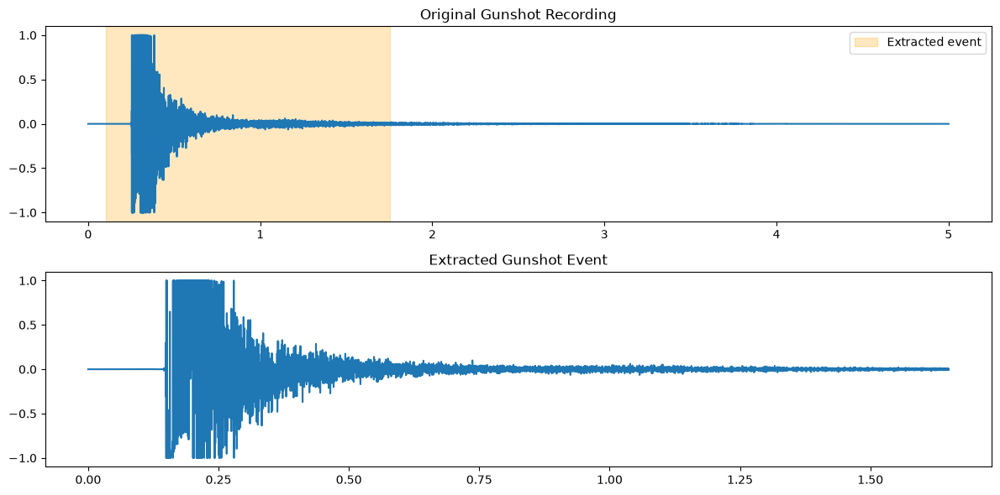


ORIGINAL AUDIO:



EXTRACTED EVENT:


In [36]:

import os
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Choose a gunshot from the training folds
gunshot_row = gunshot_sources.iloc[0]

path = os.path.join(
    audio_dir,
    gunshot_row["filename"]
)

original_audio, sr = sf.read(path)

if original_audio.ndim > 1:
    original_audio = original_audio.mean(axis=1)

# Find strongest peak
peak_index = np.argmax(np.abs(original_audio))

# Extract event using current V2 method
start = max(0, peak_index - int(0.15 * sr))
end = min(len(original_audio), peak_index + int(1.5 * sr))

extracted_event = original_audio[start:end]

print("GUNSHOT EXTRACTION INSPECTION")
print("=" * 55)
print("Original recording:", gunshot_row["filename"])
print("Original duration:", len(original_audio) / sr)
print("Extracted duration:", len(extracted_event) / sr)
print("Strongest peak:", peak_index / sr, "seconds")

# Compare waveforms
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

original_time = np.arange(len(original_audio)) / sr
event_time = np.arange(len(extracted_event)) / sr

axes[0].plot(original_time, original_audio)
axes[0].axvspan(
    start / sr,
    end / sr,
    color="orange",
    alpha=0.25,
    label="Extracted event"
)
axes[0].set_title("Original Gunshot Recording")
axes[0].legend()

axes[1].plot(event_time, extracted_event)
axes[1].set_title("Extracted Gunshot Event")

plt.tight_layout()
plt.show()

print("\nORIGINAL AUDIO:")
display(Audio(original_audio, rate=sr, normalize=False))

print("\nEXTRACTED EVENT:")
display(Audio(extracted_event, rate=sr, normalize=False))


In [38]:

import numpy as np

# Restore V1 whole-recording RMS mixing function

def mix_audio(threat_audio, background_audio, snr_db):

    threat = np.asarray(threat_audio, dtype=np.float32)
    background = np.asarray(background_audio, dtype=np.float32)

    # Match audio lengths
    length = min(len(threat), len(background))
    threat = threat[:length]
    background = background[:length]

    # Calculate RMS loudness
    def rms(x):
        return np.sqrt(np.mean(x.astype(np.float64) ** 2) + 1e-12)

    threat_rms = rms(threat)
    background_rms = rms(background)

    # Scale background to target whole-recording SNR
    background_scale = (
        threat_rms / background_rms
    ) * (10 ** (-snr_db / 20))

    # Mix audio
    mixed = threat + background * background_scale

    # Prevent clipping using common scaling
    peak = np.max(np.abs(mixed))

    if peak > 0.99:
        mixed = mixed * (0.99 / peak)

    return mixed.astype(np.float32)


print("SUCCESS: V1 mixing function restored!")


SUCCESS: V1 mixing function restored!


In [39]:

import os
import numpy as np
import soundfile as sf

# Use the gunshot we just inspected
gunshot_row = gunshot_sources.iloc[0]

# Select a rainforest background from the training folds
bg_row = background_sources.iloc[0]

gunshot_audio, sr = sf.read(
    os.path.join(audio_dir, gunshot_row["filename"])
)

background_audio, bg_sr = sf.read(
    os.path.join(audio_dir, bg_row["filename"])
)

assert sr == bg_sr

# Convert to mono
if gunshot_audio.ndim > 1:
    gunshot_audio = gunshot_audio.mean(axis=1)

if background_audio.ndim > 1:
    background_audio = background_audio.mean(axis=1)

# Ensure 5-second background
background_audio = np.asarray(
    background_audio[:5 * sr],
    dtype=np.float32
)

background_audio = np.pad(
    background_audio,
    (0, max(0, 5 * sr - len(background_audio)))
)

# Use one fixed gunshot position
rng = np.random.default_rng(42)

shifted, start_time = randomize_gunshot_timing(
    gunshot_audio,
    sr,
    rng=rng
)

# Mix using V1 whole-recording RMS
mixed_v1 = mix_audio(
    shifted,
    background_audio,
    snr_db=10
)

# Mix using V2 event-aware RMS
mixed_v2 = mix_gunshot_event_aware(
    shifted,
    background_audio,
    snr_db=10,
    event_start=start_time,
    sr=sr
)

print("MIXING METHOD COMPARISON")
print("=" * 55)

print("Gunshot start:", round(start_time, 2), "seconds")

print("\nV1 whole-recording mixing:")
print("Peak amplitude:", np.max(np.abs(mixed_v1)))

print("\nV2 event-aware mixing:")
print("Peak amplitude:", np.max(np.abs(mixed_v2)))

# Test both using V1 model
for name, audio in [
    ("V1 mixing", mixed_v1),
    ("V2 mixing", mixed_v2)
]:

    features = extract_augmented_mel(audio, sr)
    model_input = features[np.newaxis, ...]

    probs = best_finetuned_model.predict(
        model_input,
        verbose=0
    )[0]

    print(f"\n{name}")
    print("Background:", round(probs[0]*100, 1), "%")
    print("Chainsaw:", round(probs[1]*100, 1), "%")
    print("Gunshot:", round(probs[2]*100, 1), "%")
    print("Prediction:", ["BACKGROUND", "CHAINSAW", "GUNSHOT"][np.argmax(probs)])

print("\nMixing comparison complete!")


MIXING METHOD COMPARISON
Gunshot start: 0.3 seconds

V1 whole-recording mixing:
Peak amplitude: 0.99

V2 event-aware mixing:
Peak amplitude: 0.99

V1 mixing
Background: 11.6 %
Chainsaw: 12.2 %
Gunshot: 76.2 %
Prediction: GUNSHOT

V2 mixing
Background: 13.5 %
Chainsaw: 46.5 %
Gunshot: 40.0 %
Prediction: CHAINSAW

Mixing comparison complete!


In [40]:

import numpy as np

# Measure signal-to-noise ratio in the gunshot event window
# using the original components and each method's scaling rule.

def rms(x):
    x = np.asarray(x, dtype=np.float64)
    return np.sqrt(np.mean(x ** 2) + 1e-12)

start = int(round(start_time * sr))
end = min(start + int(1.65 * sr), len(shifted))

gunshot_event = shifted[start:end]
background_event = background_audio[start:end]

# V1: background scaled using whole-recording RMS
scale_v1 = (
    rms(shifted) / rms(background_audio)
) * 10 ** (-10 / 20)

# V2: background scaled using event-window RMS
scale_v2 = (
    rms(gunshot_event) / rms(background_event)
) * 10 ** (-10 / 20)

actual_snr_v1 = 20 * np.log10(
    rms(gunshot_event) /
    rms(background_event * scale_v1)
)

actual_snr_v2 = 20 * np.log10(
    rms(gunshot_event) /
    rms(background_event * scale_v2)
)

print("ACTUAL EVENT-WINDOW SNR COMPARISON")
print("=" * 50)

print(f"V1 mixing event SNR: {actual_snr_v1:.2f} dB")
print(f"V2 mixing event SNR: {actual_snr_v2:.2f} dB")

print(
    "Difference:",
    round(actual_snr_v1 - actual_snr_v2, 2),
    "dB"
)

print("\nSNR comparison complete!")


ACTUAL EVENT-WINDOW SNR COMPARISON
V1 mixing event SNR: 16.28 dB
V2 mixing event SNR: 10.00 dB
Difference: 6.28 dB

SNR comparison complete!


In [41]:

import numpy as np

# Reuse the same gunshot and background
# from our previous mixing comparison

class_names = ["BACKGROUND", "CHAINSAW", "GUNSHOT"]

print("EVENT-AWARE SNR SENSITIVITY TEST")
print("=" * 65)

for snr_db in [10, 15, 20, 25]:

    # Create event-aware mixture
    mixed = mix_gunshot_event_aware(
        shifted,
        background_audio,
        snr_db=snr_db,
        event_start=start_time,
        sr=sr
    )

    # Extract Mel features
    features = extract_augmented_mel(
        mixed,
        sr
    )

    model_input = features[np.newaxis, ...]

    # Test V1 model
    probs = best_finetuned_model.predict(
        model_input,
        verbose=0
    )[0]

    predicted = class_names[np.argmax(probs)]

    print(
        f"SNR {snr_db:+3d} dB | "
        f"Background: {probs[0]*100:5.1f}% | "
        f"Chainsaw: {probs[1]*100:5.1f}% | "
        f"Gunshot: {probs[2]*100:5.1f}% | "
        f"Predicted: {predicted}"
    )

print("\nSNR sensitivity test complete!")


EVENT-AWARE SNR SENSITIVITY TEST
SNR +10 dB | Background:  13.5% | Chainsaw:  46.5% | Gunshot:  40.0% | Predicted: CHAINSAW
SNR +15 dB | Background:  13.2% | Chainsaw:  21.4% | Gunshot:  65.4% | Predicted: GUNSHOT
SNR +20 dB | Background:   2.5% | Chainsaw:   1.7% | Gunshot:  95.8% | Predicted: GUNSHOT
SNR +25 dB | Background:   0.4% | Chainsaw:   1.1% | Gunshot:  98.5% | Predicted: GUNSHOT

SNR sensitivity test complete!


In [42]:

import os
import numpy as np
import pandas as pd
import soundfile as sf
import librosa

rng_test = np.random.default_rng(2028)

# Select five different training-fold gunshots
test_gunshots = gunshot_sources.sample(
    n=5,
    random_state=2028
)

test_results = []

for _, gunshot_row in test_gunshots.iterrows():

    bg_row = background_sources.iloc[
        int(rng_test.integers(len(background_sources)))
    ]

    gunshot_audio, sr = sf.read(
        os.path.join(audio_dir, gunshot_row["filename"])
    )

    bg_audio, bg_sr = sf.read(
        os.path.join(audio_dir, bg_row["filename"])
    )

    assert sr == bg_sr

    if gunshot_audio.ndim > 1:
        gunshot_audio = gunshot_audio.mean(axis=1)

    if bg_audio.ndim > 1:
        bg_audio = bg_audio.mean(axis=1)

    bg_audio = librosa.util.fix_length(
        bg_audio.astype(np.float32),
        size=5 * sr
    )

    # Keep timing fixed across SNRs for each gunshot
    shifted, start_time = randomize_gunshot_timing(
        gunshot_audio,
        sr,
        rng=rng_test
    )

    for snr_db in [10, 15, 20, 25]:

        mixed = mix_gunshot_event_aware(
            shifted,
            bg_audio,
            snr_db=snr_db,
            event_start=start_time,
            sr=sr
        )

        features = extract_augmented_mel(mixed, sr)

        probs = best_finetuned_model.predict(
            features[np.newaxis, ...],
            verbose=0
        )[0]

        test_results.append({
            "gunshot_source": gunshot_row["filename"],
            "snr_db": snr_db,
            "start_time": start_time,
            "gunshot_probability": float(probs[2]),
            "detected": int(np.argmax(probs)) == 2
        })

snr_test_results = pd.DataFrame(test_results)

print("MULTI-GUNSHOT SNR TEST")
print("=" * 55)

summary = snr_test_results.groupby("snr_db").agg(
    recordings=("detected", "count"),
    detected=("detected", "sum"),
    detection_rate=("detected", "mean"),
    average_gunshot_probability=(
        "gunshot_probability", "mean"
    )
)

summary["detection_rate"] *= 100
summary["average_gunshot_probability"] *= 100

print(summary.round(2))

print("\nTest complete!")


MULTI-GUNSHOT SNR TEST
        recordings  detected  detection_rate  average_gunshot_probability
snr_db                                                                   
10               5         3            60.0                        58.60
15               5         3            60.0                        56.63
20               5         2            40.0                        52.01
25               5         2            40.0                        44.14

Test complete!


In [43]:

import os
import tensorflow as tf

# Load the best V1 checkpoint
deployment_model = tf.keras.models.load_model(
    finetuned_path,
    compile=False
)

print("ESP32 DEPLOYMENT MODEL VERIFICATION")
print("=" * 55)

print("Model:", os.path.basename(finetuned_path))
print("Input shape:", deployment_model.input_shape)
print("Output shape:", deployment_model.output_shape)

print("\nParameter count:")
print(deployment_model.count_params())

print("\nModel file size:")
print(
    round(os.path.getsize(finetuned_path) / (1024 * 1024), 2),
    "MB"
)

print("\nClass mapping:")
print("0 = BACKGROUND")
print("1 = CHAINSAW")
print("2 = GUNSHOT")

assert deployment_model.input_shape == (None, 128, 196, 3)
assert deployment_model.output_shape == (None, 3)

print("\nSUCCESS: V1 deployment checkpoint verified!")


ESP32 DEPLOYMENT MODEL VERIFICATION
Model: MobileNetV3_Finetuned_V1_best.keras
Input shape: (None, 128, 196, 3)
Output shape: (None, 3)

Parameter count:
940851

Model file size:
4.13 MB

Class mapping:
0 = BACKGROUND
1 = CHAINSAW
2 = GUNSHOT

SUCCESS: V1 deployment checkpoint verified!


In [44]:

import os

project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

deployment_dir = os.path.join(
    project_dir,
    "models",
    "ESP32_Deployment_V1"
)

model_path = os.path.join(
    deployment_dir,
    "MobileNetV3_Rainforest_V1_INT8.tflite"
)

print("ESP32 MODEL FILE CHECK")
print("=" * 50)

if os.path.isfile(model_path):
    print("Model found!")
    print("Path:", model_path)
    print(
        "Model size:",
        round(os.path.getsize(model_path) / (1024 * 1024), 2),
        "MB"
    )
else:
    print("Model not found.")
    print("We need to convert the V1 Keras model to INT8.")

print("\nCheck complete!")


ESP32 MODEL FILE CHECK
Model not found.
We need to convert the V1 Keras model to INT8.

Check complete!


In [45]:

import os
import numpy as np
import tensorflow as tf

# ==========================================
# CONVERT V1 MODEL TO INT8
# ==========================================

project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

# Location of trained V1 model
keras_path = os.path.join(
    project_dir,
    "models",
    "MobileNetV3_Small_Rainforest_Finetuned_V1",
    "MobileNetV3_Finetuned_V1_best.keras"
)

# Create deployment folder
deployment_dir = os.path.join(
    project_dir,
    "models",
    "ESP32_Deployment_V1"
)

os.makedirs(deployment_dir, exist_ok=True)

tflite_path = os.path.join(
    deployment_dir,
    "MobileNetV3_Rainforest_V1_INT8.tflite"
)

# Prevent overwriting an existing model
if os.path.exists(tflite_path):
    raise FileExistsError(
        f"Deployment model already exists: {tflite_path}"
    )

# Load trained model
model = tf.keras.models.load_model(
    keras_path,
    compile=False
)

print("V1 Keras model loaded!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

# ==========================================
# REPRESENTATIVE CALIBRATION DATA
# ==========================================

# Use clean and V1 augmented training features
calibration_data = np.concatenate(
    [
        X_clean_train_v2,
        X_v1_train
    ],
    axis=0
)

rng = np.random.default_rng(42)

indices = rng.choice(
    len(calibration_data),
    size=min(150, len(calibration_data)),
    replace=False
)

def representative_dataset():
    for index in indices:
        sample = calibration_data[index:index+1]
        yield [sample.astype(np.float32)]

# ==========================================
# INT8 CONVERSION
# ==========================================

converter = tf.lite.TFLiteConverter.from_keras_model(
    model
)

converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

converter.representative_dataset = representative_dataset

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

print("\nConverting to INT8...")

tflite_model = converter.convert()

# ==========================================
# SAVE MODEL
# ==========================================

with open(tflite_path, "wb") as f:
    f.write(tflite_model)

print("\nINT8 CONVERSION COMPLETE")
print("=" * 50)

print("Saved to:", tflite_path)

print(
    "Model size:",
    round(len(tflite_model) / (1024 * 1024), 2),
    "MB"
)

print("\nSUCCESS: V1 INT8 model created!")


V1 Keras model loaded!
Input shape: (None, 128, 196, 3)
Output shape: (None, 3)

Converting to INT8...
INFO:tensorflow:Assets written to: /var/folders/nx/q5dd5n9117z5j7kcd6dwh_rh0000gn/T/tmp8lkvip0r/assets


INFO:tensorflow:Assets written to: /var/folders/nx/q5dd5n9117z5j7kcd6dwh_rh0000gn/T/tmp8lkvip0r/assets


Saved artifact at '/var/folders/nx/q5dd5n9117z5j7kcd6dwh_rh0000gn/T/tmp8lkvip0r'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 196, 3), dtype=tf.float32, name='input_layer_19')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  14043407056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043411664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043410320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043409744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043412240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043410704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043411856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043412048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043411088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043413200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14043412

/Users/charlieboggs/Forest-Sound-Analysis-on-Edge/.venv/lib/python3.11/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792698726.498247 5658801 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792698726.498550 5658801 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792698726.502397 5658801 reader.cc:83] Reading SavedModel from: /var/folders/nx/q5dd5n9117z5j7kcd6dwh_rh0000gn/T/tmp8lkvip0r
I0000 00:00:1792698726.509397 5658801 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792698726.509420 5658801 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/nx/q5dd5n9117z5j7kcd6dwh_rh0000gn/T/tmp8lkvip0r
I0000 00:00:1792698726.550643 5658801 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1792698726.558002 5658801 loader.cc:236] 


INT8 CONVERSION COMPLETE
Saved to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/ESP32_Deployment_V1/MobileNetV3_Rainforest_V1_INT8.tflite
Model size: 1.19 MB

SUCCESS: V1 INT8 model created!


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1792698731.774188 5658801 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.


In [46]:

import os
import numpy as np
import tensorflow as tf
from collections import Counter

# Load converted INT8 model
interpreter = tf.lite.Interpreter(
    model_path=tflite_path
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("ESP32 INT8 MODEL INSPECTION")
print("=" * 55)

for i, detail in enumerate(input_details):
    print(f"\nINPUT {i}")
    print("Shape:", detail["shape"])
    print("Data type:", detail["dtype"])
    print("Quantization:", detail["quantization"])

for i, detail in enumerate(output_details):
    print(f"\nOUTPUT {i}")
    print("Shape:", detail["shape"])
    print("Data type:", detail["dtype"])
    print("Quantization:", detail["quantization"])

# Inspect TensorFlow Lite operators
operations = interpreter._get_ops_details()

op_counts = Counter(
    op["op_name"] for op in operations
)

print("\nMODEL OPERATIONS")
print("=" * 55)

for name, count in sorted(op_counts.items()):
    print(f"{name}: {count}")

print("\nMODEL FILE SIZE")
print(
    round(os.path.getsize(tflite_path) / (1024 * 1024), 2),
    "MB"
)

print("\nInspection complete!")


ESP32 INT8 MODEL INSPECTION

INPUT 0
Shape: [  1 128 196   3]
Data type: <class 'numpy.int8'>
Quantization: (0.5427049994468689, 56)

OUTPUT 0
Shape: [1 3]
Data type: <class 'numpy.int8'>
Quantization: (0.00390625, -128)

MODEL OPERATIONS
ADD: 7
CONV_2D: 41
DELEGATE: 19
DEPTHWISE_CONV_2D: 11
FULLY_CONNECTED: 1
HARD_SWISH: 18
MEAN: 10
MUL: 19
SOFTMAX: 1

MODEL FILE SIZE
1.19 MB

Inspection complete!


/Users/charlieboggs/Forest-Sound-Analysis-on-Edge/.venv/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [47]:

import numpy as np
import tensorflow as tf

# ==========================================
# INT8 VS FLOAT32 MODEL COMPARISON
# ==========================================

# Load original V1 model
float_model = tf.keras.models.load_model(
    finetuned_path,
    compile=False
)

# Load INT8 model
int8_interpreter = tf.lite.Interpreter(
    model_path=tflite_path
)

int8_interpreter.allocate_tensors()

input_info = int8_interpreter.get_input_details()[0]
output_info = int8_interpreter.get_output_details()[0]

input_scale, input_zero = input_info["quantization"]
output_scale, output_zero = output_info["quantization"]

# Use clean and noisy validation examples
test_features = np.concatenate(
    [
        X_clean_val_v2[:30],
        X_noisy_val
    ],
    axis=0
)

float_probs = float_model.predict(
    test_features,
    verbose=0
)

int8_probs = []

for feature in test_features:

    # Quantize input
    quantized = np.clip(
        np.round(feature / input_scale + input_zero),
        -128,
        127
    ).astype(np.int8)

    quantized = quantized[np.newaxis, ...]

    # Run INT8 inference
    int8_interpreter.set_tensor(
        input_info["index"],
        quantized
    )

    int8_interpreter.invoke()

    output = int8_interpreter.get_tensor(
        output_info["index"]
    )[0]

    # Dequantize output
    probabilities = (
        output.astype(np.float32) - output_zero
    ) * output_scale

    int8_probs.append(probabilities)

int8_probs = np.asarray(int8_probs)

# ==========================================
# COMPARE PREDICTIONS
# ==========================================

float_predictions = np.argmax(float_probs, axis=1)
int8_predictions = np.argmax(int8_probs, axis=1)

agreement = np.mean(
    float_predictions == int8_predictions
)

mean_difference = np.mean(
    np.abs(float_probs - int8_probs)
)

max_difference = np.max(
    np.abs(float_probs - int8_probs)
)

print("INT8 QUANTIZATION ACCURACY TEST")
print("=" * 55)

print("Samples tested:", len(test_features))
print(f"Class agreement: {agreement*100:.2f}%")
print(f"Mean probability difference: {mean_difference:.6f}")
print(f"Maximum probability difference: {max_difference:.6f}")

print("\nQuantization comparison complete!")


INT8 QUANTIZATION ACCURACY TEST
Samples tested: 52
Class agreement: 96.15%
Mean probability difference: 0.032903
Maximum probability difference: 0.355612

Quantization comparison complete!


In [48]:

import os

# ==========================================
# CONVERT TFLITE MODEL TO C HEADER
# ==========================================

# Read the quantized model
with open(tflite_path, "rb") as f:
    model_bytes = f.read()

# Output header file
header_path = os.path.join(
    deployment_dir,
    "rainforest_model.h"
)

# Prevent accidental overwriting
if os.path.exists(header_path):
    raise FileExistsError(
        f"Header already exists: {header_path}"
    )

with open(header_path, "w") as f:

    f.write("#ifndef RAINFOREST_MODEL_H\n")
    f.write("#define RAINFOREST_MODEL_H\n\n")
    f.write("#include <stdint.h>\n\n")

    f.write("alignas(16) const unsigned char rainforest_model[] = {\n")

    for i in range(0, len(model_bytes), 12):

        chunk = model_bytes[i:i+12]

        line = ", ".join(
            f"0x{byte:02x}" for byte in chunk
        )

        f.write("    " + line)

        if i + 12 < len(model_bytes):
            f.write(",")

        f.write("\n")

    f.write("};\n\n")

    f.write(
        f"const unsigned int rainforest_model_len = {len(model_bytes)};\n\n"
    )

    f.write("#endif\n")

print("ESP32 MODEL HEADER CREATED")
print("=" * 50)

print("Header:", header_path)

print(
    "Original TFLite size:",
    round(len(model_bytes) / (1024 * 1024), 2),
    "MB"
)

print(
    "Header file size:",
    round(os.path.getsize(header_path) / (1024 * 1024), 2),
    "MB"
)

print("\nSUCCESS: Model ready for Arduino integration!")


ESP32 MODEL HEADER CREATED
Header: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/ESP32_Deployment_V1/rainforest_model.h
Original TFLite size: 1.19 MB
Header file size: 7.54 MB

SUCCESS: Model ready for Arduino integration!


In [1]:

import os
import numpy as np
import librosa

# ==========================================
# RAINFOREST ESP32 MEL FILTER BANKS
# ==========================================

project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

output_dir = os.path.join(
    project_dir,
    "models",
    "ESP32_Deployment_V1"
)

os.makedirs(output_dir, exist_ok=True)

SAMPLE_RATE = 20000
N_MELS = 128
FFT_SIZES = [2048, 1024, 512]
HOP_LENGTH = 512

print("GENERATING ESP32 MEL FILTER BANKS")
print("=" * 50)

for n_fft in FFT_SIZES:

    # Same Mel filter-bank defaults as librosa
    mel_filters = librosa.filters.mel(
        sr=SAMPLE_RATE,
        n_fft=n_fft,
        n_mels=N_MELS,
        htk=False,
        norm="slaney"
    ).astype(np.float32)

    filename = f"mel_filterbank_{n_fft}.npy"

    output_path = os.path.join(
        output_dir,
        filename
    )

    np.save(output_path, mel_filters)

    print(f"\nFFT size: {n_fft}")
    print("Filter shape:", mel_filters.shape)
    print("Minimum:", mel_filters.min())
    print("Maximum:", mel_filters.max())
    print("Saved:", filename)

    assert mel_filters.shape == (
        N_MELS,
        n_fft // 2 + 1
    )

    assert np.isfinite(mel_filters).all()

print("\nSUCCESS: All Mel filter banks generated!")


GENERATING ESP32 MEL FILTER BANKS

FFT size: 2048
Filter shape: (128, 1025)
Minimum: 0.0
Maximum: 0.039664723
Saved: mel_filterbank_2048.npy

FFT size: 1024
Filter shape: (128, 513)
Minimum: 0.0
Maximum: 0.039329894
Saved: mel_filterbank_1024.npy

FFT size: 512
Filter shape: (128, 257)
Minimum: 0.0
Maximum: 0.038755704
Saved: mel_filterbank_512.npy

SUCCESS: All Mel filter banks generated!


In [2]:

import os
import numpy as np

# ==========================================
# GENERATE ESP32 MEL FILTER HEADER
# ==========================================

project_dir = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

deployment_dir = os.path.join(
    project_dir,
    "models",
    "ESP32_Deployment_V1"
)

fft_sizes = [2048, 1024, 512]
n_mels = 128

header_path = os.path.join(
    deployment_dir,
    "mel_filterbanks.h"
)

print("GENERATING ESP32 MEL FILTER HEADER")
print("=" * 55)

with open(header_path, "w") as f:

    f.write("#ifndef MEL_FILTERBANKS_H\n")
    f.write("#define MEL_FILTERBANKS_H\n\n")
    f.write("#include <stdint.h>\n\n")

    f.write(
        "struct MelFilter {\n"
        "    uint16_t start;\n"
        "    uint16_t length;\n"
        "    uint32_t offset;\n"
        "};\n\n"
    )

    for n_fft in fft_sizes:

        path = os.path.join(
            deployment_dir,
            f"mel_filterbank_{n_fft}.npy"
        )

        filters = np.load(path)

        assert filters.shape == (
            n_mels,
            n_fft // 2 + 1
        )

        metadata = []
        coefficients = []

        for mel_index in range(n_mels):

            row = filters[mel_index]

            nonzero = np.flatnonzero(row)

            if len(nonzero) == 0:
                metadata.append(
                    (0, 0, len(coefficients))
                )
                continue

            start = int(nonzero[0])
            end = int(nonzero[-1]) + 1

            offset = len(coefficients)

            coefficients.extend(
                row[start:end].tolist()
            )

            metadata.append(
                (start, end - start, offset)
            )

        # Write filter metadata
        f.write(
            f"static const MelFilter "
            f"mel_filters_{n_fft}[128] = {{\n"
        )

        for start, length, offset in metadata:
            f.write(
                f"    {{{start}, {length}, {offset}}},\n"
            )

        f.write("};\n\n")

        # Write filter coefficients
        f.write(
            f"static const float "
            f"mel_coefficients_{n_fft}[] = {{\n"
        )

        for i in range(0, len(coefficients), 8):

            chunk = coefficients[i:i+8]

            line = ", ".join(
                f"{value:.9g}f"
                for value in chunk
            )

            f.write("    " + line + ",\n")

        f.write("};\n\n")

        print(f"\nFFT size: {n_fft}")
        print("Mel filters:", len(metadata))
        print("Stored coefficients:", len(coefficients))
        print("Dense coefficients:", filters.size)

    f.write("#endif\n")

print("\nHEADER GENERATION COMPLETE")
print("=" * 55)

print("Saved to:", header_path)

print(
    "Header size:",
    round(os.path.getsize(header_path) / 1024, 2),
    "KB"
)

print("\nSUCCESS: ESP32 Mel filter header created!")


GENERATING ESP32 MEL FILTER HEADER

FFT size: 2048
Mel filters: 128
Stored coefficients: 2019
Dense coefficients: 131200

FFT size: 1024
Mel filters: 128
Stored coefficients: 1009
Dense coefficients: 65664

FFT size: 512
Mel filters: 128
Stored coefficients: 505
Dense coefficients: 32896

HEADER GENERATION COMPLETE
Saved to: /Users/charlieboggs/Forest-Sound-Analysis-on-Edge/models/ESP32_Deployment_V1/mel_filterbanks.h
Header size: 63.81 KB

SUCCESS: ESP32 Mel filter header created!


In [16]:


import os
import numpy as np
import librosa
import sounddevice as sd
import tensorflow as tf
from IPython.display import Audio, display

# ==========================================
# LIVE MICROPHONE MODEL TEST ON MAC
# ==========================================

PROJECT_DIR = os.path.expanduser(
    "~/Forest-Sound-Analysis-on-Edge"
)

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "ESP32_Deployment_V1",
    "MobileNetV3_Rainforest_V1_INT8.tflite"
)

CLASS_NAMES = [
    "BACKGROUND",
    "CHAINSAW",
    "GUNSHOT"
]

SAMPLE_RATE = 20000
DURATION = 5

# ==========================================
# RECORD AUDIO
# ==========================================

print("Get your phone ready!")
input("Press Enter to start recording...")

print("\nRECORDING FOR 5 SECONDS!")
print("Play your sound now.")

audio = sd.rec(
    int(DURATION * SAMPLE_RATE),
    samplerate=SAMPLE_RATE,
    channels=1,
    dtype="float32"
)

sd.wait()

audio = audio.flatten()

print("\nRecording complete!")

print("Audio RMS:", np.sqrt(np.mean(audio**2)))
print("Peak amplitude:", np.max(np.abs(audio)))

display(Audio(audio, rate=SAMPLE_RATE, normalize=False))

# ==========================================
# GENERATE MEL FEATURES
# ==========================================

mel_channels = []

for n_fft in [2048, 1024, 512]:

    mel_power = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=n_fft,
        hop_length=512,
        n_mels=128,
        power=2.0,
        center=True,
        pad_mode="reflect"
    )

    mel_db = librosa.power_to_db(
        mel_power,
        ref=1.0,
        top_db=80
    )

    mel_channels.append(
        mel_db[:, :196]
    )

features = np.stack(
    mel_channels,
    axis=-1
).astype(np.float32)

print("\nMel shape:", features.shape)

# ==========================================
# LOAD INT8 MODEL
# ==========================================

interpreter = tf.lite.Interpreter(
    model_path=MODEL_PATH
)

interpreter.allocate_tensors()

input_info = interpreter.get_input_details()[0]
output_info = interpreter.get_output_details()[0]

input_scale, input_zero = input_info["quantization"]
output_scale, output_zero = output_info["quantization"]

# ==========================================
# QUANTIZE INPUT
# ==========================================

quantized = np.clip(
    np.round(features / input_scale + input_zero),
    -128,
    127
).astype(np.int8)

quantized = quantized[np.newaxis, ...]

# ==========================================
# RUN MODEL
# ==========================================

interpreter.set_tensor(
    input_info["index"],
    quantized
)

interpreter.invoke()

output = interpreter.get_tensor(
    output_info["index"]
)[0]

probabilities = (
    output.astype(np.float32) - output_zero
) * output_scale

# ==========================================
# PRINT RESULTS
# ==========================================

print("\nRAINFOREST LIVE CLASSIFICATION")
print("=" * 45)

for name, probability in zip(
    CLASS_NAMES,
    probabilities
):
    print(f"{name}: {probability * 100:.2f}%")

predicted_class = np.argmax(probabilities)

print("\nDETECTED:", CLASS_NAMES[predicted_class])



Get your phone ready!


Press Enter to start recording... 



RECORDING FOR 5 SECONDS!
Play your sound now.

Recording complete!
Audio RMS: 0.12684269
Peak amplitude: 0.9246065



Mel shape: (128, 196, 3)

RAINFOREST LIVE CLASSIFICATION
BACKGROUND: 0.00%
CHAINSAW: 99.61%
GUNSHOT: 0.00%

DETECTED: CHAINSAW
